# EDA2（fujise）: 気になったことの調査

`fujise_overview.ipynb` で全カラムの分布を見て、気になったことを 1 つずつ調べる。

In [1]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # グラフで日本語を表示する
import numpy as np
import pandas as pd
import seaborn as sns

TARGET = "取引価格（総額）"
KUBUN = "価格情報区分"

# 面積は "45" と "2,000㎡以上" が混ざっていて、数値と文字列が混在した列になるので、文字列でそろえる
train = pd.read_csv("../utokyo-mlapp-2026-ex1/train.csv", dtype={"面積（㎡）": str})
test = pd.read_csv("../utokyo-mlapp-2026-ex1/test.csv", dtype={"面積（㎡）": str})

for df in (train, test):
    df["面積_数値"] = pd.to_numeric(df["面積（㎡）"].str.replace("2,000㎡以上", "2000"))
    df["建築年_数値"] = pd.to_numeric(df["建築年"].str.extract(r"(\d{4})年")[0])
    period = df["取引時期"].str.extract(r"(\d{4})年第(\d)四半期").astype(int)
    df["時期_数値"] = period[0] + (period[1] - 1) / 4
train["㎡単価"] = train[TARGET] / train["面積_数値"]
train["面積帯"] = pd.cut(train["面積_数値"], [0, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 90, 100, 2000])
train["建築年帯"] = pd.cut(train["建築年_数値"], [1900, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2030])


def controlled_gap(df, col, keys):
    """keys が同じ行の平均と比べた log(㎡単価) の差を、col の値ごとに平均する。

    keys の組の中に col の値が 2 種類以上ある組だけを使う。1 種類しかない組では col の値どうしを比べられず、
    差が 0 の行として平均に混ざって、差を小さく見せてしまうため。

    Returns:
        値ごとの件数と差の表、col で説明できるばらつきの割合。
    """
    value = df[col].astype(object).where(df[col].notna(), "欠損")
    log_unit = np.log(df["㎡単価"])
    group = [df[k] for k in keys]
    resid = log_unit - log_unit.groupby(group, observed=True).transform("mean")
    mixed = value.groupby(group, observed=True).transform("nunique") >= 2
    resid, value = resid[mixed], value[mixed]
    explained = 1 - (resid - resid.groupby(value).transform("mean")).var() / resid.var()
    table = value.value_counts().rename("件数").to_frame()
    table["差"] = resid.groupby(value).mean()
    return table.round(3), explained


## Q1. `価格情報区分` とは何か

### 2 つの区分の出どころ

どちらも **実際に売買が成立した取引の価格** で、「まだ売れていない（売り出し中）」の物件は含まれない。違いはデータの集め方。

| 区分 | 出どころ | 集め方 |
|---|---|---|
| 不動産取引価格情報 | 国土交通省のアンケート調査 | 登記をもとに、売買の当事者にアンケートを送り、回答された価格を集める |
| 成約価格情報 | 指定流通機構（レインズ） | 不動産会社が仲介した取引の成約価格を、レインズに登録された情報から集める（国交省の「レインズ・マーケット・インフォメーション」で公表） |

出典
- 国土交通省「不動産情報ライブラリ」パンフレット（https://www.mlit.go.jp/tochi_fudousan_kensetsugyo/content/001992962.pdf ）: 「不動産取引価格情報: 国土交通省が実施するアンケート調査を通じ、実際の取引事例を収集」「成約価格情報: 指定流通機構（レインズ）が保有する不動産取引価格情報を…公表している情報」
- 同 FAQ（https://www.mlit.go.jp/tochi_fudousan_kensetsugyo/content/001992913.pdf ）: 「原典が異なる２種類の情報（アンケートおよび指定流通機構（レインズ）由来）」

集め方が違うので、次のような差が出ると予想できる。

- アンケートは調査票の項目が多いので、`用途`・`今後の利用目的`・`取引の事情等` のような項目はアンケート側にしかないのではないか
- レインズは不動産会社の仲介を通した取引だけなので、競売や身内の取引（`取引の事情等`）は入らないのではないか

以下でデータを見て確かめる。

### 件数と期間

In [2]:
pd.DataFrame(
    {
        "train": train[KUBUN].value_counts(),
        "train 割合": train[KUBUN].value_counts(normalize=True).round(3),
        "test": test[KUBUN].value_counts(),
        "test 割合": test[KUBUN].value_counts(normalize=True).round(3),
    }
)

,train,train 割合,test,test 割合
価格情報区分,,,,
不動産取引価格情報,111526,0.551,9595,0.327
成約価格情報,90797,0.449,19746,0.673


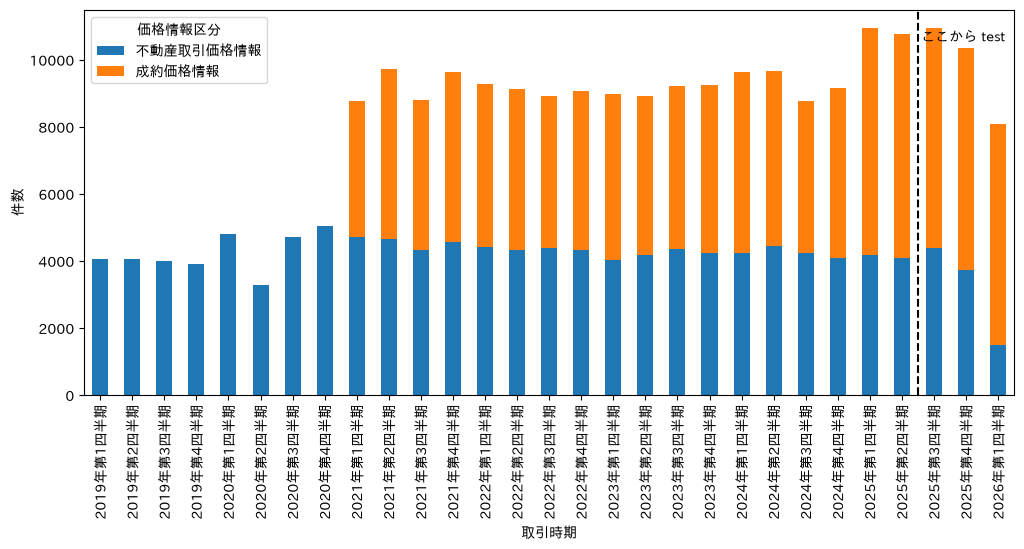

In [3]:
both = pd.concat([train.assign(データ="train"), test.assign(データ="test")])
counts = both.groupby(["時期_数値", "取引時期", KUBUN]).size().unstack(KUBUN).reset_index("時期_数値", drop=True)

fig, ax = plt.subplots(figsize=(12, 5))
counts.plot.bar(stacked=True, ax=ax)
ax.axvline(len(train["取引時期"].unique()) - 0.5, color="black", linestyle="--")
ax.text(len(train["取引時期"].unique()) - 0.4, ax.get_ylim()[1] * 0.95, "ここから test", va="top")
ax.set_xlabel("取引時期")
ax.set_ylabel("件数")
plt.show()

- 成約価格情報は **2021 年第 1 四半期から** しかない。2019〜2020 年は全部不動産取引価格情報。
- test 期間は成約価格情報が約 2/3 を占め、train 全体（約 45%）より多い。理由は 2 つある。
  - 2025 年に入って成約価格情報の件数が増えている
  - test の最後の四半期（2026 年第 1 四半期）は、不動産取引価格情報が約 1,500 件しかない。アンケートは回答が集まるまで時間がかかるので、まだ集計の途中なのだと思われる（推測）

### 欠損のしかたの違い

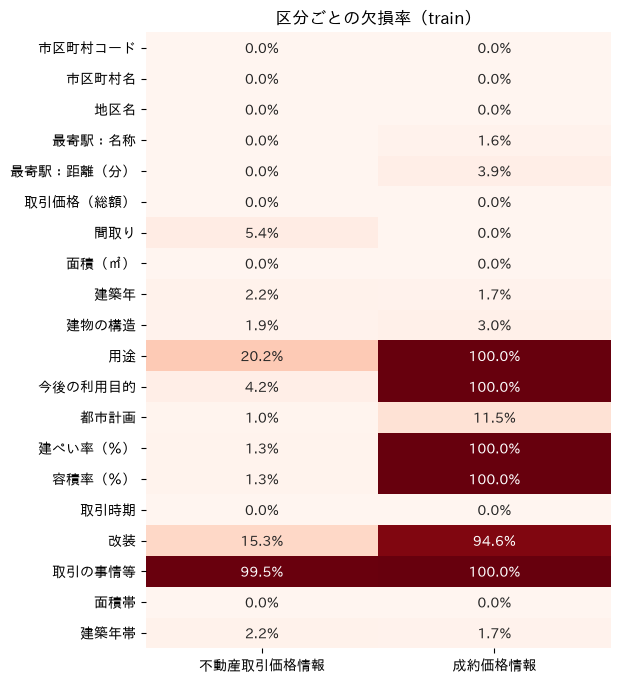

In [4]:
cols = [c for c in train.columns if c not in ("id", KUBUN, "面積_数値", "建築年_数値", "時期_数値", "㎡単価")]
missing = train.groupby(KUBUN)[cols].apply(lambda g: g.isna().mean()).T

fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(missing, annot=True, fmt=".1%", cmap="Reds", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title("区分ごとの欠損率（train）")
ax.set_xlabel("")
plt.show()

欠損のパターンがはっきり分かれる。

- `用途`・`今後の利用目的`・`建ぺい率（％）`・`容積率（％）`: 成約価格情報では **100% 欠損**。この 4 列はアンケートにしかない項目と考えられる。
- `取引の事情等`: 成約価格情報では 100% 欠損。
- `間取り`: 欠損はほぼ全部が不動産取引価格情報側（成約側は 2 件だけ）。
- `都市計画`: 成約価格情報の方が欠損が多い（約 11%）。

全体の欠損率（`用途` 56% など）の大部分は「成約価格情報だから項目がない」ことで説明できる。

### `改装` の値の違い

In [5]:
pd.crosstab(train["改装"].fillna("欠損"), train[KUBUN], margins=True)

価格情報区分,不動産取引価格情報,成約価格情報,All
改装,,,
改装済み,25231,4871,30102
未改装,69176,0,69176
欠損,17119,85926,103045
All,111526,90797,202323


成約価格情報には「未改装」が 1 件もなく、「改装済み」か欠損しかない。成約側の欠損は「未改装」か「不明」のどちらかで、アンケート側の欠損（不明）とは意味が違う可能性が高い。そのため、`改装` を使うときは区分と組み合わせて扱う必要がある。

### `取引の事情等` の違い

In [6]:
pd.crosstab(train["取引の事情等"].fillna("欠損"), train[KUBUN])

価格情報区分,不動産取引価格情報,成約価格情報
取引の事情等,,
その他事情有り,3,0
欠損,110917,90797
瑕疵有りの可能性,3,0
調停・競売等,516,0
関係者間取引,87,0


競売・関係者間取引などは全部不動産取引価格情報側にある。レインズは不動産会社の仲介を通した取引なので、こうした取引が入らないのと整合する。

### 物件の違い（面積・建築年・価格）

In [7]:
train.groupby(KUBUN)[[TARGET, "面積_数値", "建築年_数値", "㎡単価"]].median().round(0)

,取引価格（総額）,面積_数値,建築年_数値,㎡単価
価格情報区分,,,,
不動産取引価格情報,32000000.0,45.0,2004.0,920000.0
成約価格情報,48000000.0,65.0,2003.0,818182.0


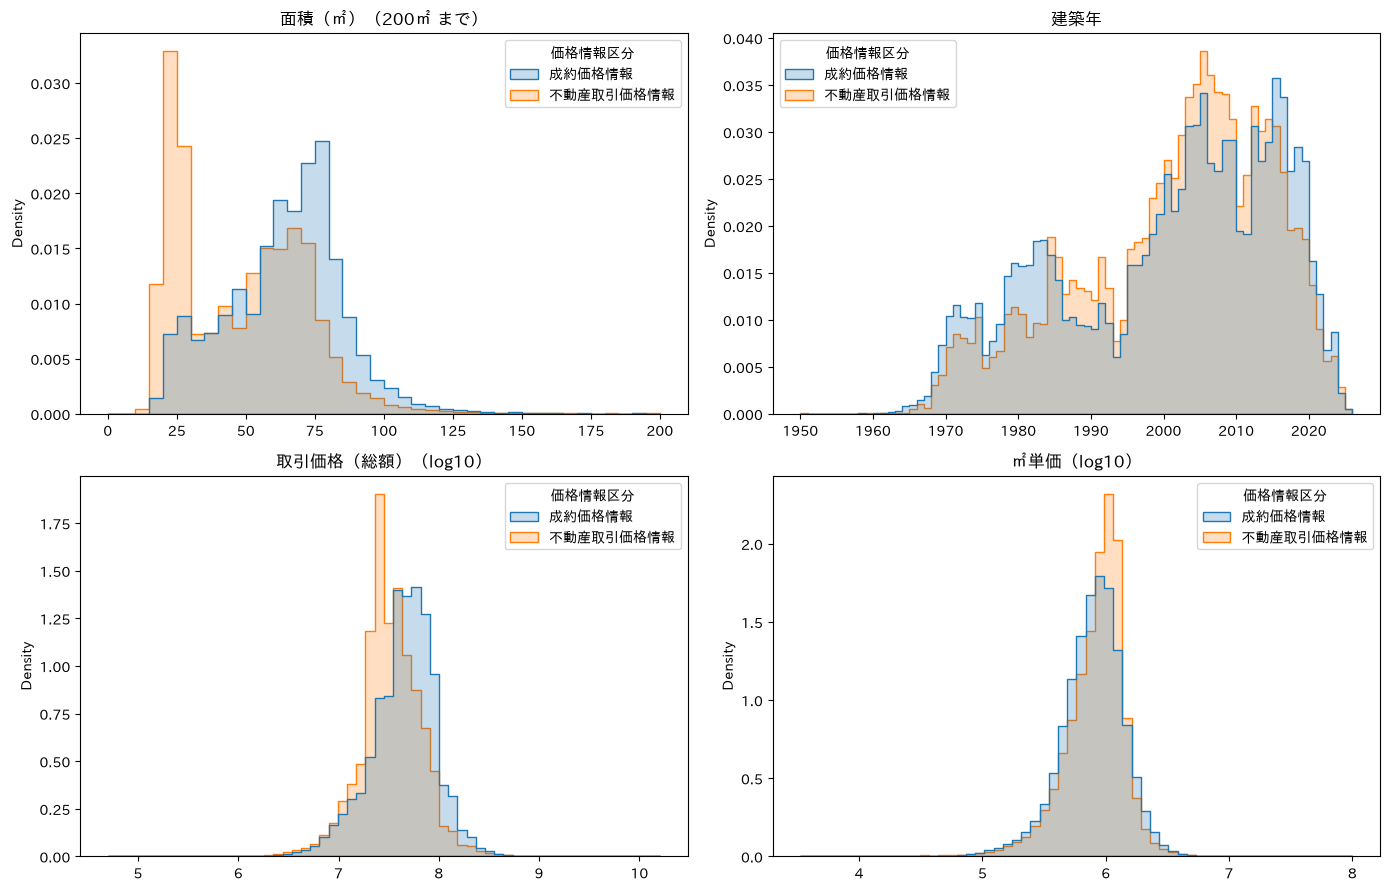

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
kw = dict(data=train, hue=KUBUN, stat="density", common_norm=False, element="step")

sns.histplot(x="面積_数値", binrange=(0, 200), binwidth=5, ax=axes[0, 0], **kw)
axes[0, 0].set_title("面積（㎡）（200㎡ まで）")

sns.histplot(x="建築年_数値", binwidth=1, ax=axes[0, 1], **kw)
axes[0, 1].set_title("建築年")

sns.histplot(x=np.log10(train[TARGET]), bins=60, ax=axes[1, 0], **kw)
axes[1, 0].set_title(f"{TARGET}（log10）")

sns.histplot(x=np.log10(train["㎡単価"]), bins=60, ax=axes[1, 1], **kw)
axes[1, 1].set_title("㎡単価（log10）")

for ax in axes.flat:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

件数の多さではなく分布の形を比べたいので、区分ごとに面積が 1 になるように正規化している（`common_norm=False`）。

- 面積: 不動産取引価格情報には 20〜30㎡ の物件（ワンルーム・１Ｋ）がとても多い。成約価格情報は 60〜80㎡（ファミリー向け）が多い。
- 建築年: 大きな差はない。
- 総額: 成約価格情報の方が高い。広い物件が多いことと整合する。
- ㎡単価: 不動産取引価格情報の方がやや高く、分布の幅は狭い。

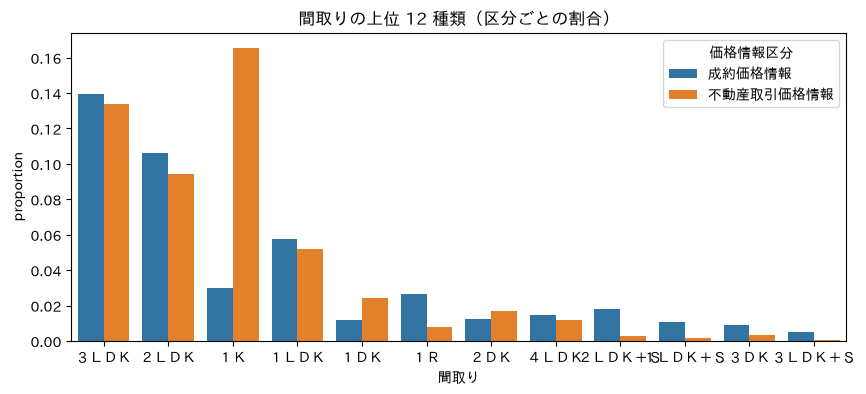

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(
    data=train,
    x="間取り",
    hue=KUBUN,
    order=train["間取り"].value_counts().index[:12],
    stat="proportion",
    ax=ax,
)
ax.set_title("間取りの上位 12 種類（区分ごとの割合）")
plt.show()

### 同じような物件でも価格は違うか

成約価格情報の方が総額は高いが、㎡単価は低い。これは成約側に広い物件（ファミリー向け）が多いせいかもしれない。物件の条件をそろえて比べるため、成約価格情報がある 2021 年以降に絞り、面積の帯ごとに㎡単価の中央値を比べる。

In [10]:
recent = train[train["時期_数値"] >= 2021].copy()
recent["面積帯"] = pd.cut(recent["面積_数値"], [0, 20, 30, 40, 50, 60, 70, 80, 100, 150, 2000])

by_area = recent.groupby(["面積帯", KUBUN], observed=True)["㎡単価"].median().unstack(KUBUN).round(-3)
by_area["成約 / 取引"] = (by_area["成約価格情報"] / by_area["不動産取引価格情報"]).round(3)
by_area["件数（取引）"] = recent[recent[KUBUN] == "不動産取引価格情報"].groupby("面積帯", observed=True).size()
by_area["件数（成約）"] = recent[recent[KUBUN] == "成約価格情報"].groupby("面積帯", observed=True).size()
by_area

価格情報区分,不動産取引価格情報,成約価格情報,成約 / 取引,件数（取引）,件数（成約）
面積帯,,,,,
"(0, 20]",1050000.0,620000.0,0.590,17119,3939
"(20, 30]",1040000.0,800000.0,0.769,12948,7092
"(30, 40]",1000000.0,914000.0,0.914,6713,7403
"(40, 50]",822000.0,840000.0,1.022,8115,9226
"(50, 60]",764000.0,891000.0,1.166,11524,15677
"(60, 70]",800000.0,814000.0,1.018,12352,18682
"(70, 80]",800000.0,800000.0,1.000,5197,17603
"(80, 100]",824000.0,778000.0,0.944,2672,8824
"(100, 150]",1120000.0,843000.0,0.753,883,2170


- 20㎡ 以下・20〜30㎡ の小さい物件では、不動産取引価格情報の㎡単価が成約価格情報よりかなり高い（105 万円 vs 62 万円など）。投資用のワンルームがアンケート側に多く入っているのかもしれない。
- 40〜80㎡ では差が小さい（50〜60㎡ だけは成約価格情報の方が約 17% 高い）。
- 100〜150㎡ では、また不動産取引価格情報の方が高い。

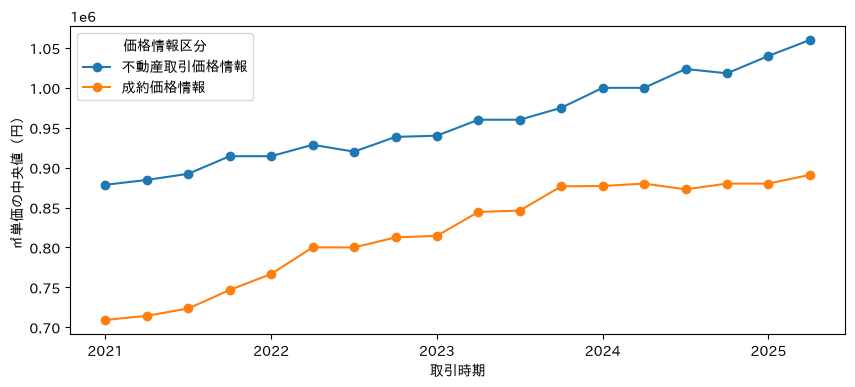

In [11]:
by_period = recent.groupby(["時期_数値", KUBUN])["㎡単価"].median().unstack(KUBUN)

fig, ax = plt.subplots(figsize=(10, 4))
by_period.plot(marker="o", ax=ax)
ax.set_xlabel("取引時期")
ax.set_ylabel("㎡単価の中央値（円）")
plt.show()

㎡単価の中央値は、どの時期でも不動産取引価格情報の方が 10〜20% 高い。ただしこれは小さい物件の割合の違いを含んだ比較。

面積帯をそろえても区分による差が残るかを、市区町村・面積帯・築年帯・取引時期をそろえたグループの中で比べて確かめる（グループ内で両区分が 10 件以上ずつあるものだけ）。

比べたグループ数: 378
log 価格の差（成約 − 取引）の中央値: -0.062  →  約 0.940 倍


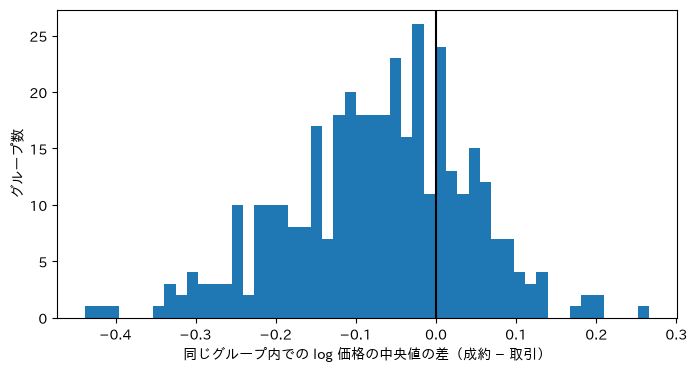

In [12]:
recent["築年帯"] = pd.cut(recent["時期_数値"] - recent["建築年_数値"], [-5, 5, 10, 20, 30, 40, 100])
recent["log価格"] = np.log(recent[TARGET])
keys = ["市区町村名", "面積帯", "築年帯", "取引時期"]

g = recent.groupby(keys + [KUBUN], observed=True)["log価格"].agg(["median", "size"]).unstack(KUBUN)
g = g[(g["size"] >= 10).all(axis=1)]
diff = g[("median", "成約価格情報")] - g[("median", "不動産取引価格情報")]

print(f"比べたグループ数: {len(diff)}")
print(f"log 価格の差（成約 − 取引）の中央値: {diff.median():.3f}  →  約 {np.exp(diff.median()):.3f} 倍")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(diff, bins=50)
ax.axvline(0, color="black")
ax.set_xlabel("同じグループ内での log 価格の中央値の差（成約 − 取引）")
ax.set_ylabel("グループ数")
plt.show()

市区町村・面積帯・築年帯・取引時期をそろえると、成約価格情報の方が少し安い（中央値で約 6%）。ただしグループによるばらつきが大きく、逆に成約の方が高いグループもある。「区分によって価格の水準が少し違う」くらいの差なので、区分を特徴量に入れておけばモデルが補正できる。

### 市区町村ごとの割合

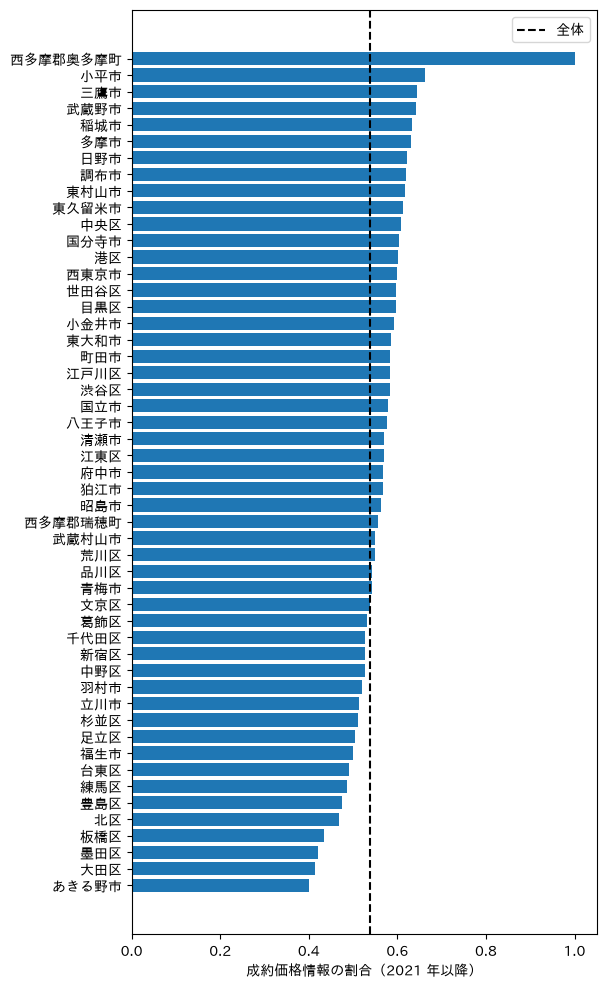

In [13]:
share = pd.crosstab(recent["市区町村名"], recent[KUBUN], normalize="index")["成約価格情報"].sort_values()

fig, ax = plt.subplots(figsize=(6, 12))
ax.barh(share.index, share.values)
ax.axvline(recent[KUBUN].eq("成約価格情報").mean(), color="black", linestyle="--", label="全体")
ax.set_xlabel("成約価格情報の割合（2021 年以降）")
ax.legend()
plt.show()

### 同じ取引が両方に入っていないか

出どころが違うので、同じ売買がアンケートとレインズの両方に入っている可能性がある。地区名・面積・建築年・間取り・取引時期・価格がすべて一致する組を数える。

In [14]:
dup_keys = ["地区名", "面積（㎡）", "建築年", "間取り", "取引時期", TARGET]
n_kubun = recent.groupby(dup_keys)[KUBUN].nunique()
print(f"両方の区分に同じ値の行がある組: {(n_kubun > 1).sum()} / {len(n_kubun)}")

両方の区分に同じ値の行がある組: 793 / 157728


価格まで完全に一致する組は約 800 あり、同じ取引が両方に入っている可能性がある。ただし同じマンションの同じタイプの部屋が同じ四半期に同じ価格で売れることもあるので、この数がそのまま重複の数とは言えない。全体（約 16 万組）から見ると 0.5% 程度なので、今のところ大きな問題ではない。

### 区分によって欠損する列の意味と、補完できるか

成約価格情報で欠損する列（と、逆に不動産取引価格情報で欠損する `間取り`）を、何を表す列かで分ける。

| 列 | 意味 | 何で決まるか | 成約価格情報での欠損 |
|---|---|---|---|
| `都市計画` | 用途地域。その土地に何を建ててよいかを法律で決めた区分（商業地域、第一種低層住居専用地域など） | **場所** | 約 11% |
| `建ぺい率（％）` | 敷地の面積のうち、建物を建ててよい面積（真上から見た面積）の上限 | **場所**（用途地域ごとに決まる） | 100% |
| `容積率（％）` | 敷地の面積に対する、建物の床面積の合計の上限。高いほど高い建物を建てられる | **場所**（用途地域ごとに決まる） | 100% |
| `用途` | 取引した時点での建物の使われ方（住宅・事務所・店舗など） | 物件・取引 | 100% |
| `今後の利用目的` | 買主が買ったあとにどう使うつもりか | 買主 | 100% |
| `改装` | 改装済みかどうか | 物件 | 95%（値は「改装済み」だけ） |
| `取引の事情等` | 競売・関係者間取引など、特別な事情 | 取引 | 100% |
| `間取り` | ３ＬＤＫ など | 物件 | 0%（逆に不動産取引価格情報で 5% 欠損） |

列の意味は、不動産情報ライブラリの API の項目名（https://www.reinfolib.mlit.go.jp/help/apiManual/xit001/ ）と、用途地域などの一般的な定義から整理した。

**場所で決まる列（`都市計画`・`建ぺい率`・`容積率`）なら、同じ場所の不動産取引価格情報の値から補完できる可能性がある。** 物件・取引・買主で決まる列は、場所から推測できないので補完できない。

場所で決まる 3 列について、本当に場所から決まるのかをデータで確かめる。価格は使わないので、train と test を合わせて見る。

In [15]:
both = pd.concat([train, test], ignore_index=True)
survey = both[both[KUBUN] == "不動産取引価格情報"]

pd.crosstab(survey["都市計画"], survey["建ぺい率（％）"])

建ぺい率（％）,30.0,40.0,50.0,60.0,80.0
都市計画,,,,,
商業,0,0,0,0,38484
工業,0,0,0,2566,0
工業専用,0,0,0,23,0
準住居,0,0,0,2227,2
準工業,0,0,29,21402,1185
近隣商業,0,0,0,44,16463
１中住専,0,1,984,13152,0
１低住専,30,587,1489,1845,0
１種住居,0,0,2,11965,253


`建ぺい率` は、ほぼ `都市計画` だけで決まる（商業・近隣商業なら 80%、工業・住居系なら 60% がほとんど）。`都市計画` が分かれば、`建ぺい率` を新しく足しても情報はあまり増えない。

In [16]:
pd.crosstab(survey["都市計画"], survey["容積率（％）"])

容積率（％）,60.0,80.0,100.0,150.0,200.0,300.0,400.0,500.0,600.0,700.0,800.0,1000.0
都市計画,,,,,,,,,,,,
商業,0,0,0,0,0,50,6187,17351,10744,3487,639,26
工業,0,0,0,1,2344,75,146,0,0,0,0,0
工業専用,0,0,0,0,23,0,0,0,0,0,0,0
準住居,0,0,0,0,281,1693,254,1,0,0,0,0
準工業,0,0,9,10,8145,10398,4036,18,0,0,0,0
近隣商業,0,0,26,3,601,9405,6432,40,0,0,0,0
１中住専,0,0,252,1069,10909,1885,12,10,0,0,0,0
１低住専,30,590,1271,1745,315,0,0,0,0,0,0,0
１種住居,0,0,0,27,5679,5343,1157,14,0,0,0,0


`容積率` は、同じ `都市計画` の中でも値がばらつく（商業地域だと 400〜1000%）。場所ごとに個別に決まっているので、もっと細かい場所（地区名）で見る必要がある。

不動産取引価格情報の中で、同じ場所（キー）の行どうしがどれくらい同じ値を持つかを測る。「最頻値で当たる割合」が高ければ、その場所の最頻値で補完しても大きくは外れない。

In [17]:
contract = both[both[KUBUN] == "成約価格情報"]


def check_imputable(col, keys):
    known = survey.dropna(subset=[col] + keys)
    groups = known.groupby(keys)[col]
    hit = groups.agg(lambda s: s.value_counts().iloc[0]).sum() / len(known)
    coverage = contract.set_index(keys).index.isin(groups.size().index).mean()
    return {"列": col, "キー": "＋".join(keys), "最頻値で当たる割合": round(hit, 3), "成約側で補完できる行": round(coverage, 3)}


pd.DataFrame(
    [
        check_imputable("都市計画", ["地区名"]),
        check_imputable("容積率（％）", ["地区名"]),
        check_imputable("容積率（％）", ["地区名", "都市計画"]),
        check_imputable("容積率（％）", ["地区名", "最寄駅：名称", "都市計画"]),
    ]
)

,列,キー,最頻値で当たる割合,成約側で補完できる行
0,都市計画,地区名,0.586,0.999
1,容積率（％）,地区名,0.583,0.999
2,容積率（％）,地区名＋都市計画,0.839,0.889
3,容積率（％）,地区名＋最寄駅：名称＋都市計画,0.880,0.859


- `容積率` は `地区名`＋`都市計画` で 8 割強が当たる。`地区名` だけだと 6 割弱。1 つの地区（町名）に複数の用途地域がまたがっているため。
- 「最頻値で当たる割合」は、補完に使うのと同じデータで測っているので、実際より少し甘い。
- `都市計画` を `地区名` から補完しても、6 割弱しか当たらない。成約側で `都市計画` が欠損している 11% の行は、`容積率` も `地区名` だけで補完することになり、精度が落ちる。

#### 補完できるかの判断

| 列 | 判断 | 理由 |
|---|---|---|
| `都市計画` | 難しい | 場所で決まるが、`地区名` だけでは 6 割弱しか当たらない（成約側の欠損は 11%） |
| `建ぺい率（％）` | できるが意味が薄い | ほぼ `都市計画` で決まるので、新しい情報にならない |
| `容積率（％）` | **できる（8 割程度）** | `地区名`＋`都市計画` でほぼ決まる。`都市計画` より細かい情報を持つ |
| `用途` / `今後の利用目的` | できない | 物件・買主ごとの情報。しかもほとんどが「住宅」 |
| `改装` / `取引の事情等` | できない | 物件・取引ごとの情報 |

補完して効くかどうかは、モデルで CV を比べないと分からない。`地区名` そのものも特徴量に入っているので、モデルがすでに場所の違いを学んでいるかもしれない。

### 欠損している列と価格の関係

補完する価値があるかは、その列が価格と関係しているかで決まる。値があるのは不動産取引価格情報の行だけなので、そこで見る。

log(㎡単価)（面積の違いを除くため）を、条件が同じ行の平均との差にして、列の値ごとに平均する（`controlled_gap`）。条件は 2 通り。

- **時期補正**: 同じ取引時期。場所の違いは含まれたまま
- **地区内**: 同じ `地区名`・同じ取引時期。場所の違いを取り除いたあと

「時期補正」で差があっても「地区内」で差が消えるなら、その列の情報は `地区名` がすでに持っている。補完しても新しい情報にはならない。

条件が同じ組の中に、列の値が 2 種類以上ある組だけを使う。値が 1 種類しかない組では比べようがなく、差 0 の行として混ざって差を小さく見せてしまうため。

容積率で説明できるばらつき: 時期補正 15.1% / 地区内 0.9%


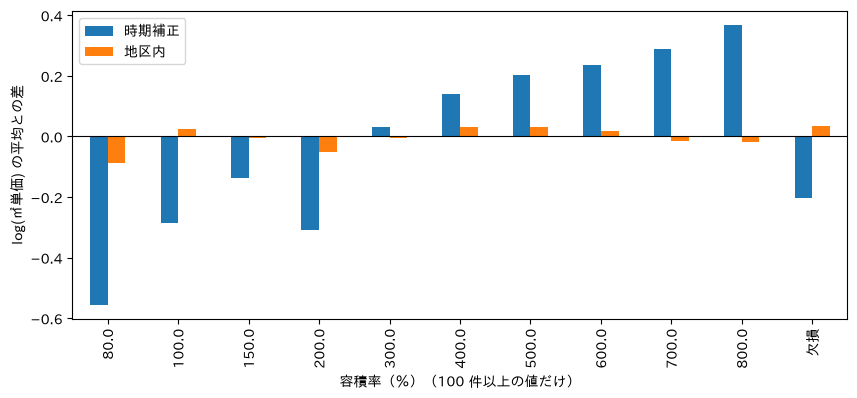

,件数,時期補正,地区内
容積率（％）,,,
80.0,555,-0.556,-0.087
100.0,1479,-0.287,0.025
150.0,2745,-0.137,-0.004
200.0,28426,-0.310,-0.051
300.0,28363,0.031,-0.005
400.0,18615,0.139,0.032
500.0,16090,0.204,0.030
600.0,9923,0.237,0.018
700.0,3222,0.288,-0.014


In [18]:
survey_train = train[train[KUBUN] == "不動産取引価格情報"]
TIME = ["取引時期"]
LOCATION = ["地区名", "取引時期"]

time_gap, time_expl = controlled_gap(survey_train, "容積率（％）", TIME)
loc_gap, loc_expl = controlled_gap(survey_train, "容積率（％）", LOCATION)
print(f"容積率で説明できるばらつき: 時期補正 {time_expl:.1%} / 地区内 {loc_expl:.1%}")

gap = time_gap.rename(columns={"差": "時期補正"})
gap["地区内"] = loc_gap["差"]
gap = gap[gap["件数"] >= 100]
gap = gap.loc[sorted(v for v in gap.index if v != "欠損") + ["欠損"]]

fig, ax = plt.subplots(figsize=(10, 4))
gap[["時期補正", "地区内"]].plot.bar(ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("容積率（％）（100 件以上の値だけ）")
ax.set_ylabel("log(㎡単価) の平均との差")
plt.show()
gap

- **時期補正**: 容積率が高いほど㎡単価が高い。200% と 800% では log で約 0.7 の差（約 2 倍）がある。容積率で説明できるばらつきは 15%。
- **地区内**: 同じ地区の中で比べると、差はほぼ消える。100 件以上ある値では、80%（−0.09）を除いて ±0.05 以内。説明できるばらつきは 0.9%。

つまり、容積率と価格の関係のほとんどは「容積率が高い場所 = 都心・商業地 = 高い」という場所の違いで、その情報は `地区名` がすでに持っている。

同じように、ほかの列も見る。

In [19]:
rows = []
for col in ["容積率（％）", "建ぺい率（％）", "都市計画", "用途", "今後の利用目的", "改装", "取引の事情等"]:
    _, time_expl = controlled_gap(survey_train, col, TIME)
    _, loc_expl = controlled_gap(survey_train, col, LOCATION)
    rows.append({"列": col, "時期補正": time_expl, "地区内": loc_expl})
pd.DataFrame(rows).set_index("列").style.format("{:.1%}").set_caption("列で説明できるばらつきの割合")

,時期補正,地区内
列,,
容積率（％）,15.1%,0.9%
建ぺい率（％）,6.7%,0.6%
都市計画,9.8%,0.7%
用途,0.2%,0.8%
今後の利用目的,0.0%,1.0%
改装,0.5%,0.1%
取引の事情等,0.5%,9.4%


In [20]:
for col in ["用途", "今後の利用目的", "改装", "取引の事情等"]:
    table, _ = controlled_gap(survey_train, col, LOCATION)
    display(table.rename_axis(col))

,件数,差
用途,,
住宅,49098,0.005
欠損,20020,-0.002
事務所,334,-0.259
店舗,238,-0.153
その他,177,-0.090
事務所、店舗,32,-0.369
駐車場,26,-1.019
倉庫,13,-0.471
住宅、事務所,10,-0.087


,件数,差
今後の利用目的,,
住宅,55306,0.014
その他,8529,-0.043
欠損,4455,-0.036
事務所,1161,-0.192
店舗,357,-0.102


,件数,差
改装,,
未改装,57225,-0.007
改装済み,23063,-0.002
欠損,16110,0.027


,件数,差
取引の事情等,,
欠損,4172,0.035
調停・競売等,462,-0.182
関係者間取引,86,-0.650
瑕疵有りの可能性,3,-1.221
その他事情有り,2,-0.301


| 列 | 説明できるばらつき（時期補正 → 地区内） | 地区内での差 | 補完できるか |
|---|---|---|---|
| `容積率（％）` | 15.1% → 0.9% | ほぼなし | できる（8 割） |
| `建ぺい率（％）` | 6.7% → 0.6% | ほぼなし | できる |
| `都市計画` | 9.8% → 0.7% | ほぼなし | 難しい |
| `用途` | 0.2% → 0.8% | 住宅以外は安い（事務所 −0.26、店舗 −0.15、駐車場 −1.0） | できない |
| `今後の利用目的` | 0.0% → 1.0% | 事務所にする買主は安く買っている（−0.19） | できない |
| `改装` | 0.5% → 0.1% | ほぼなし | できない |
| `取引の事情等` | 0.5% → 9.4% | 競売 −0.18、関係者間取引 −0.65 | できない |

`取引の事情等` の地区内 9.4% は、事情ありの行がある組（約 4,700 行）だけで測った値。全体から見ると、事情ありは約 600 件しかない。

場所で決まる列（容積率・建ぺい率・都市計画）は、どれも「地区内」で差が消える。価格への効き方は場所の違いを通したものだけなので、`地区名` があれば補完しなくてもよさそう。

場所とは別に価格への影響が残るのは `用途`・`今後の利用目的`・`取引の事情等` だが、どれも物件・取引・買主ごとの情報で補完できない。件数もごく少ない。

### Q1 のまとめ

- `価格情報区分` は「売れたかどうか」ではなく、**データの集め方の違い**。どちらも売買が成立した価格。
  - 不動産取引価格情報: 国交省のアンケート（2019 年〜）
  - 成約価格情報: レインズに登録された、不動産会社の仲介による成約（2021 年〜）
- `用途`・`今後の利用目的`・`建ぺい率（％）`・`容積率（％）`・`取引の事情等` は、成約価格情報では 100% 欠損。これらの列の欠損の大部分は区分で説明できる。
- 成約価格情報で欠損する列のうち、場所で決まる `容積率` は同じ場所の不動産取引価格情報から 8 割程度補完できそう。`用途`・`今後の利用目的`・`改装`・`取引の事情等` は補完できない。
  - ただし容積率と価格の関係は、同じ地区の中で比べるとほぼ消える。`地区名` が同じ情報を持っているので、補完の効果は小さそう。
- `改装` は、成約価格情報では「改装済み」か欠損しかない。欠損の意味が区分によって違う。
- 物件の傾向が違う。アンケート側は小さい物件（ワンルーム）が多く、成約側はファミリー向けが多い。
- 条件をそろえると、成約価格情報の方が価格が約 6% 低い傾向がある。
- test は成約価格情報が 67% で、train（45%）より多い。

モデルを作るときに気をつけること:

- `価格情報区分` は特徴量に入れる。
- 欠損を埋めるときは、区分ごとに考える。例えば成約価格情報の `建ぺい率` は「欠損」としておき、0 などで埋めない。

## Q2. `間取り` は順序（大きさ）をつけた方がよいか

`間取り` は価格と関係がありそう。ただ、１Ｋ < １ＬＤＫ < ２ＬＤＫ < ３ＬＤＫ のように「大きさ」の順があるので、ただのカテゴリ変数より、部屋数などの順序のある数値にした方がよいのではないか。

確かめたいのは次の 2 点。

1. `間取り` の「大きさ」の情報は、`面積（㎡）` とどれくらい重なっているか
2. 面積をそろえても、`間取り` によって価格は変わるか

In [21]:
TOP_MADORI = train["間取り"].value_counts().index[:14]
top = train[train["間取り"].isin(TOP_MADORI)]

top.groupby("間取り").agg(
    **{
        "件数": (TARGET, "size"),
        "価格の中央値": (TARGET, "median"),
        "面積の中央値": ("面積_数値", "median"),
        "㎡単価の中央値": ("㎡単価", "median"),
        "建築年の中央値": ("建築年_数値", "median"),
    }
).sort_values("面積の中央値").round(0)

,件数,価格の中央値,面積の中央値,㎡単価の中央値,建築年の中央値
間取り,,,,,
１Ｋ,39525,23000000.0,20.0,1040000.0,2006.0
１Ｒ,7026,16000000.0,20.0,714286.0,1987.0
１ＤＫ,7280,27000000.0,30.0,914286.0,2000.0
２Ｋ,872,19000000.0,35.0,533333.0,1981.0
１ＬＤＫ,22091,44000000.0,45.0,1050000.0,2005.0
２ＤＫ,5956,27000000.0,45.0,600000.0,1983.0
オープンフロア,641,36000000.0,50.0,760000.0,1986.0
３ＤＫ,2565,21000000.0,55.0,380000.0,1980.0
１ＬＤＫ＋Ｓ,2566,52000000.0,60.0,909091.0,2003.0


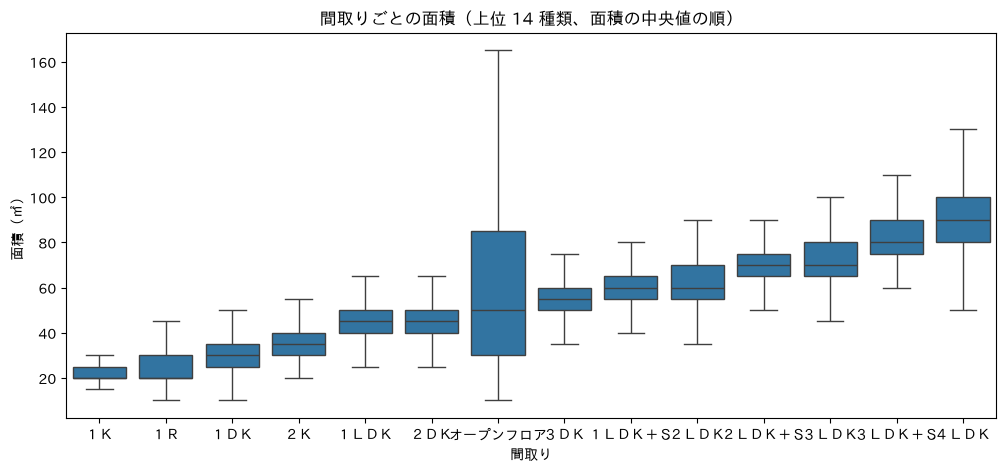

In [22]:
order = top.groupby("間取り")["面積_数値"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=top, x="間取り", y="面積_数値", order=order, showfliers=False, ax=ax)
ax.set_ylabel("面積（㎡）")
ax.set_title("間取りごとの面積（上位 14 種類、面積の中央値の順）")
plt.show()

- 部屋数が増えるほど面積も大きくなる。間取りの「大きさ」の情報は、ほとんど `面積（㎡）` が持っている。
- ただし価格の順は面積の順と一致しない。３ＤＫ は 55㎡ あるのに、価格の中央値は 2,100 万円で １Ｋ（20㎡）より安い。
- ３ＤＫ・２Ｋ・２ＤＫ・１Ｒ は、建築年の中央値が 1980 年代と古い。L（リビング）のない間取りは、古いマンションに多い。

つまり、間取りの違いには「大きさ」と「建物の古さ」の 2 つが混ざっている。

### 面積・場所・築年をそろえても、間取りで価格は変わるか

Q1 と同じ `controlled_gap` で、条件を 2 通りにして比べる。

- **場所＋面積**: 同じ `地区名`・取引時期・面積帯（5〜10㎡ 刻み）
- **場所＋面積＋築年**: さらに建築年の帯（5 年刻み）もそろえる

間取りで説明できるばらつき: 場所＋面積 7.1% / 場所＋面積＋築年 2.1%


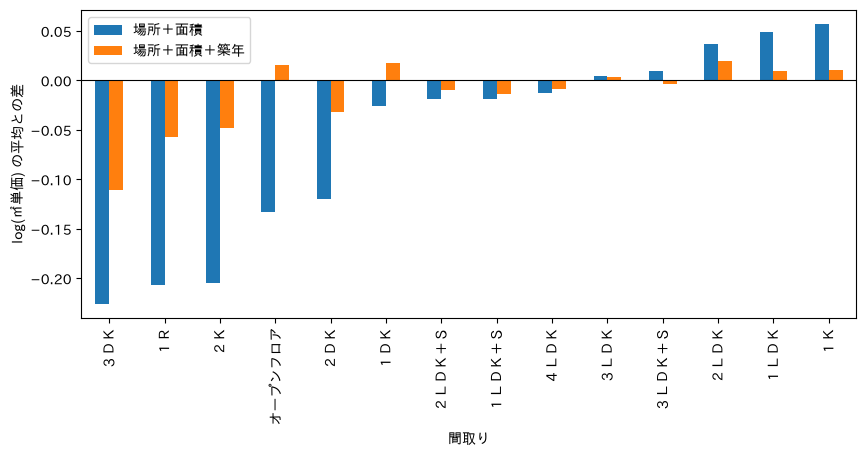

,場所＋面積,場所＋面積＋築年,件数（＋築年）
間取り,,,
３ＤＫ,-0.226,-0.111,573
１Ｒ,-0.207,-0.057,1874
２Ｋ,-0.205,-0.048,158
オープンフロア,-0.133,0.015,84
２ＤＫ,-0.120,-0.032,928
１ＤＫ,-0.026,0.017,1587
２ＬＤＫ＋Ｓ,-0.019,-0.010,1122
１ＬＤＫ＋Ｓ,-0.019,-0.014,592
４ＬＤＫ,-0.013,-0.009,819


In [23]:
SAME_SIZE = ["地区名", "取引時期", "面積帯"]
SAME_SIZE_AGE = ["地区名", "取引時期", "面積帯", "建築年帯"]

size_gap, size_expl = controlled_gap(train, "間取り", SAME_SIZE)
age_gap, age_expl = controlled_gap(train, "間取り", SAME_SIZE_AGE)
print(f"間取りで説明できるばらつき: 場所＋面積 {size_expl:.1%} / 場所＋面積＋築年 {age_expl:.1%}")

gaps = size_gap.loc[TOP_MADORI, ["差"]].rename(columns={"差": "場所＋面積"})
gaps["場所＋面積＋築年"] = age_gap["差"]
gaps["件数（＋築年）"] = age_gap["件数"]
gaps = gaps.sort_values("場所＋面積")

fig, ax = plt.subplots(figsize=(10, 4))
gaps[["場所＋面積", "場所＋面積＋築年"]].plot.bar(ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("log(㎡単価) の平均との差")
plt.show()
gaps

- **場所＋面積** をそろえると、３ＤＫ・１Ｒ・２Ｋ は約 2 割安い（−0.21〜−0.23）。２ＤＫ も約 1 割安い。
- **築年** までそろえると差は半分以下に縮むが、残る。３ＤＫ −0.11（約 1 割）、１Ｒ −0.06、２Ｋ −0.05、２ＤＫ −0.03。LDK の付く間取りは ±0.02 以内。
- 間取りで説明できるばらつきは 7.1% から 2.1% に減る。

L（リビング）のない間取りが安い理由の大半は「古い建物に多いから」だが、同じ築年でも少し安い。

### Q2 のまとめ

- 間取りの「大きさ」の情報は、ほとんど `面積（㎡）` が持っている。しかも価格は部屋数の順に並ばない（３ＤＫ は １ＬＤＫ より安い）ので、部屋数で順序をつける意味は薄い。
- 面積・築年をそろえても残るのは、「L があるか」「１Ｒ か １Ｋ か」のような**間取りの型**の違い。築年をそろえても ３ＤＫ は約 1 割安い。
- カテゴリ変数のままなら、LightGBM はこの型の違いを学べる。**今のままで十分**。部屋数や L・D・K・S の有無に分解すると、件数の少ない間取り（48 種類のうち多くは数件しかない）を似た型とまとめて扱える利点はあるが、優先度は低い。

## Q3. `建物の構造` と価格の関係

| 値 | 意味 |
|---|---|
| ＲＣ | 鉄筋コンクリート造 |
| ＳＲＣ | 鉄骨鉄筋コンクリート造。鉄骨の柱・梁のまわりを鉄筋コンクリートで固める。かつては高層の建物に多く使われた |
| 鉄骨造 | 鉄骨の柱・梁で組む |
| 軽量鉄骨造 | 薄い鉄骨で組む。低層の建物向け |
| 木造・ブロック造 | 低層の小さい建物 |
| 「ＳＲＣ、ＲＣ」など | 1 つの建物に複数の構造が混ざっている |

意味は建築の一般的な定義から整理した（データに説明はない）。

In [24]:
structure = train["建物の構造"].fillna("欠損")
train.groupby(structure).agg(
    **{
        "件数": (TARGET, "size"),
        "価格の中央値": (TARGET, "median"),
        "面積の中央値": ("面積_数値", "median"),
        "㎡単価の中央値": ("㎡単価", "median"),
        "建築年の中央値": ("建築年_数値", "median"),
        "容積率の中央値": ("容積率（％）", "median"),
    }
).sort_values("件数", ascending=False).round(0)

,件数,価格の中央値,面積の中央値,㎡単価の中央値,建築年の中央値,容積率の中央値
建物の構造,,,,,,
ＲＣ,148409,40000000.0,55.0,923077.0,2007.0,300.0
ＳＲＣ,47328,34000000.0,55.0,750000.0,1990.0,400.0
欠損,4763,29000000.0,50.0,800000.0,2000.0,300.0
鉄骨造,1535,23000000.0,45.0,550000.0,1982.0,300.0
ＳＲＣ、ＲＣ,132,34000000.0,55.0,600000.0,1993.0,300.0
軽量鉄骨造,64,57500000.0,75.0,869524.0,2016.0,200.0
ＲＣ、鉄骨造,54,43500000.0,55.0,800000.0,2002.0,300.0
木造,17,37000000.0,85.0,500000.0,1998.0,150.0
ＳＲＣ、鉄骨造,15,33000000.0,55.0,625000.0,1991.0,400.0


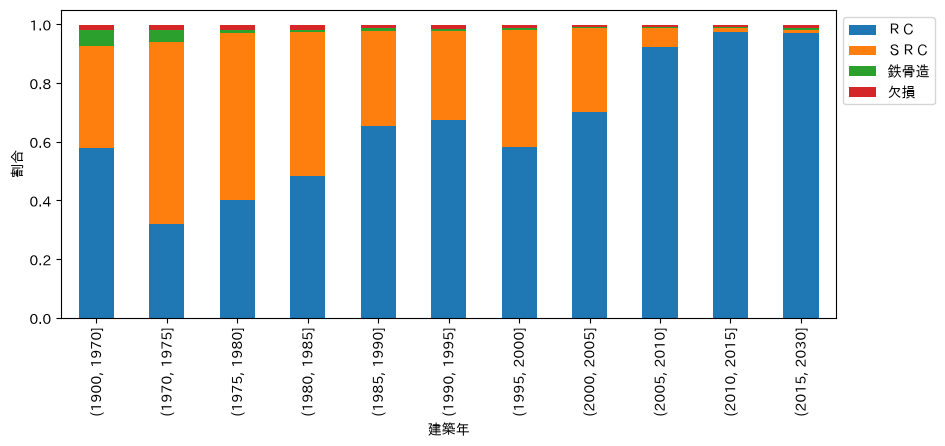

In [25]:
share = pd.crosstab(train["建築年帯"], structure, normalize="index")[["ＲＣ", "ＳＲＣ", "鉄骨造", "欠損"]]

fig, ax = plt.subplots(figsize=(10, 4))
share.plot.bar(stacked=True, ax=ax)
ax.set_xlabel("建築年")
ax.set_ylabel("割合")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

In [26]:
pd.crosstab(train["容積率（％）"], structure, normalize="index")[["ＲＣ", "ＳＲＣ"]].round(3)

建物の構造,ＲＣ,ＳＲＣ
容積率（％）,,
60.0,0.929,0.000
80.0,0.946,0.020
100.0,0.939,0.014
150.0,0.886,0.091
200.0,0.851,0.119
300.0,0.795,0.187
400.0,0.708,0.274
500.0,0.583,0.402
600.0,0.534,0.453


- ほとんどが ＲＣ（73%）と ＳＲＣ（23%）。
- ＳＲＣ は 1970〜2005 年の建物に多く（3〜6 割）、2005 年以降の建物はほぼ ＲＣ（9 割以上）。
- ＳＲＣ は容積率の高い場所（高い建物を建てられる場所）に多い。容積率 1000% では 96% が ＳＲＣ。
- 鉄骨造は古い建物が多い（建築年の中央値 1982 年）。

構造の違いには「建物の古さ」と「高い建物か」が混ざっている。Q2 と同じように、条件をそろえて価格を比べる。

建物の構造で説明できるばらつき: 時期 1.9% / 場所 7.4% / 場所＋面積 8.7% / 場所＋面積＋築年 0.7%


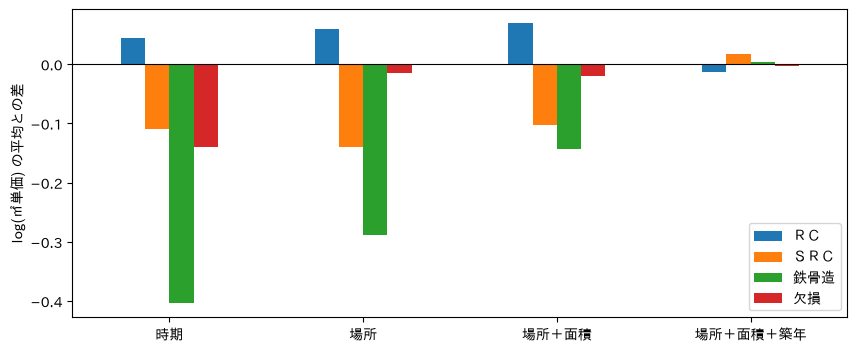

,時期,件数（時期）,場所,件数（場所）,場所＋面積,件数（場所＋面積）,場所＋面積＋築年,件数（場所＋面積＋築年）
ＲＣ,0.044,148409,0.060,113599,0.069,38196,-0.013,6291
ＳＲＣ,-0.110,47328,-0.140,45199,-0.102,24123,0.017,5002
鉄骨造,-0.404,1535,-0.288,1473,-0.144,817,0.003,244
欠損,-0.139,4763,-0.014,4616,-0.020,3026,-0.003,611


In [27]:
conditions = {
    "時期": ["取引時期"],
    "場所": ["地区名", "取引時期"],
    "場所＋面積": SAME_SIZE,
    "場所＋面積＋築年": SAME_SIZE_AGE,
}
MAIN_STRUCTURES = ["ＲＣ", "ＳＲＣ", "鉄骨造", "欠損"]
gaps = pd.DataFrame(index=MAIN_STRUCTURES)
explained = {}
for name, keys in conditions.items():
    table, explained[name] = controlled_gap(train, "建物の構造", keys)
    gaps[name] = table["差"]
    gaps[f"件数（{name}）"] = table["件数"]

print("建物の構造で説明できるばらつき: " + " / ".join(f"{k} {v:.1%}" for k, v in explained.items()))

fig, ax = plt.subplots(figsize=(10, 4))
gaps[list(conditions)].T.plot.bar(ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("log(㎡単価) の平均との差")
ax.tick_params(axis="x", rotation=0)
plt.show()
gaps.round(3)

- **時期だけ**: ＳＲＣ −0.11、鉄骨造 −0.40 と、ＲＣ より安く見える。
- **場所＋面積**: ＳＲＣ −0.10、鉄骨造 −0.14。まだ差がある。
- **場所＋面積＋築年**: 差はほぼ消える（ＳＲＣ +0.02、鉄骨造 0.00）。説明できるばらつきも 8.7% から 0.7% に減る。

ＳＲＣ や鉄骨造が安く見えるのは、古い建物に多いからだった。同じ築年なら差はほとんどない（ＳＲＣ の方がわずかに高い）。

### Q3 のまとめ

- `建物の構造` と価格の関係は、ほぼ築年数で説明できる。築年数はすでに特徴量に入っている。
- **カテゴリ変数のまま入れておけば十分**で、特別な処理は要らない。
- 木造・ブロック造・「ＳＲＣ、ＲＣ」などの複合は合わせて 300 件ほどしかなく、価格への影響は小さい。

## Q4. 1981 年の新耐震基準の前後で価格は変わるか

### 制度の確認

| 制度 | 内容 | 出典 |
|---|---|---|
| 新耐震基準 | **1981 年 6 月 1 日以降に建築確認を受けた建物**に適用される耐震の基準。旧基準は「震度 5 強程度で倒壊しない」、新基準は「震度 6 強〜7 程度でも倒壊しない」ことを想定 | 三井住友トラスト不動産 用語集 |
| 住宅ローン控除（2022 年以降に住み始めた場合） | 中古住宅は「**昭和 57 年（1982 年）1 月 1 日以後に建築されたもの**」なら対象。それより前の建物は、耐震基準に適合する証明が必要 | 国税庁 タックスアンサー No.1211-3 |
| 住宅ローン控除（2021 年までに住み始めた場合） | 中古住宅は「建築から取得まで 20 年（**マンションなど耐火建築物は 25 年**）以下」か、耐震基準に適合する証明が必要 | 国税庁 タックスアンサー No.1214 |
| フラット35（中古） | 建築確認日が 1981 年 6 月 1 日以後か。建築確認日が分からないときは、登記上の新築時期が **1983 年 4 月 1 日以後**か | 楽天銀行 フラット35 適合証明書の案内 |

- https://smtrc.jp/useful/glossary/detail/n/2510
- https://www.nta.go.jp/taxes/shiraberu/taxanswer/shotoku/1211-3.htm
- https://www.nta.go.jp/taxes/shiraberu/taxanswer/shotoku/1214.htm
- https://www.rakuten-bank.co.jp/home-loan/flat35/certificate.html

データの `建築年` は年だけで、建築確認の日ではない。マンションは建築確認から完成まで 1〜2 年以上かかるので、1981〜1983 年に完成した建物には旧基準と新基準が混ざっていると考えられる。フラット35 が新築時期の線を 1983 年 4 月にしているのも、このずれを見込んだものと思われる。

調べること:

1. 建築年ごとの価格に、1982〜1984 年あたりで段差があるか
2. 住宅ローン控除の条件が 2022 年に変わり、1982〜1996 年ごろに建った（築 25 年を超える）マンションも対象になった。train の期間（2019〜2025 年）の中で、この建物の価格が相対的に上がったか

### 建築年ごとの価格

`controlled_gap` で、同じ場所・取引時期・面積帯の中で比べる。ワンルームとファミリー向けで傾向が違ったので、30㎡ 以下と 30㎡ 超に分けて見る。

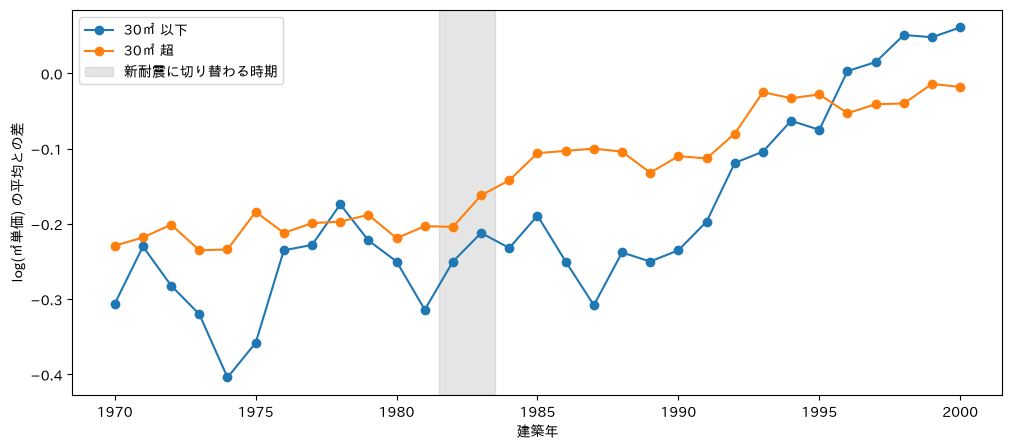

,30㎡ 以下,件数（30㎡ 以下）,30㎡ 超,件数（30㎡ 超）
1970,-0.306,110,-0.229,733
1971,-0.230,188,-0.218,690
1972,-0.282,161,-0.201,777
1973,-0.320,165,-0.235,633
1974,-0.404,332,-0.234,871
1975,-0.358,120,-0.184,482
1976,-0.235,210,-0.212,538
1977,-0.228,223,-0.199,718
1978,-0.174,272,-0.197,1108
1979,-0.222,324,-0.188,1242


In [28]:
YEARS = range(1970, 2001)
by_year = pd.DataFrame(index=YEARS)
for name, rows in {"30㎡ 以下": train["面積_数値"] <= 30, "30㎡ 超": train["面積_数値"] > 30}.items():
    table, _ = controlled_gap(train[rows], "建築年_数値", SAME_SIZE)
    by_year[name] = table["差"]
    by_year[f"件数（{name}）"] = table["件数"]

fig, ax = plt.subplots(figsize=(12, 5))
by_year[["30㎡ 以下", "30㎡ 超"]].plot(marker="o", ax=ax)
ax.axvspan(1981.5, 1983.5, color="gray", alpha=0.2, label="新耐震に切り替わる時期")
ax.set_xlabel("建築年")
ax.set_ylabel("log(㎡単価) の平均との差")
ax.legend()
plt.show()
by_year.round(3)

**30㎡ 超（ファミリー向け）では、新耐震の時期に段差がある。**

- 1970〜1982 年の建物は、ほぼ同じ水準（−0.20 前後）で、古くなるほど安いという傾向はほとんどない。
- 1983〜1985 年にかけて上がり（−0.20 → −0.11）、そのあと 1991 年までまた横ばいになる。
- 段差は log で約 0.1（約 1 割）。新耐震の建物が完成し始める時期（1983 年ごろ）と一致する。

ただし、この時期に変わったのは耐震基準だけではないので、段差が全部新耐震のせいとは言い切れない。

**30㎡ 以下（ワンルーム）では、1983 年の段差は見えない。**

- 1990 年ごろまで −0.2〜−0.3 で低いまま、1992〜1996 年に大きく上がる。
- 1980 年代後半〜1991 年（バブル期）に建てられたワンルームが特に安い。この時期の建物は 1Ｋ・1Ｒ の割合が高く（1988〜1992 年で 4 割前後。1995 年以降は 1 割前後）、投資用のワンルームマンションが多く建った時期だと考えられる（推測）。

30㎡ 超でも 1992〜1993 年に 2 つ目の段差（−0.11 → −0.03）がある。理由は分からない。

### 2022 年の住宅ローン控除の変更で、価格は変わったか

建築年で 3 つに分け、2021 年までの取引と 2022 年以降の取引で比べる。

| 建築年 | 2021 年まで | 2022 年以降 |
|---|---|---|
| 〜1981 年 | 証明がないと対象外 | 証明がないと対象外 |
| 1982〜1996 年 | 築 25 年を超えると、証明がないと対象外 | **対象になる** |
| 1997 年〜 | ほぼ築 25 年以内で対象 | 対象 |

1982〜1996 年の建物だけが 2022 年に新しく対象になったので、価格が上がるとしたらこのグループ。

In [29]:
train["取引年"] = train["時期_数値"].astype(int)
train["控除の変更"] = np.where(train["取引年"] <= 2021, "2021 年まで", "2022 年以降")
train["建築年の区分"] = pd.cut(train["建築年_数値"], [1900, 1981, 1996, 2030], labels=["〜1981", "1982〜1996", "1997〜"])

table = {}
for era, rows in train.groupby("控除の変更"):
    gap, _ = controlled_gap(rows, "建築年の区分", SAME_SIZE)
    table[era] = gap["差"]
table = pd.DataFrame(table).loc[["〜1981", "1982〜1996", "1997〜"]]
table["変化"] = table["2022 年以降"] - table["2021 年まで"]
table.round(3)

,2021 年まで,2022 年以降,変化
建築年の区分,,,
〜1981,-0.240,-0.274,-0.034
1982〜1996,-0.170,-0.165,0.005
1997〜,0.154,0.173,0.019


| 建築年 | 変化（2022 年以降 − 2021 年まで） |
|---|---|
| 〜1981 年 | −0.034 |
| 1982〜1996 年 | +0.005 |
| 1997 年〜 | +0.019 |

**1982〜1996 年の建物が相対的に上がった様子はない**（1997 年〜の方が上がっている）。目立つのは、〜1981 年の建物が相対的に安くなったこと。ただしこれは、ローン控除とは関係なく「古い建物ほど年々評価が下がっている」だけかもしれず、区別できない。

### Q4 のまとめ

- **新耐震（1981 年）の前後で、ファミリー向けでは約 1 割の段差がある。** 1983〜1985 年完成の建物から上がる。ワンルームでは見えない。
- 住宅ローン控除の 2022 年の変更による価格の変化は、データからは見えない。
- モデルには `建築年_数値` と `築年数` が数値で入っているので、決定木は「1983 年より前か」で分けられる。新耐震かどうかの列を足さなくても、段差は学べるはず。足すとしても優先度は低い。
- 1980 年代後半〜1991 年のワンルームが安いことも、`建築年_数値` と `面積_数値` の組み合わせとして決定木が学べる。

## Q5. `用途`・`今後の利用目的`・`都市計画`・`建ぺい率`・`容積率` の関係

5 列とも値があるのは不動産取引価格情報の行だけなので、そこで見る（価格は使わないので train と test を合わせる）。

### 互いにどれくらい決まるか

「行の列 A の値が分かったとき、列 B の値をどれくらい当てられるか」を測る。A の値ごとに B の最頻値を答えたときに当たる割合で、一番下の行の「何も知らない」（B 全体の最頻値を答える）より高ければ、A は B の情報を持っている。

相関係数ではなくこの方法にしたのは、カテゴリの列が多いのと、向きによって答えが違う（都市計画から建ぺい率は分かるが、逆は分からない）ため。

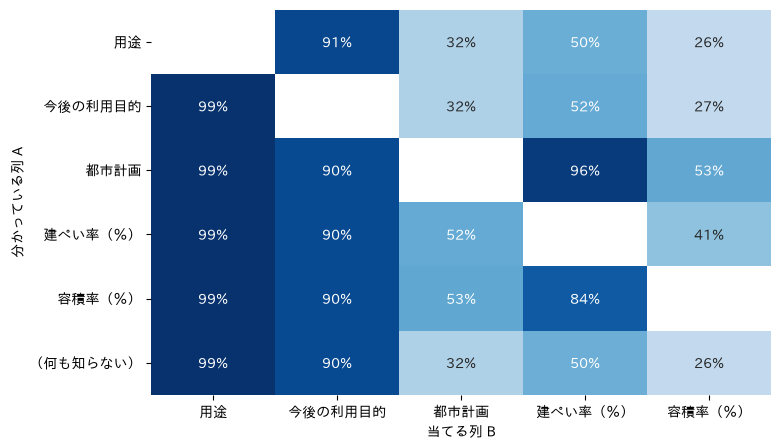

In [30]:
RELATED = ["用途", "今後の利用目的", "都市計画", "建ぺい率（％）", "容積率（％）"]


def hit_rate(df, a, b):
    rows = df[[a, b]].dropna()
    return rows.groupby(a)[b].agg(lambda s: s.value_counts().iloc[0]).sum() / len(rows)


hits = pd.DataFrame(
    [[hit_rate(survey, a, b) if a != b else np.nan for b in RELATED] for a in RELATED],
    index=RELATED,
    columns=RELATED,
)
hits.loc["（何も知らない）"] = [survey[b].value_counts(normalize=True).iloc[0] for b in RELATED]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(hits, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_xlabel("当てる列 B")
ax.set_ylabel("分かっている列 A")
plt.show()

- **都市計画 → 建ぺい率: 96%**（何も知らないと 50%）。建ぺい率はほぼ都市計画で決まる。逆の建ぺい率 → 都市計画は 52% で、半分ほどしか当たらない（建ぺい率 60% の用途地域がたくさんあるため）。
- **容積率 → 建ぺい率: 84%**。容積率が分かれば、建ぺい率もだいたい分かる。
- **都市計画 → 容積率: 53%**（何も知らないと 26%）。容積率は都市計画である程度決まるが、同じ用途地域の中でも場所によって違う。
- **用途 ↔ 今後の利用目的**: 当たる割合は「何も知らない」とほとんど同じ（90%・99%）。ほとんどの行が「住宅」なので、何も知らなくても「住宅」と答えれば当たってしまうため。住宅以外の行に絞ると関係が見える（下の表）。
- **用途・今後の利用目的 ↔ 都市計画・建ぺい率・容積率**: ほぼ無関係。

In [31]:
non_housing = survey[survey["用途"].notna() & (survey["用途"] != "住宅")]
pd.DataFrame(
    {
        "住宅以外の用途": non_housing["都市計画"].value_counts(normalize=True),
        "全体": survey["都市計画"].value_counts(normalize=True),
    }
).sort_values("全体", ascending=False).head(8).round(2)

,住宅以外の用途,全体
都市計画,,
商業,0.59,0.32
準工業,0.09,0.19
近隣商業,0.16,0.14
１中住専,0.05,0.12
１種住居,0.05,0.10
２種住居,0.02,0.03
１低住専,0.01,0.03
工業,0.00,0.02


In [32]:
pd.crosstab(non_housing["用途"], non_housing["今後の利用目的"].fillna("欠損")).loc[lambda t: t.sum(axis=1) >= 10]

今後の利用目的,その他,事務所,住宅,店舗,欠損
用途,,,,,
その他,192,0,4,4,2
事務所,23,323,38,18,12
事務所、店舗,4,7,4,15,3
住宅、事務所,1,3,6,0,0
倉庫,6,3,3,2,0
店舗,21,15,4,228,14
駐車場,25,1,4,0,2


- 住宅以外の用途の物件は、**商業地域に多い**（59%。全体では 32%）。
- 住宅以外の用途では、今後の利用目的も同じになりやすい（店舗 → 店舗 228 件、事務所 → 事務所 323 件）。駐車場・倉庫などは「その他」が多い。

### 関係のある特徴量の扱い方

#### 決定木（LightGBM）では、関係のある列をそのまま入れても大きな問題はない

線形回帰では、関係の強い列を一緒に入れると係数が不安定になる（多重共線性）。決定木は 1 回の分岐で 1 つの列しか見ないので、この問題は起きにくい。都市計画と建ぺい率のどちらで分けても同じなら、どちらかが選ばれるだけ。

ただし、次の点には注意する。

| 起きること | 影響 |
|---|---|
| 重要度が分散する | 同じ情報が 2 列にあると、重要度が 2 列に分かれて、それぞれ小さく見える。「重要度が低いから要らない」と判断しない |
| 列が増える | 新しい情報を持たない列が増えると、たまたまの分岐（過学習）の機会が少し増える。ただし影響は小さいことが多い |

#### よく使う手

| 手 | どんなときに | この 5 列での例 |
|---|---|---|
| **そのまま全部入れる** | まずはこれ。決定木なら困らないことが多い | 今の `src/features/base.py` はこれ |
| **重複した列を落とす** | ほかの列からほぼ完全に決まる列 | 建ぺい率は都市計画から 96% 当たるので落とせる。ただし落としても精度はほとんど変わらないはず |
| **組み合わせて新しい列を作る** | 2 列の組み合わせに意味があるが、決定木が何回も分岐しないと表せないとき | 容積率 ÷ 建ぺい率 = 建てられる階数の目安（容積率 500%・建ぺい率 80% なら 6.25 階分）。決定木は割り算を直接は表せない |
| **まばらなカテゴリをまとめる** | 件数がごく少ない値がたくさんあるとき | 用途 17 種類 → 「住宅か、それ以外か」。今後の利用目的と合わせて「住宅以外が関わる取引か」 |
| **主成分分析などで圧縮する** | 数値の列がたくさんあって、互いに強く相関しているとき | 今回は列が少なく、カテゴリが多いので向かない |

どの手も、効くかどうかは CV で比べるまで分からない（効かないことも多い）。

#### この 5 列についての見立て

- Q1 で見たとおり、都市計画・建ぺい率・容積率と価格の関係は、`地区名` をそろえるとほぼ消える。組み合わせの列（階数の目安）を作っても、新しい情報は少ないと思われる。しかも成約価格情報（test の 67%）では 3 列とも欠損（都市計画は 11%）なので、作っても使える行が少ない。
- 用途・今後の利用目的の「住宅以外」は、場所だけそろえると安く見える（Q1: 事務所 −0.26、駐車場 −1.0 など）。ただし Q6 で見るとおり、築年までそろえると駐車場・倉庫以外の差はほぼ消える。まばらなカテゴリをまとめる手も、効果はほとんどないと思われる。

### Q5 のまとめ

- 5 列は 2 つのまとまりに分かれる。
  - **場所の決まり**: 都市計画・建ぺい率・容積率。都市計画から建ぺい率はほぼ決まる（96%）。容積率は半分ほど。
  - **使い方**: 用途・今後の利用目的。ほぼ全部が住宅で、住宅以外は少ない。住宅以外どうしは同じ値になりやすい（店舗 → 店舗など）。
- 2 つのまとまりの間はほぼ無関係。ただし住宅以外の用途は商業地域に多い（59%。全体では 32%）。
- 決定木なら、関係のある列をそのまま入れても大きな問題はない。重要度が分散して見えることだけ注意する。
- 「住宅以外の用途か」にまとめる列も、Q6 の結果から効果はほとんどないと思われる。

## Q6. `用途`・`今後の利用目的` を詳しく

| 列 | 意味 |
|---|---|
| `用途` | 取引した時点で、その部屋がどう使われていたか（住宅・事務所・店舗・駐車場など） |
| `今後の利用目的` | 買主が、買ったあとにどう使うつもりか（住宅・事務所・店舗・その他） |

どちらもアンケートの回答なので、不動産取引価格情報の行にしかない。

In [33]:
pd.concat(
    {
        "用途": survey_train["用途"].fillna("欠損").value_counts(),
        "今後の利用目的": survey_train["今後の利用目的"].fillna("欠損").value_counts(),
    },
    axis=1,
).fillna(0).astype(int).sort_values("用途", ascending=False)

,用途,今後の利用目的
住宅,88075,96246
欠損,22556,4715
事務所,365,1261
店舗,252,370
その他,180,8934
事務所、店舗,32,0
駐車場,26,0
倉庫,14,0
住宅、事務所,10,0
住宅、店舗,5,0


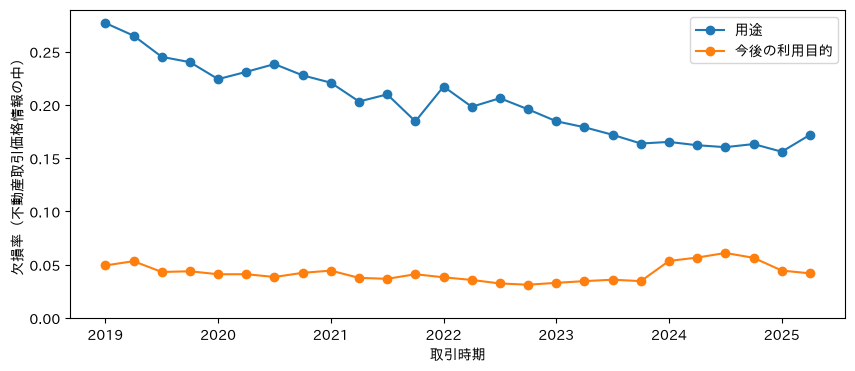

In [34]:
missing_by_period = survey_train.groupby("時期_数値")[["用途", "今後の利用目的"]].apply(lambda g: g.isna().mean())

fig, ax = plt.subplots(figsize=(10, 4))
missing_by_period.plot(marker="o", ax=ax)
ax.set_xlabel("取引時期")
ax.set_ylabel("欠損率（不動産取引価格情報の中）")
ax.set_ylim(0, None)
plt.show()

- `用途` は 79% が住宅、20% が欠損。住宅以外は全部合わせて約 900 件（0.8%）。
- `今後の利用目的` は 86% が住宅。「その他」が 8% と、住宅の次に多い。
- `用途` の欠損率は、2019 年の 28% から 2025 年の 16% まで下がり続けている。アンケートの回答のしかたが変わってきたのかもしれない（理由は不明）。Q1 で見たとおり、`用途` が欠損している行と住宅の行で価格の差はない（地区内 −0.002）。

### 今後の利用目的ごとの物件の特徴

In [35]:
purpose = survey_train["今後の利用目的"].fillna("欠損")
survey_train.groupby(purpose).agg(
    **{
        "件数": (TARGET, "size"),
        "面積の中央値": ("面積_数値", "median"),
        "1K・1R の割合": ("間取り", lambda s: s.isin(["１Ｋ", "１Ｒ"]).mean()),
        "建築年の中央値": ("建築年_数値", "median"),
        "価格の中央値": (TARGET, "median"),
    }
).round(2)

,件数,面積の中央値,1K・1R の割合,建築年の中央値,価格の中央値
今後の利用目的,,,,,
その他,8934,25.0,0.51,2004.0,25000000.0
事務所,1261,30.0,0.40,1985.0,26000000.0
住宅,96246,50.0,0.30,2004.0,33000000.0
店舗,370,50.0,0.09,1986.5,38000000.0
欠損,4715,45.0,0.30,2003.0,30000000.0


- **「その他」は小さい部屋が多い**。面積の中央値 25㎡、半分が 1K・1R。住宅として住むのでも、事務所・店舗にするのでもないワンルームなので、**賃貸に出す投資目的**の買主が「その他」と答えているのではないか（推測。アンケートの選択肢の説明は確認できていない）。
- **「事務所」「店舗」にする物件は古い**。建築年の中央値が 1985〜1986 年で、住宅（2004 年）より 20 年近く古い。

### 条件をそろえても価格は違うか

Q2・Q3 と同じく、場所 → 面積 → 築年 の順に条件をそろえる。

In [36]:
conditions = {"場所": LOCATION, "場所＋面積": SAME_SIZE, "場所＋面積＋築年": SAME_SIZE_AGE}
for col, values in {
    "今後の利用目的": ["住宅", "その他", "事務所", "店舗", "欠損"],
    "用途": ["住宅", "欠損", "事務所", "店舗", "その他", "駐車場", "倉庫"],
}.items():
    table = pd.DataFrame(index=values)
    for name, keys in conditions.items():
        gap, _ = controlled_gap(survey_train, col, keys)
        table[name] = gap["差"]
        table[f"件数（{name}）"] = gap["件数"]
    display(table.rename_axis(col))

,場所,件数（場所）,場所＋面積,件数（場所＋面積）,場所＋面積＋築年,件数（場所＋面積＋築年）
今後の利用目的,,,,,,
住宅,0.014,55306,0.020,15802,0.010,6315
その他,-0.043,8529,-0.031,5310,-0.017,2893
事務所,-0.192,1161,-0.136,622,0.010,247
店舗,-0.102,357,-0.073,131,0.036,32
欠損,-0.036,4455,-0.024,2460,-0.016,1288


,場所,件数（場所）,場所＋面積,件数（場所＋面積）,場所＋面積＋築年,件数（場所＋面積＋築年）
用途,,,,,,
住宅,0.005,49098,0.005,15709,0.003,6149
欠損,-0.002,20020,-0.001,9670,-0.003,4552
事務所,-0.259,334,-0.179,153,-0.071,50
店舗,-0.153,238,-0.135,77,0.091,15
その他,-0.090,177,-0.108,121,-0.040,63
駐車場,-1.019,26,-0.622,12,-0.679,1
倉庫,-0.471,13,-0.372,9,0.045,5


- **今後の利用目的**: 場所だけそろえると、事務所 −0.19、店舗 −0.10、その他 −0.04 と安い。築年までそろえると、どれもほぼ 0（±0.04 以内）になる。事務所・店舗にする買主は古くて安い物件を選んでいる、というだけで、目的そのものが価格を下げているわけではない。
- **用途**: 事務所・店舗も、築年までそろえると差は小さくなる（事務所 −0.07、店舗 +0.09。ただし件数は 50 件・15 件と少ない）。差が大きく残るのは駐車場（−0.6〜−1.0）と倉庫だけ。

In [37]:
survey_train.loc[
    survey_train["用途"].isin(["駐車場", "倉庫"]),
    ["用途", "今後の利用目的", "市区町村名", "面積（㎡）", "間取り", "建築年", TARGET],
].sort_values(TARGET)

,用途,今後の利用目的,市区町村名,面積（㎡）,間取り,建築年,取引価格（総額）
195456,駐車場,その他,国立市,15,NaN,2000年,1500000
65881,駐車場,その他,墨田区,15,NaN,1989年,1500000
22959,倉庫,その他,大田区,10,NaN,1987年,1700000
89775,倉庫,その他,杉並区,20,NaN,1973年,1700000
151950,駐車場,その他,練馬区,10,NaN,1996年,2000000
176816,倉庫,その他,中野区,15,NaN,1989年,3500000
38367,駐車場,その他,大田区,140,NaN,1995年,3600000
183697,駐車場,住宅,町田市,15,NaN,2004年,4000000
149151,駐車場,その他,荒川区,10,NaN,2012年,4000000
130135,駐車場,その他,荒川区,10,NaN,2012年,4000000


駐車場・倉庫の行（40 件）は、ほとんど `間取り` が欠損していて、10〜20㎡ で 150〜1,000 万円のものが多い。マンションの中の**駐車場や倉庫の区画だけ**を売買したものと思われる。部屋ではないので、価格がとても安い。

一方で 100㎡ を超えて 1 億円を超えるものもあり、まとまりはない。

### Q6 のまとめ

- `今後の利用目的` の「その他」は、ワンルームを賃貸に出す投資目的の買主かもしれない（推測）。
- 事務所・店舗として使う／使うつもりの物件が安く見えるのは、**古い物件が多いから**。築年までそろえると差はほぼ消える。
- 場所・面積・築年で説明できない差が残るのは、駐車場・倉庫の区画（約 40 件）だけ。部屋ではないものが混ざっている、というデータの問題に近い。
- 2 列とも、成約価格情報（test の 67%）では 100% 欠損している。
- そのため、「住宅以外の用途か」にまとめる列を作っても、効果はほとんどないと思われる。**今のままで十分**。
- 駐車場・倉庫の区画は、test にも成約価格情報の側にも混ざっているかもしれない。ただ、成約側では `用途` も `間取り` もほぼ埋まっていて見分けられない。件数も少ないので、今は気にしなくてよさそう。

## Q7. 駐車場・倉庫の区画の特徴

`用途` が駐車場・倉庫の行（`住宅、駐車場` のような複合も含む）を、ほかの行と比べる。

In [38]:
PARKING = ["駐車場", "倉庫", "住宅、駐車場", "事務所、駐車場", "住宅、倉庫"]
is_parking = train["用途"].isin(PARKING)
kind = np.where(is_parking, "駐車場・倉庫", "それ以外")

train.groupby(kind).agg(
    **{
        "件数": (TARGET, "size"),
        "面積の中央値": ("面積_数値", "median"),
        "価格の中央値": (TARGET, "median"),
        "㎡単価の中央値": ("㎡単価", "median"),
        "間取りの欠損率": ("間取り", lambda s: s.isna().mean()),
        "建築年の中央値": ("建築年_数値", "median"),
    }
).round(2)

,件数,面積の中央値,価格の中央値,㎡単価の中央値,間取りの欠損率,建築年の中央値
それ以外,202279,55.0,38000000.0,875000.0,0.03,2004.0
駐車場・倉庫,44,35.0,9150000.0,300000.0,0.80,1995.0


In [39]:
parking = train[is_parking]
for col in ["今後の利用目的", "間取り", "建物の構造", "都市計画", "改装"]:
    print(col, parking[col].fillna("欠損").value_counts().head(5).to_dict())
print("取引年", parking["取引時期"].str[:4].value_counts().sort_index().to_dict())

今後の利用目的 {'その他': 26, '住宅': 9, '事務所': 5, '店舗': 2, '欠損': 2}
間取り {'欠損': 35, 'オープンフロア': 6, '２ＬＤＫ＋Ｓ': 1, '３ＬＤＫ': 1, '２ＬＤＫ': 1}
建物の構造 {'ＲＣ': 29, 'ＳＲＣ': 14, '鉄骨造': 1}
都市計画 {'商業': 13, '近隣商業': 10, '準工業': 7, '１種住居': 6, '１中住専': 2}
改装 {'未改装': 22, '欠損': 18, '改装済み': 4}
取引年 {'2019': 5, '2020': 8, '2021': 9, '2022': 6, '2023': 7, '2024': 8, '2025': 1}


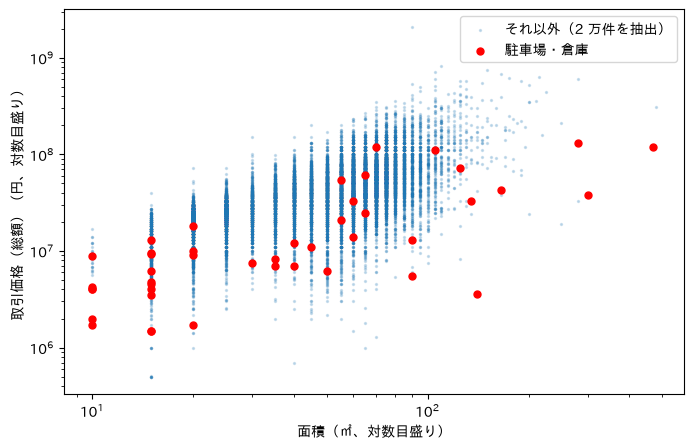

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))
others = train[~is_parking].sample(20000, random_state=0)
ax.scatter(others["面積_数値"], others[TARGET], s=2, alpha=0.2, label="それ以外（2 万件を抽出）")
ax.scatter(parking["面積_数値"], parking[TARGET], s=25, color="red", label="駐車場・倉庫")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("面積（㎡、対数目盛り）")
ax.set_ylabel(f"{TARGET}（円、対数目盛り）")
ax.legend()
plt.show()

- **44 件しかない**（train の 0.02%）。2019〜2024 年は毎年 5〜9 件ある。
- **㎡単価が約 1/3**（30 万円。それ以外は 88 万円）。価格の中央値は 915 万円。
- **8 割が `間取り` 欠損**。残りも多くは「オープンフロア」で、部屋としての間取りがない。
- 買主の今後の利用目的は「その他」が 6 割。
- 構造・都市計画・建築年は、普通のマンションと変わらない（RC・SRC、商業・近隣商業が多い）。建物は普通のマンションで、その中の部屋ではない区画を売買していると考えられる。
- 散布図では、どの面積でも普通の部屋の分布の下の端にいる。10〜20㎡ で 150〜1,000 万円のもの（駐車場 1 台分の区画と思われる）が多い。100㎡ を超えるものもあり、まとまった駐車場や倉庫をまとめて売買したものかもしれない。

### `用途` が分からない行に、駐車場・倉庫が紛れていないか

駐車場・倉庫の 8 割は `間取り` が欠損している。逆に「`間取り` が欠損していて小さい（20㎡ 以下）」行は、駐車場・倉庫なのか。

In [41]:
lookalike = train["間取り"].isna() & (train["面積_数値"] <= 20)
print(pd.crosstab(lookalike, train[KUBUN]))
print()
print("用途:", train.loc[lookalike, "用途"].fillna("欠損").value_counts().to_dict())
print(f"価格の中央値: 駐車場・倉庫 {parking[TARGET].median():,.0f} 円 / 間取り欠損かつ 20㎡ 以下 {train.loc[lookalike, TARGET].median():,.0f} 円")

価格情報区分  不動産取引価格情報  成約価格情報
row_0                    
False      110133   90797
True         1393       0

用途: {'住宅': 829, '欠損': 530, '駐車場': 14, 'その他': 8, '倉庫': 5, '事務所': 5, '店舗': 2}
価格の中央値: 駐車場・倉庫 9,150,000 円 / 間取り欠損かつ 20㎡ 以下 20,000,000 円


「`間取り` が欠損していて 20㎡ 以下」の行は 1,393 件あるが、`用途` は住宅が 829 件、欠損が 530 件で、駐車場・倉庫は 19 件だけ。価格の中央値も 2,000 万円で、駐車場・倉庫（915 万円）よりずっと高い。間取りの欠損は駐車場・倉庫の目印にはならない（ふつうのワンルームで間取りが書かれていないだけの行がほとんど）。

`用途` が欠損している行（不動産取引価格情報の 20%）や成約価格情報の行に駐車場・倉庫が紛れていても、価格以外の列からは見分けられない。

### test にはどれくらいあるか

In [42]:
print("test の用途:", test["用途"].fillna("欠損").value_counts().to_dict())

n_test = len(test)
n_parking_test = test["用途"].isin(PARKING).sum()
base_rmsle = 0.20674  # PR#3 の CV
for miss in [0.5, 1.0]:
    worse = np.sqrt(base_rmsle**2 + n_parking_test * miss**2 / n_test)
    print(f"駐車場・倉庫の {n_parking_test} 件が log で {miss} ずれた場合、RMSLE は {base_rmsle} → {worse:.5f}（+{worse - base_rmsle:.5f}）")

test の用途: {'欠損': 21344, '住宅': 7887, '事務所': 49, '店舗': 30, 'その他': 22, '駐車場': 6, '住宅、その他': 1, '住宅、店舗': 1, '事務所、店舗': 1}
駐車場・倉庫の 6 件が log で 0.5 ずれた場合、RMSLE は 0.20674 → 0.20686（+0.00012）
駐車場・倉庫の 6 件が log で 1.0 ずれた場合、RMSLE は 0.20674 → 0.20723（+0.00049）


test にも `用途` が駐車場の行が 6 件ある（どれも不動産取引価格情報の行）。

仮にモデルがこの 6 件を log で 1.0（約 2.7 倍）外していたとしても、RMSLE への影響は 0.0005 程度。全部当てられるようになっても、良くなるのはそのくらいが上限。

### Q7 のまとめ

- 駐車場・倉庫は、マンションの中の部屋ではない区画を売買したもの。㎡単価は普通の部屋の約 1/3 で、8 割は間取りがない。
- train に 44 件、test に 6 件だけ。`用途` が書かれている行でしか見分けられない。
- LightGBM はカテゴリの件数が少ないと、その値だけで分岐しないことがある（`min_data_per_group` などの設定）。26 件しかない「駐車場」はモデルが学べていない可能性がある。
- 直せたとしても RMSLE への効果は最大 0.0005 程度。「駐車場・倉庫か」の列を足すのは手軽なので試す価値はゼロではないが、優先度は低い。

## Q8. 外れ値（極端に安い・高い取引）

価格そのものが安い・高いだけなら、狭い・広い物件というだけかもしれない。そこで「似た物件の相場」と比べて、ずれが大きい取引を外れ値とする。

### 相場の決め方

log(㎡単価) を、似た物件の中央値と比べる。似た物件は、細かい条件から順に探し、10 件以上ある最初の条件を使う。

1. 同じ地区名・取引年・面積帯・築年帯（10 年刻み）
2. 同じ市区町村・取引年・面積帯・築年帯・駅からの距離の帯
3. 同じ市区町村・取引年・面積帯・駅からの距離の帯
4. 同じ市区町村・面積帯・駅からの距離の帯
5. 同じ市区町村・面積帯

相場とのずれが log で ±1（約 2.7 倍）を超える行を外れ値とする。相場は大まかなので、外れ値の中には「相場の決め方が粗いだけ」の行も混ざる。

In [43]:
distance = pd.to_numeric(train["最寄駅：距離（分）"], errors="coerce")
train["駅距離帯"] = pd.cut(distance, [-1, 5, 10, 15, 20, 30]).astype(str)
train.loc[train["最寄駅：距離（分）"].str.contains("～", na=False), "駅距離帯"] = "30分以上"
train.loc[train["最寄駅：距離（分）"].isna(), "駅距離帯"] = "欠損"
train["築年帯10"] = pd.cut(train["建築年_数値"], [1900, 1975, 1985, 1995, 2005, 2015, 2030])

REFERENCE_LEVELS = [
    ["地区名", "取引年", "面積帯", "築年帯10"],
    ["市区町村名", "取引年", "面積帯", "築年帯10", "駅距離帯"],
    ["市区町村名", "取引年", "面積帯", "駅距離帯"],
    ["市区町村名", "面積帯", "駅距離帯"],
    ["市区町村名", "面積帯"],
]
log_unit = np.log(train["㎡単価"])
train["相場とのずれ"] = np.nan
for keys in REFERENCE_LEVELS:
    group = log_unit.groupby([train[k] for k in keys], observed=True)
    enough = train["相場とのずれ"].isna() & (group.transform("size") >= 10)
    train.loc[enough, "相場とのずれ"] = (log_unit - group.transform("median"))[enough]

print(f"相場を決められた行: {train['相場とのずれ'].notna().mean():.1%}")

相場を決められた行: 99.8%


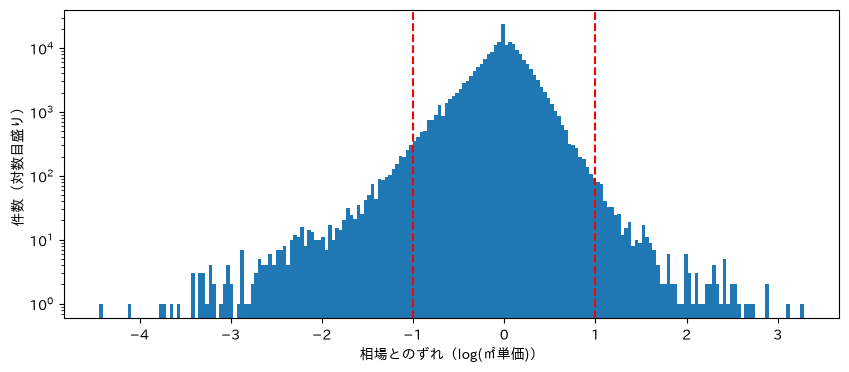

In [44]:
dev = train["相場とのずれ"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(dev.dropna(), bins=200)
ax.set_yscale("log")
for x in (-1, 1):
    ax.axvline(x, color="red", linestyle="--")
ax.set_xlabel("相場とのずれ（log(㎡単価)）")
ax.set_ylabel("件数（対数目盛り）")
plt.show()

rows = []
for th in [1, 1.5, 2]:
    for kubun, g in train.groupby(KUBUN):
        d = g["相場とのずれ"]
        rows.append({"しきい値": f"±{th}（{np.exp(th):.1f} 倍）", "区分": kubun, "安すぎ": (d < -th).mean(), "高すぎ": (d > th).mean()})
pd.DataFrame(rows).pivot(index="しきい値", columns="区分").style.format("{:.2%}")

- 安い側の裾の方が長い。±1 を超える行は、安すぎ約 2,300 件、高すぎ約 500 件。
- ±1（2.7 倍）では、安すぎの割合は区分によらず約 1.1%。
- **極端な外れ値はほとんどアンケート側**。±2（7.4 倍）を超える安すぎは、不動産取引価格情報 0.16%、成約価格情報 0.02% で 8 倍違う。高すぎはほぼ全部が不動産取引価格情報。

### どんな属性だと外れ値になりやすいか

タイタニックの「女性・子供なら生存率が高い」のように、外れ値になる確率が飛び抜けて高い属性がないかを見る。全体の外れ値の割合（安すぎ約 1.1%、高すぎ約 0.2%）と比べる。

In [45]:
train["地域"] = np.where(train["市区町村名"].str.endswith("区"), "23 区", "多摩")
judged = train[dev.notna()]


def outlier_rate(col, min_count=30):
    value = judged[col].astype(object).where(judged[col].notna(), "欠損").astype(str)
    d = judged["相場とのずれ"]
    table = value.value_counts().rename("件数").to_frame()
    table["安すぎ"] = (d < -1).groupby(value).mean()
    table["高すぎ"] = (d > 1).groupby(value).mean()
    return table[table["件数"] >= min_count].sort_values("安すぎ", ascending=False)


for col in ["取引の事情等", "用途", "今後の利用目的", "建物の構造", "築年帯10", "駅距離帯", "地域", KUBUN]:
    display(outlier_rate(col).head(6).style.format({"安すぎ": "{:.1%}", "高すぎ": "{:.1%}"}).set_caption(col))

,件数,安すぎ,高すぎ
取引の事情等,,,
関係者間取引,87,24.1%,0.0%
調停・競売等,514,2.3%,0.6%
欠損,201398,1.1%,0.2%


,件数,安すぎ,高すぎ
用途,,,
事務所、店舗,32,12.5%,0.0%
店舗,251,9.2%,3.2%
事務所,365,6.3%,2.7%
その他,179,3.9%,0.0%
欠損,113146,1.1%,0.2%
住宅,87967,1.0%,0.3%


,件数,安すぎ,高すぎ
今後の利用目的,,,
店舗,367,8.4%,3.5%
事務所,1259,3.4%,1.0%
その他,8927,1.7%,0.3%
欠損,95340,1.1%,0.1%
住宅,96112,1.0%,0.3%


,件数,安すぎ,高すぎ
建物の構造,,,
鉄骨造,1519,6.2%,0.5%
ＳＲＣ、ＲＣ,132,3.8%,2.3%
欠損,4747,1.8%,0.3%
ＳＲＣ,47294,1.6%,0.2%
軽量鉄骨造,64,1.6%,0.0%
ＲＣ,148158,0.9%,0.3%


,件数,安すぎ,高すぎ
築年帯10,,,
"(1900, 1975]",13162,6.8%,0.1%
"(1975, 1985]",24944,2.7%,0.1%
"(1985, 1995]",23113,2.0%,0.4%
欠損,4029,1.3%,0.5%
"(1995, 2005]",51225,0.2%,0.1%
"(2015, 2030]",27731,0.1%,0.7%


,件数,安すぎ,高すぎ
駅距離帯,,,
30分以上,798,6.5%,1.4%
"(20.0, 30.0]",2272,3.8%,1.1%
"(15.0, 20.0]",7523,2.0%,0.3%
欠損,3546,1.9%,0.4%
"(10.0, 15.0]",29597,1.3%,0.3%
"(-1.0, 5.0]",80686,1.0%,0.2%


,件数,安すぎ,高すぎ
地域,,,
多摩,31438,2.6%,1.0%
23 区,170567,0.8%,0.1%


,件数,安すぎ,高すぎ
価格情報区分,,,
不動産取引価格情報,111379,1.1%,0.3%
成約価格情報,90626,1.1%,0.1%


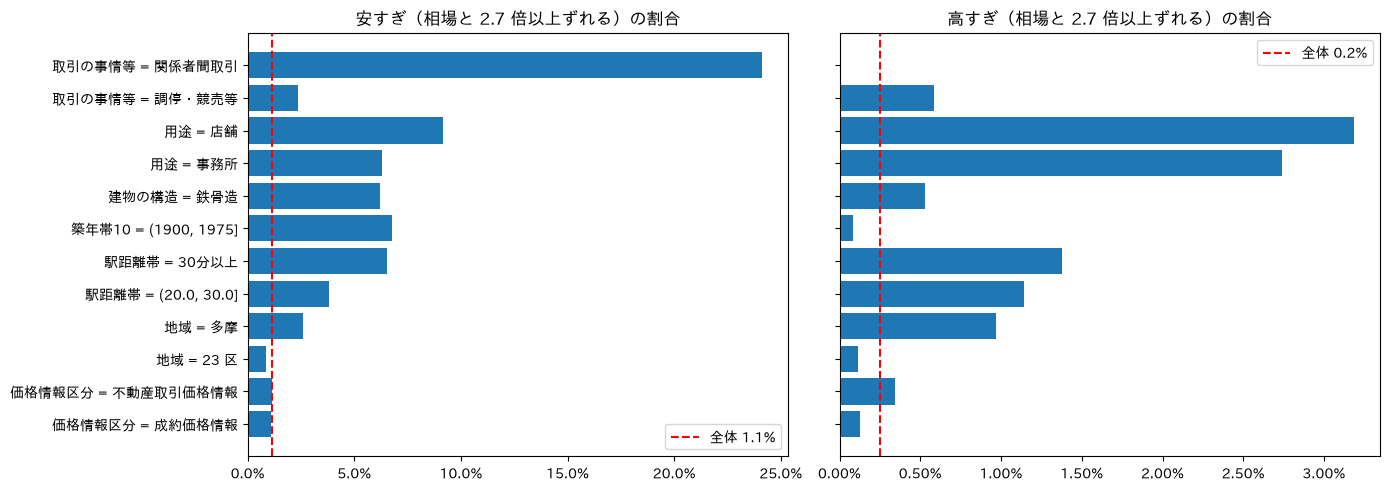

In [46]:
picked = [
    ("取引の事情等", "関係者間取引"),
    ("取引の事情等", "調停・競売等"),
    ("用途", "店舗"),
    ("用途", "事務所"),
    ("建物の構造", "鉄骨造"),
    ("築年帯10", "(1900, 1975]"),
    ("駅距離帯", "30分以上"),
    ("駅距離帯", "(20.0, 30.0]"),
    ("地域", "多摩"),
    ("地域", "23 区"),
    (KUBUN, "不動産取引価格情報"),
    (KUBUN, "成約価格情報"),
]
rates = pd.DataFrame(
    [{"属性": f"{col} = {value}", **outlier_rate(col).loc[value, ["安すぎ", "高すぎ", "件数"]]} for col, value in picked]
).set_index("属性")
overall = (dev < -1).mean(), (dev > 1).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col, base in zip(axes, ["安すぎ", "高すぎ"], overall):
    ax.barh(rates.index[::-1], rates[col][::-1])
    ax.axvline(base, color="red", linestyle="--", label=f"全体 {base:.1%}")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(f"{col}（相場と 2.7 倍以上ずれる）の割合")
    ax.legend()
plt.tight_layout()
plt.show()

| 属性 | 安すぎの割合（全体 約 1.1%） | 読み取れること |
|---|---|---|
| **取引の事情等 = 関係者間取引** | **24%**（約 22 倍） | タイタニックの「女性・子供」に近い。身内の取引は相場よりずっと安い |
| 用途・今後の利用目的 = 店舗・事務所 | 6〜12% | 高すぎも 3% ほどあり、両側にばらつく |
| 建物の構造 = 鉄骨造 | 6% | |
| 1975 年以前の建物 | 7% | 古い建物は価格のばらつきが大きい |
| 駅から 20 分以上 | 4〜7% | |
| 多摩地域 | 2.6%（23 区は 0.8%） | 件数が少なく、相場の決め方が粗いせいもある |

関係者間取引以外は、件数の少ない属性や相場を決めにくい属性が多い。「相場の決め方が粗いだけ」の分も含まれている。

### 極端な例

In [47]:
SHOW = [KUBUN, "市区町村名", "地区名", "間取り", "面積（㎡）", "建築年", "用途", "取引の事情等", "取引時期", TARGET, "相場とのずれ"]
display(train.nsmallest(15, "相場とのずれ")[SHOW])
display(train.nlargest(15, "相場とのずれ")[SHOW])

,価格情報区分,市区町村名,地区名,間取り,面積（㎡）,建築年,用途,取引の事情等,取引時期,取引価格（総額）,相場とのずれ
126249,不動産取引価格情報,新宿区,大久保,オープンフロア,130,2009年,事務所,NaN,2023年第2四半期,1900000,-4.440271
99900,不動産取引価格情報,多摩市,和田,２ＤＫ,45,1995年,NaN,NaN,2023年第4四半期,200000,-4.094345
172039,不動産取引価格情報,青梅市,東青梅,１Ｋ,15,1988年,住宅,NaN,2023年第1四半期,50000,-3.747771
89480,不動産取引価格情報,足立区,東和,２Ｋ,25,1976年,住宅,NaN,2024年第4四半期,600000,-3.729701
180450,不動産取引価格情報,目黒区,東山,１ＬＤＫ,40,1970年,住宅,NaN,2020年第3四半期,1100000,-3.665890
64862,不動産取引価格情報,練馬区,大泉町,１Ｒ,15,1990年,住宅,NaN,2022年第3四半期,200000,-3.569433
12653,不動産取引価格情報,八王子市,大和田町,１ＤＫ,25,1987年,住宅,NaN,2019年第4四半期,600000,-3.401197
29917,不動産取引価格情報,八王子市,大和田町,１ＤＫ,25,1987年,NaN,NaN,2020年第3四半期,600000,-3.401197
122523,不動産取引価格情報,八王子市,大和田町,１ＤＫ,25,1987年,NaN,NaN,2022年第2四半期,600000,-3.401197
143405,不動産取引価格情報,八王子市,大和田町,１ＤＫ,25,1987年,住宅,NaN,2020年第4四半期,600000,-3.344039


,価格情報区分,市区町村名,地区名,間取り,面積（㎡）,建築年,用途,取引の事情等,取引時期,取引価格（総額）,相場とのずれ
13225,不動産取引価格情報,八王子市,八日町,１Ｋ,20,2010年,NaN,NaN,2020年第4四半期,18000000,3.285936
90053,不動産取引価格情報,渋谷区,神宮前,３ＬＤＫ,160,2024年,NaN,NaN,2025年第2四半期,16000000000,3.124156
158127,不動産取引価格情報,港区,元麻布,４ＬＤＫ,20,2002年,NaN,NaN,2020年第2四半期,490000000,2.898569
89885,不動産取引価格情報,世田谷区,瀬田,３ＬＤＫ,90,1999年,住宅,NaN,2025年第2四半期,2100000000,2.896203
104156,不動産取引価格情報,杉並区,成田東,３ＬＤＫ,75,2016年,住宅,NaN,2022年第1四半期,1100000000,2.733392
47411,不動産取引価格情報,目黒区,下目黒,２ＬＤＫ,50,2013年,住宅,NaN,2022年第1四半期,730000000,2.681022
157132,不動産取引価格情報,板橋区,成増,２ＬＤＫ,50,2011年,住宅,NaN,2025年第2四半期,340000000,2.630481
66227,不動産取引価格情報,杉並区,西荻北,１Ｒ,15,1984年,住宅,NaN,2022年第3四半期,110000000,2.560414
181484,不動産取引価格情報,中野区,弥生町,３ＬＤＫ,110,1990年,住宅,NaN,2024年第1四半期,1000000000,2.540419
176306,不動産取引価格情報,杉並区,浜田山,５ＬＤＫ,135,1996年,住宅,NaN,2024年第1四半期,1400000000,2.515576


- **安すぎの例**: 新宿区の 130㎡ が 190 万円、渋谷区松濤の 2008 年築 1K が 160 万円、青梅市の 1K が 5 万円など。物件をまるごと買う価格としてはありえない。共有持分の一部だけを売買した、入力ミスなどが考えられるが、データからは分からない（推測）。
- **高すぎの例**: 渋谷区神宮前の 160㎡ が 160 億円、港区元麻布の「４ＬＤＫ・20㎡」（間取りと面積が矛盾）が 4.9 億円、杉並区の 1R・15㎡ が 1.1 億円など。建物を丸ごと、または複数の部屋をまとめて売買したか、入力ミスと思われる（推測）。
- 極端な例は、ほぼ全部が不動産取引価格情報（アンケート）の行。

In [48]:
cheap = train[train["相場とのずれ"] < -1.5]
cheap.groupby(["市区町村名", "地区名", "建築年", "建物の構造"]).size().sort_values(ascending=False).head(8).rename("件数")

市区町村名  地区名   建築年    建物の構造
八王子市   大和田町  1987年  ＳＲＣ      18
国分寺市   西町    1965年  ＲＣ       15
町田市    鶴川    1969年  ＲＣ        7
立川市    幸町    1989年  ＲＣ        5
日野市    三沢    1970年  ＲＣ        4
多摩市    愛宕    1972年  ＲＣ        4
足立区    竹の塚   1977年  ＲＣ        4
八王子市   千人町   1973年  ＳＲＣ       4
Name: 件数, dtype: int64

安すぎの行の中には、同じ建物（同じ地区・建築年・構造）の部屋が何度も出てくるものがある。八王子市大和田町の 1987 年築 SRC は 18 件、国分寺市西町の 1965 年築 RC は 15 件。

これは外れ値というより「その建物の相場が安い」ということで、データの誤りではないと思われる。`地区名` と `建築年` の組み合わせで、モデルもある程度は学べる。

### 学習への影響

モデルは log(価格) の二乗誤差を小さくするように学習する。外れ値はずれが大きいので、二乗すると影響が大きくなる。

In [49]:
sq = train["相場とのずれ"] ** 2
for th in [1, 1.5, 2]:
    big = train["相場とのずれ"].abs() > th
    print(f"ずれ ±{th} 超: 行の {big.mean():.2%} だが、ずれの二乗の合計の {sq[big].sum() / sq.sum():.1%} を占める")

ずれ ±1 超: 行の 1.37% だが、ずれの二乗の合計の 25.0% を占める
ずれ ±1.5 超: 行の 0.29% だが、ずれの二乗の合計の 11.4% を占める
ずれ ±2 超: 行の 0.12% だが、ずれの二乗の合計の 6.8% を占める


### Q8 のまとめ

- 相場と 2.7 倍以上ずれる行は 1.4% だけだが、**ずれの二乗の合計の 25% を占める**。log の二乗誤差で学習するモデルは、この少数の行に強く引っ張られる。
- **7 倍以上ずれる極端な行は、ほぼ全部アンケート側**（約 220 件）。共有持分・一括取引・入力ミスなど、普通の売買ではないものが混ざっていると思われる。
- test の 67% は成約価格情報で、極端な外れ値はほとんどないはず。アンケート側の極端な行に引っ張られて、普通の行の予測がずれているかもしれない。
- タイタニックの「女性・子供」に近い属性は **関係者間取引**（24% が安すぎ）。test にも 12 件ある。`取引の事情等` はすでに特徴量に入っているが、87 件しかないので、モデルが学べているかは分からない。

モデルで試す価値がありそうなこと（効くかは CV で確かめる）:

| 工程 | 案 |
|---|---|
| 3. 学習データの選択 | 相場と 7 倍以上ずれる行を学習から外す、または重みを下げる。相場は価格から計算するので、fold ごとに学習データだけで計算する（`src/selection.py` は fold ごとに呼ばれるので、そこに書ける） |
| 5. モデル | 二乗誤差の代わりに、大きなずれの影響を抑える損失（Huber など）を使う |

どちらも、外れ値そのものを当てるのではなく、外れ値に引っ張られて普通の行の予測がずれるのを防ぐための案。

## Q9. 関係者間取引の扱い

`取引の事情等` が関係者間取引の行は、Q8 で 24% が「安すぎ」の外れ値だった。ほかの行も含めて、相場とのずれの分布を見る。

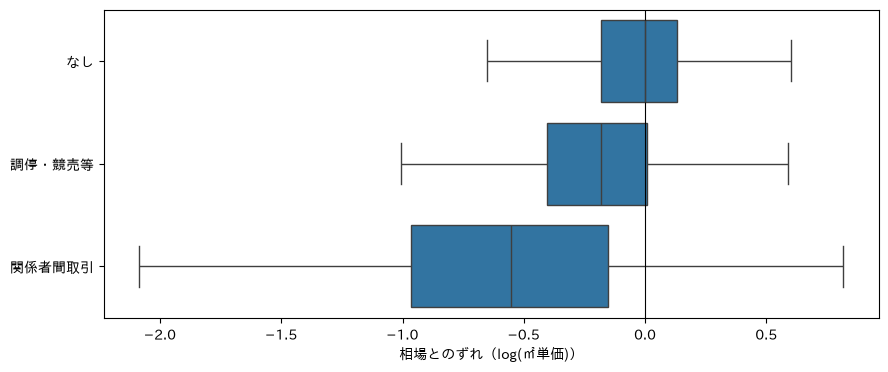

,count,mean,10%,50%,90%,平均の倍率
取引の事情等,,,,,,
その他事情有り,3.0,-0.57,-0.99,-0.87,-0.03,0.56
なし,201398.0,-0.04,-0.42,0.00,0.31,0.96
瑕疵有りの可能性,3.0,-0.96,-1.20,-1.05,-0.68,0.38
調停・競売等,514.0,-0.22,-0.67,-0.18,0.19,0.81
関係者間取引,87.0,-0.64,-1.42,-0.55,0.03,0.53


In [50]:
circumstance = train["取引の事情等"].fillna("なし")
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    x=train["相場とのずれ"],
    y=circumstance,
    order=["なし", "調停・競売等", "関係者間取引"],
    showfliers=False,
    ax=ax,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("相場とのずれ（log(㎡単価)）")
ax.set_ylabel("")
plt.show()

summary = train.groupby(circumstance)["相場とのずれ"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "mean", "10%", "50%", "90%"]]
summary["平均の倍率"] = np.exp(summary["mean"])
summary.round(2)

- 関係者間取引は、**一部が極端に安いのではなく、全体的に安い**。ずれの中央値は −0.55、9 割の行が相場以下。平均すると相場の約 0.53 倍。
- 調停・競売等も全体的に安い（平均で相場の約 0.8 倍）。
- test にも関係者間取引が 12 件、調停・競売等が 35 件ある（どちらも不動産取引価格情報の行だけ）。

外れ値として学習から外すと、test のこの行を安く予測できなくなる。**外すのではなく、安いことをモデルに学ばせたい**。

### 今のモデルは関係者間取引を学べているか

`取引の事情等` はすでにカテゴリ変数として特徴量に入っている。ただし LightGBM には、件数の少ないカテゴリの値では分岐しない設定がある（`min_data_per_group`、デフォルトは 100）。関係者間取引は 87 件しかない。

`取引の事情等` だけで LightGBM を学習させて、値ごとの予測を比べる（精度を測るのではなく、モデルがこの値を区別できるかの確認）。

In [51]:
import lightgbm as lgb

y = np.log1p(train[TARGET])
categories = train["取引の事情等"].astype("category").cat.categories
query = pd.Categorical([np.nan, *categories], categories=categories)
labels = ["なし", *categories]

check = pd.DataFrame(index=labels)
check["実際（幾何平均）"] = np.expm1(y.groupby(circumstance).mean()).rename({"なし": "なし"})

for name, params in {"デフォルト": {}, "min_data_per_group=20": {"min_data_per_group": 20}}.items():
    model = lgb.train(
        {"objective": "regression", "verbose": -1, **params},
        lgb.Dataset(train[["取引の事情等"]].astype("category"), y),
        num_boost_round=200,
    )
    check[f"カテゴリ変数（{name}）"] = np.expm1(model.predict(pd.DataFrame({"取引の事情等": query})))

flag = (train["取引の事情等"] == "関係者間取引").astype(int).rename("関係者間取引か")
model = lgb.train({"objective": "regression", "verbose": -1}, lgb.Dataset(flag.to_frame(), y), num_boost_round=200)
check["2 値の列（関係者間取引か）"] = np.nan
check.loc["なし", "2 値の列（関係者間取引か）"] = np.expm1(model.predict(pd.DataFrame({"関係者間取引か": [0]})))[0]
check.loc["関係者間取引", "2 値の列（関係者間取引か）"] = np.expm1(model.predict(pd.DataFrame({"関係者間取引か": [1]})))[0]

(check / 10_000).round(0).rename(columns=lambda c: f"{c}（万円）")

,実際（幾何平均）（万円）,カテゴリ変数（デフォルト）（万円）,カテゴリ変数（min_data_per_group=20）（万円）,2 値の列（関係者間取引か）（万円）
なし,3772.0,3771.0,3772.0,3766.0
その他事情有り,2865.0,3771.0,3772.0,NaN
瑕疵有りの可能性,869.0,3771.0,3772.0,NaN
調停・競売等,1913.0,1913.0,1913.0,NaN
関係者間取引,1694.0,3771.0,1694.0,1694.0


- **デフォルトのカテゴリ変数では、関係者間取引を区別できていない**。予測は「なし」と同じ 3,771 万円で、実際（1,694 万円）よりずっと高い。件数が 100 件に足りないため。
- `min_data_per_group` を 20 に下げるか、**関係者間取引かどうかの 2 値の列**にすると、1,694 万円と区別できる。

ほかの列も含めた本番のモデルでは、別の列の分岐で多少は安く予測されているかもしれない。ただ、`取引の事情等` の列そのものは今は役に立っていない可能性が高い。

### Q9 のまとめ

関係者間取引の扱いの案:

| 案 | 良い点 | 気になる点 |
|---|---|---|
| **関係者間取引かの 2 値の列を足す**（おすすめ） | この値だけを確実に区別できる。ほかの列に影響しない | 調停・競売等（516 件）は今のままでも区別できているので、関係者間取引だけでよい |
| `min_data_per_group` を下げる | 駐車場（26 件）など、ほかの少ないカテゴリも区別できるようになる | `地区名`（1,210 種類）など全部のカテゴリ変数に効くので、過学習するかもしれない。パラメータの工程（6）の実験になる |
| 学習から外す | 外れ値に引っ張られなくなる | test の 12 件を安く予測できなくなる。おすすめしない |

効果の大きさは小さいと思われる。test の 12 件が今 log で 0.6 ずれているとすると、RMSLE への影響は 0.0004 程度。

## Q10. 相場の推移

決定木は、学習データにない値の範囲を予測できない。`経過四半期` で分岐しても、test の四半期は「学習データの最後の四半期と同じ」と扱われる。値上がりが続いているなら、test を低く予測してしまう。どれくらい値上がりしているかを確かめる。

### 相場の指数の作り方

単純に四半期ごとの㎡単価の中央値を見ると、物件の顔ぶれの変化も混ざる（例: 2021 年から成約価格情報が加わり、広い物件が増えた）。そこで「同じような物件」どうしで比べる。

1. 物件を「価格情報区分 × 地区名 × 面積帯 × 築年数の帯（5 年刻み）」の組に分ける。築年数（取引した時点で何年たっているか）を使うのは、建物が古くなる分を値上がりと混ぜないため。価格情報区分を入れるのは、2021 年に成約価格情報（同じ条件だと約 6% 安い、Q1）が加わった分を値動きと混ぜないため
2. log(㎡単価) を「組の効果」と「四半期の効果」の和で表し、2 つを交互に推定する（組ごとに含まれる期間が違っても、ゆがまないようにするため）
3. 四半期の効果 → 同じ組の物件が、その四半期にどれだけ高く売れたか

2019 年第 1 四半期を 100 とした指数で表す。

In [52]:
train["築年数"] = train["取引年"] - train["建築年_数値"]
train["築年数帯"] = pd.cut(train["築年数"], range(-5, 80, 5))
INDEX_CELL = [KUBUN, "地区名", "面積帯", "築年数帯"]


def market_index(df, n_iter=30):
    """log(㎡単価) = 組の効果 + 四半期の効果 として、四半期の効果を指数にする。

    組の平均を引くだけだと、組ごとに含まれる期間が違うとき（成約価格情報は 2021 年から）に、
    組の平均の基準になる時期がずれて指数がゆがむ。2 つの効果を交互に推定して、このずれを取り除く。
    """
    log_unit = np.log(df["㎡単価"])
    cell = df.groupby(INDEX_CELL, observed=True).ngroup()
    quarter = df["時期_数値"]
    quarter_effect = pd.Series(0.0, index=df.index)
    for _ in range(n_iter):
        cell_effect = (log_unit - quarter_effect).groupby(cell).transform("mean")
        quarter_effect = (log_unit - cell_effect).groupby(quarter).transform("mean")
    level = quarter_effect.groupby(quarter).first()
    return 100 * np.exp(level - level.iloc[0])


index_all = market_index(train)
raw_median = np.log(train["㎡単価"]).groupby(train["時期_数値"]).median()
raw_index = 100 * np.exp(raw_median - raw_median.iloc[0])

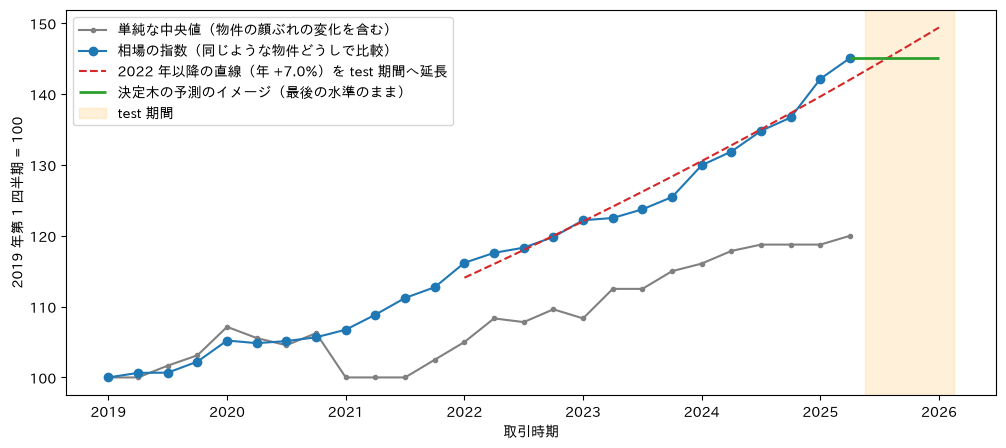

2022 年以降の上昇: 年 +7.0% / 直近 1 年の上昇: 年 +10.2%
2025Q3: 最後の水準のままだと、直近 1 年の速さで上がり続けた場合より 2.5% 低く予測する
2025Q4: 最後の水準のままだと、直近 1 年の速さで上がり続けた場合より 5.0% 低く予測する
2026Q1: 最後の水準のままだと、直近 1 年の速さで上がり続けた場合より 7.6% 低く予測する
（参考）2022 年以降の直線を延ばした値と最後の水準の差: -0.4%, +1.3%, +3.0%


In [53]:
TEST_QUARTERS = np.array([2025.5, 2025.75, 2026.0])
recent_index = index_all[index_all.index >= 2022]
slope, intercept = np.polyfit(recent_index.index, np.log(recent_index.values), 1)
last_year = index_all[index_all.index >= 2024.25]
recent_slope = np.polyfit(last_year.index, np.log(last_year.values), 1)[0]
trend_x = np.r_[recent_index.index, TEST_QUARTERS]
trend_y = np.exp(intercept + slope * trend_x)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(raw_index.index, raw_index.values, color="gray", marker=".", label="単純な中央値（物件の顔ぶれの変化を含む）")
ax.plot(index_all.index, index_all.values, color="tab:blue", marker="o", label="相場の指数（同じような物件どうしで比較）")
ax.plot(trend_x, trend_y, color="tab:red", linestyle="--", label=f"2022 年以降の直線（年 {np.exp(slope) - 1:+.1%}）を test 期間へ延長")
ax.hlines(index_all.iloc[-1], index_all.index[-1], TEST_QUARTERS[-1], color="tab:green", linewidth=2, label="決定木の予測のイメージ（最後の水準のまま）")
ax.axvspan(2025.375, 2026.125, color="orange", alpha=0.15, label="test 期間")
ax.set_xlabel("取引時期")
ax.set_ylabel("2019 年第 1 四半期 = 100")
ax.legend(loc="upper left")
plt.show()

gap = np.log(np.exp(intercept + slope * TEST_QUARTERS) / index_all.iloc[-1])
print(f"2022 年以降の上昇: 年 {np.exp(slope) - 1:+.1%} / 直近 1 年の上昇: 年 {np.exp(recent_slope) - 1:+.1%}")
for i, q in enumerate(["2025Q3", "2025Q4", "2026Q1"], start=1):
    print(f"{q}: 最後の水準のままだと、直近 1 年の速さで上がり続けた場合より {np.exp(recent_slope * i / 4) - 1:.1%} 低く予測する")
print(f"（参考）2022 年以降の直線を延ばした値と最後の水準の差: {', '.join(f'{np.exp(g) - 1:+.1%}' for g in gap)}")

- **相場は 2019 年から 2025 年第 2 四半期までに約 45% 上がった**。2022 年以降は年 7%、直近 1 年は年 10% と、上がる速さが増している。
- 単純な中央値（灰色）は約 20% しか上がっていないように見える。物件の顔ぶれが変わった（2021 年から成約価格情報が加わった、など）分が混ざって、値上がりが隠れている。
- 決定木が test を「最後の水準のまま」で予測すると、直近 1 年の速さで上がり続けた場合、2025Q3 で 2.5%、2025Q4 で 5.0%、2026Q1 で 7.6% 低く予測することになる。test の件数で平均すると約 5% 低い。
- 上がる速さを 2022 年以降の直線（年 7%）とすると、ずれは 0〜3% に縮む。どの速さで延ばすかで、ずれの大きさは大きく変わる。

log で 0.05 のずれが全部の行に乗ると、RMSLE は 0.207 → 約 0.213（+0.006）になる。これまでの EDA で見たどの案より影響が大きい。

### 物件の種類ごとの推移

値上がりの速さが物件の種類で違うなら、全体の直線で一律に補正するだけでは足りない。

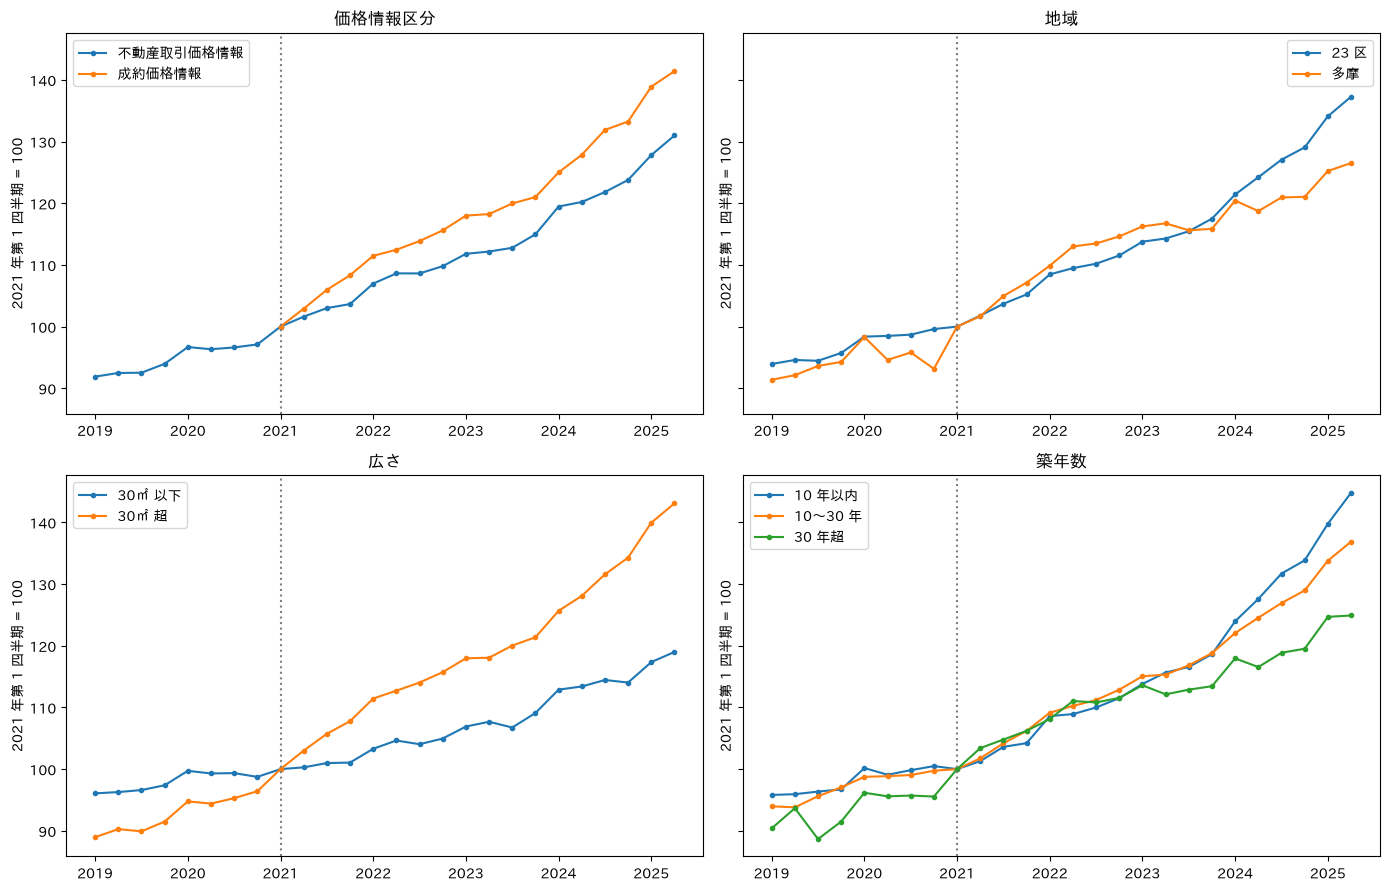

In [54]:
segments = {
    "価格情報区分": {k: train[KUBUN] == k for k in ["不動産取引価格情報", "成約価格情報"]},
    "地域": {k: train["地域"] == k for k in ["23 区", "多摩"]},
    "広さ": {"30㎡ 以下": train["面積_数値"] <= 30, "30㎡ 超": train["面積_数値"] > 30},
    "築年数": {"10 年以内": train["築年数"] <= 10, "10〜30 年": train["築年数"].between(11, 30), "30 年超": train["築年数"] > 30},
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
growth = []
for ax, (title, groups) in zip(axes.flat, segments.items()):
    for name, rows in groups.items():
        idx = market_index(train[rows])
        idx = 100 * idx / idx[idx.index >= 2021].iloc[0]  # 成約価格情報が始まった 2021Q1 = 100 にそろえる
        ax.plot(idx.index, idx.values, marker=".", label=name)
        recent = idx[idx.index >= 2022]
        growth.append({"分け方": title, "グループ": name, "年あたりの上昇（2022〜）": np.exp(np.polyfit(recent.index, np.log(recent.values), 1)[0]) - 1})
    ax.axvline(2021, color="gray", linestyle=":")
    ax.set_title(title)
    ax.set_ylabel("2021 年第 1 四半期 = 100")
    ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(growth).set_index(["分け方", "グループ"]).style.format("{:+.1%}")

| 分け方 | 上がる速さ（2022 年以降、年あたり） |
|---|---|
| 価格情報区分 | 成約価格情報 +7.6% / 不動産取引価格情報 +6.2% |
| 地域 | 23 区 +7.5% / 多摩 +3.7% |
| 広さ | 30㎡ 超 +7.9% / 30㎡ 以下 +4.5% |
| 築年数 | 10 年以内 +9.4% / 10〜30 年 +7.1% / 30 年超 +4.1% |

**上がる速さは物件の種類で 2 倍以上違う**。23 区・ファミリー向け・築浅ほど速く上がっている。全体の指数で一律に補正すると、多摩・ワンルーム・古い物件は高く予測しすぎることになる。

### Q10 のまとめ

- 相場は 2022 年以降、年 7% ほどで上がっていて、直近はさらに速い（年 10%）。
- 決定木は、学習期間の最後の水準より先へは予測を伸ばせない。上昇が続くなら、test を平均で数 % 低く予測することになり、RMSLE への影響は、延ばす速さによって +0.0003〜0.006 程度。速い方なら、これまでの案よりずっと大きい。
- 上がる速さは物件の種類で違う。一番大きく違うのは場所で、市区町村ごとに 2%（多摩市）から 14.5%（中央区）まで 7 倍違う。もともと高い場所ほど速く上がっている（相関 0.73）。広さ・間取り・築年数・駅からの距離でも 2 倍前後違う。

モデルで試す価値がありそうなこと（工程 4. 目的変数）:

- 価格を、その四半期の相場の指数で割ってから予測させる（決定木には「相場に比べて高いか安いか」だけを任せる）。test では、指数を直線などで先へ延ばした値を掛けて戻す。
- 指数は全体で 1 本でもよいが、分けるならまず場所（市区町村、または㎡単価の水準の帯）で分けるのがよさそう。分けすぎると 1 本あたりの件数が減って、延ばした値がぶれる。
- どの期間の速さで延ばすか（2022 年以降か、直近 1 年か）で結果が大きく変わる。CV の fold ごとに、その fold の学習期間だけで指数と速さを決めて比べる必要がある。

注意: 上昇が今後も続くとは限らない。test 期間に上昇が止まっていれば、延ばした分だけ高く予測しすぎる。

### ほかの分け方

上の 4 つ以外の分け方でも、上がる速さを比べる。

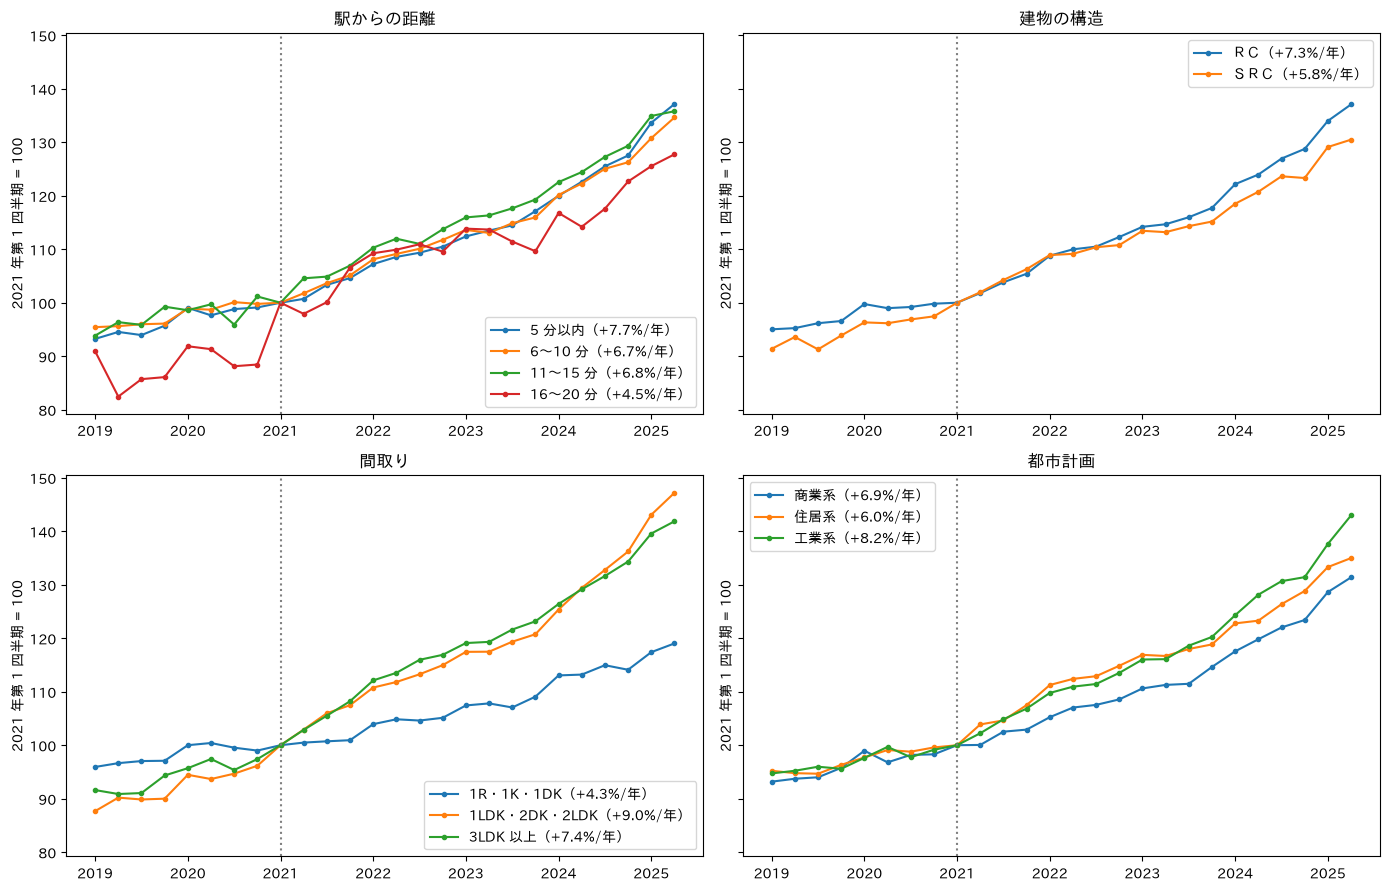

In [55]:
def growth_since_2022(rows):
    idx = market_index(train[rows])
    recent = idx[idx.index >= 2022]
    return np.exp(np.polyfit(recent.index, np.log(recent.values), 1)[0]) - 1


more_segments = {
    "駅からの距離": {
        label: train["駅距離帯"] == k
        for k, label in {"(-1.0, 5.0]": "5 分以内", "(5.0, 10.0]": "6〜10 分", "(10.0, 15.0]": "11〜15 分", "(15.0, 20.0]": "16〜20 分"}.items()
    },
    "建物の構造": {k: train["建物の構造"] == k for k in ["ＲＣ", "ＳＲＣ"]},
    "間取り": {
        "1R・1K・1DK": train["間取り"].isin(["１Ｒ", "１Ｋ", "１ＤＫ"]),
        "1LDK・2DK・2LDK": train["間取り"].isin(["１ＬＤＫ", "２ＤＫ", "２ＬＤＫ"]),
        "3LDK 以上": train["間取り"].isin(["３ＬＤＫ", "３ＬＤＫ＋Ｓ", "４ＬＤＫ", "２ＬＤＫ＋Ｓ"]),
    },
    "都市計画": {
        "商業系": train["都市計画"].isin(["商業", "近隣商業"]),
        "住居系": train["都市計画"].str.contains("住", na=False),
        "工業系": train["都市計画"].isin(["準工業", "工業"]),
    },
}
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for ax, (title, groups) in zip(axes.flat, more_segments.items()):
    for name, mask in groups.items():
        idx = market_index(train[mask])
        idx = 100 * idx / idx[idx.index >= 2021].iloc[0]
        ax.plot(idx.index, idx.values, marker=".", label=f"{name}（{growth_since_2022(mask):+.1%}/年）")
    ax.axvline(2021, color="gray", linestyle=":")
    ax.set_title(title)
    ax.set_ylabel("2021 年第 1 四半期 = 100")
    ax.legend()
plt.tight_layout()
plt.show()

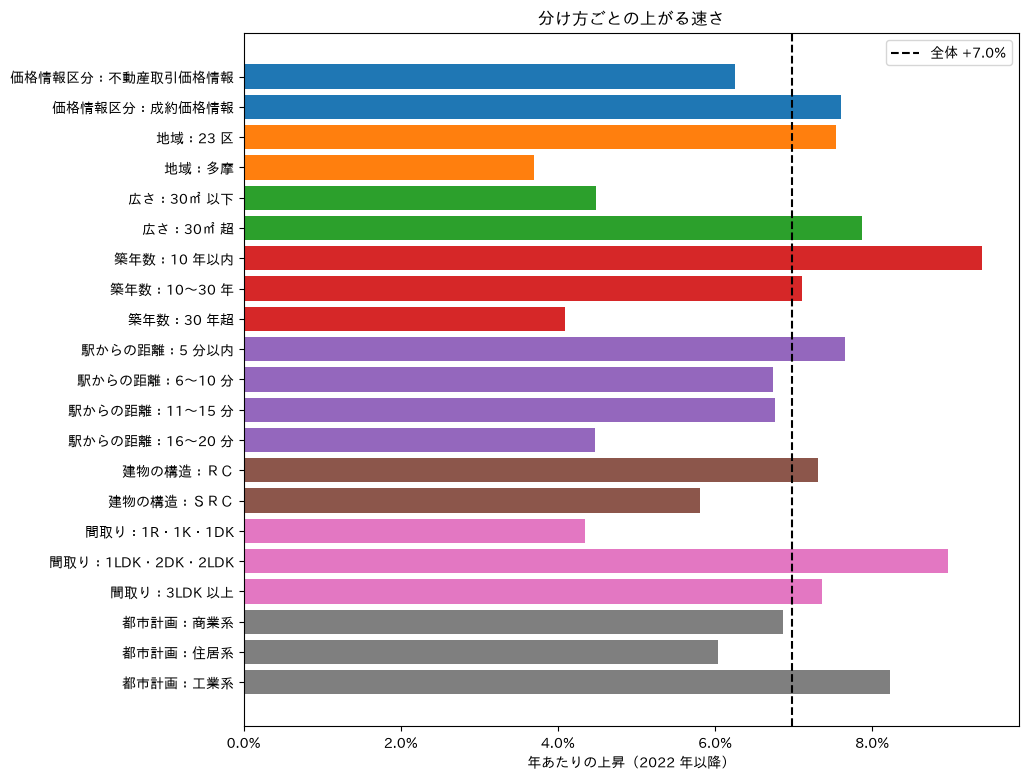

In [56]:
all_segments = {**segments, **more_segments}
summary = pd.DataFrame(
    [
        {"分け方": title, "グループ": name, "年あたりの上昇": growth_since_2022(mask)}
        for title, groups in all_segments.items()
        for name, mask in groups.items()
    ]
)
summary["ラベル"] = summary["分け方"] + "：" + summary["グループ"]
overall_growth = growth_since_2022(pd.Series(True, index=train.index))

fig, ax = plt.subplots(figsize=(10, 9))
colors = plt.cm.tab10(pd.factorize(summary["分け方"])[0] % 10)
ax.barh(summary["ラベル"][::-1], summary["年あたりの上昇"][::-1], color=colors[::-1])
ax.axvline(overall_growth, color="black", linestyle="--", label=f"全体 {overall_growth:+.1%}")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("年あたりの上昇（2022 年以降）")
ax.set_title("分け方ごとの上がる速さ")
ax.legend()
plt.show()

| 分け方 | 上がる速さ（2022 年以降、年あたり） |
|---|---|
| 駅からの距離 | 5 分以内 +7.7% / 6〜15 分 +6.7〜6.8% / 16〜20 分 +4.5% |
| 建物の構造 | RC +7.3% / SRC +5.8% |
| 間取り | 1R・1K・1DK +4.3% / 1LDK・2DK・2LDK +9.0% / 3LDK 以上 +7.4% |
| 都市計画 | 工業系 +8.2% / 商業系 +6.9% / 住居系 +6.0% |

- 駅に近いほど速く上がる。
- 間取りでは、ワンルーム系（+4.3%）と 1LDK・2LDK（+9.0%）で 2 倍違う。「広さ」で分けたときと同じ傾向。
- 構造の差（SRC が遅い）は、SRC に古い建物が多いせい（Q3）かもしれない。
- 工業系（準工業・工業）が一番速いのは意外。江東区の湾岸のタワーマンションなど、準工業地域に新しい大規模マンションが多いせいかもしれない（推測）。

これらの分け方は互いに重なっている（駅近・築浅・都心は同じ物件に重なりやすい）。どれが本当の原因かは、ここからは分からない。

### 市区町村ごと

市区町村ごとに上がる速さを求め、その市区町村の㎡単価の水準と並べる。「もともと高い場所ほど速く上がっているか」を見る。件数が 2,000 件以上の市区町村だけ。

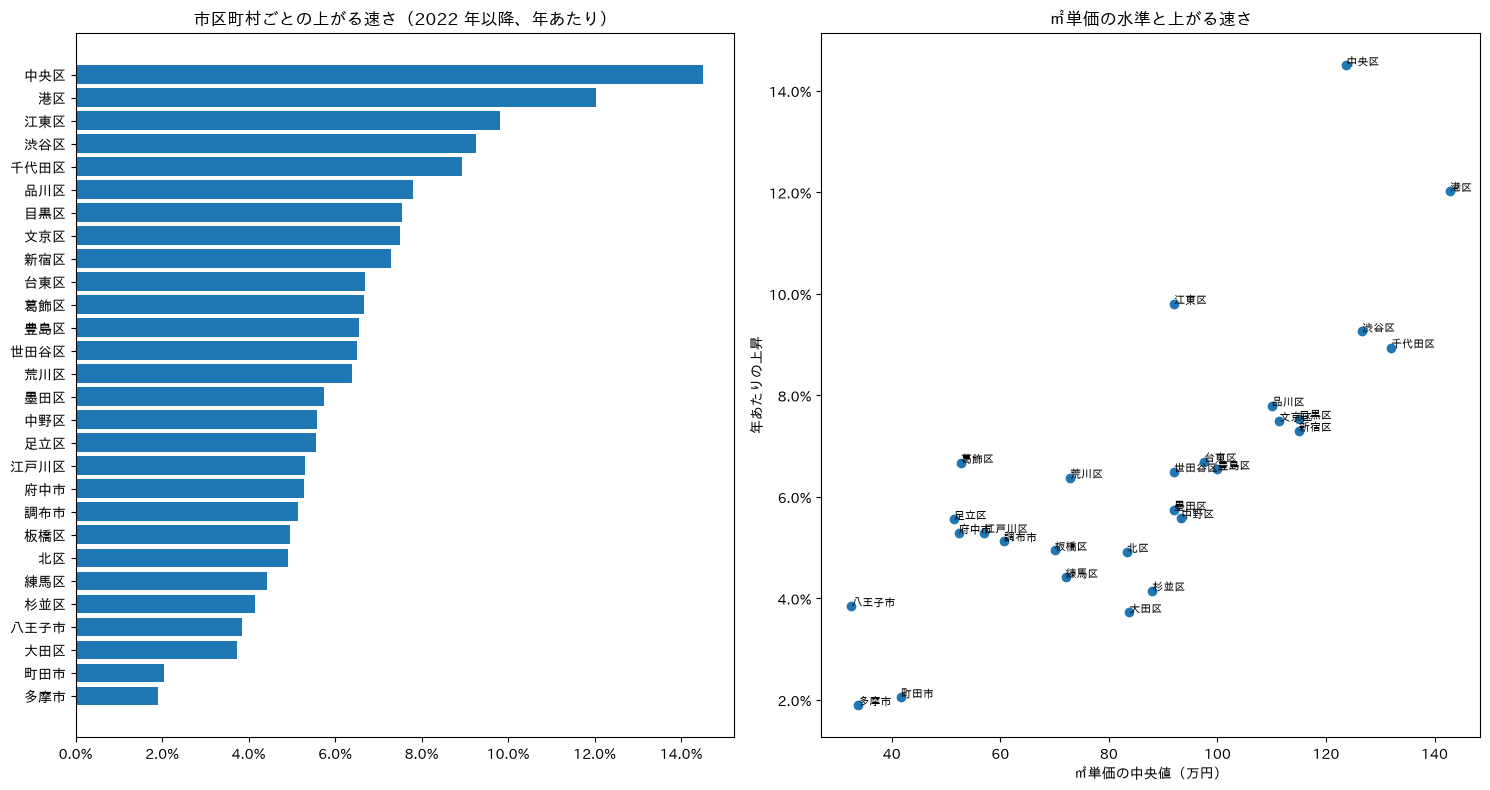

㎡単価の水準（log）と上がる速さの相関: 0.73


In [57]:
ward_rows = []
for ward, g in train.groupby("市区町村名"):
    if len(g) < 2000:
        continue
    ward_rows.append(
        {
            "市区町村名": ward,
            "件数": len(g),
            "㎡単価の中央値（万円）": g["㎡単価"].median() / 10_000,
            "年あたりの上昇（2022〜）": growth_since_2022(train["市区町村名"] == ward),
        }
    )
wards = pd.DataFrame(ward_rows).set_index("市区町村名").sort_values("年あたりの上昇（2022〜）")

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes[0].barh(wards.index, wards["年あたりの上昇（2022〜）"])
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_title("市区町村ごとの上がる速さ（2022 年以降、年あたり）")

ax = axes[1]
ax.scatter(wards["㎡単価の中央値（万円）"], wards["年あたりの上昇（2022〜）"])
for name, r in wards.iterrows():
    ax.annotate(name, (r["㎡単価の中央値（万円）"], r["年あたりの上昇（2022〜）"]), fontsize=8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("㎡単価の中央値（万円）")
ax.set_ylabel("年あたりの上昇")
ax.set_title("㎡単価の水準と上がる速さ")
plt.tight_layout()
plt.show()

corr = np.corrcoef(np.log(wards["㎡単価の中央値（万円）"]), wards["年あたりの上昇（2022〜）"])[0, 1]
print(f"㎡単価の水準（log）と上がる速さの相関: {corr:.2f}")

- **市区町村で、上がる速さは 2% から 14.5% まで 7 倍違う**。中央区 +14.5%、港区 +12.0%、江東区 +9.8% が速く、多摩市・町田市は約 2%。
- **もともと㎡単価が高い場所ほど、速く上がっている**（相関 0.73）。都心の高い場所と郊外の安い場所の差が、年々開いている。
- 江東区は㎡単価の水準のわりに速い（湾岸の新しいマンションの影響かもしれない）。

これまでの分け方の中で、**上がる速さの違いが一番大きいのは場所（市区町村）**。全体の指数で一律に延ばすと、都心は低く、郊外は高く予測しすぎることになる。指数を分けるなら、まず市区町村（または㎡単価の水準の帯）で分けるのがよさそう。ただし市区町村ごとに分けると 1 本あたりの件数が減り、延ばした値がぶれやすくなる。

## Q11. 相場の上昇を考えるとき、市区町村をどうグループ分けするか

### 候補

| 候補 | 分け方 | 考え方 |
|---|---|---|
| A. 全体で 1 本 | 分けない | 基準 |
| B. 地域 6 つ | 都心 5 区・城南・城西・城北・城東・多摩 | 不動産業界でよく使う分け方。分かりやすい。ただし区の割り振りは資料によって違う |
| C. 市区町村の価格帯 5 つ | 2021 年までの㎡単価の中央値で、市区町村を 5 段階に分ける | Q10 で「もともと高い場所ほど速く上がる」（相関 0.73）と分かったので、その水準で分ける |
| D. 地区の価格帯 5 つ | C と同じことを地区名の単位で行う | 同じ区の中でも、湾岸と内陸のように水準が違う場所を分けられる |
| E. 市区町村ごと | 51 に分ける | 一番細かい。件数の少ない市区町村ではぶれる |

C・D は、上がる速さそのものではなく、2021 年までの㎡単価の水準で分ける。上がる速さで直接分けると、たまたまのぶれに合わせたグループになりやすいため。

### 比べ方

「過去の上がる速さを先へ延ばしたら、その後の相場の変化をどれくらい当てられるか」を、train の中で試す。

1. 区切りの四半期（2023Q2〜2024Q3 の 6 通り）を決める
2. 区切りまでの直近 8 または 12 四半期で、グループごとの上がる速さ（直線の傾き）を求める
3. その速さで 1〜3 四半期先まで延ばし、実際の相場の変化と比べる

答え合わせは、どの候補でも同じもの（市区町村ごとの相場の指数の変化）を使う。グループが粗いほど、市区町村ごとの違いを見落とすぶん外れる。細かいほど、件数が少なくて速さの推定がぶれるぶん外れる。比べるのは、モデルの精度ではなく、相場の延ばし方の当たり具合。

「延ばさない」（最後の水準のまま。決定木の予測のイメージ）も比べる。

In [58]:
AREAS = {
    "都心 5 区": ["千代田区", "中央区", "港区", "新宿区", "渋谷区"],
    "城南": ["品川区", "目黒区", "大田区", "世田谷区"],
    "城西": ["中野区", "杉並区", "練馬区"],
    "城北": ["文京区", "豊島区", "北区", "板橋区"],
    "城東": ["台東区", "墨田区", "江東区", "荒川区", "足立区", "葛飾区", "江戸川区"],
}
ward_to_area = {w: a for a, wards_ in AREAS.items() for w in wards_}

early = train[train["時期_数値"] < 2021]
ward_level = np.log(early.groupby("市区町村名")["㎡単価"].median())
district_level = np.log(early.groupby("地区名")["㎡単価"].median())

PRICE_TIERS = ["1（安い）", "2", "3", "4", "5（高い）"]
GROUPINGS = {
    "A. 全体で 1 本": pd.Series("全体", index=train.index),
    "B. 地域 6 つ": train["市区町村名"].map(ward_to_area).fillna("多摩"),
    "C. 市区町村の価格帯 5 つ": pd.qcut(train["市区町村名"].map(ward_level), 5, labels=PRICE_TIERS).astype(str),
    "D. 地区の価格帯 5 つ": pd.qcut(
        train["地区名"].map(district_level).fillna(train["市区町村名"].map(ward_level)), 5, labels=PRICE_TIERS
    ).astype(str),
    "E. 市区町村ごと": train["市区町村名"],
}
MIN_ROWS = 1500

In [59]:
group_index = {
    name: {g: np.log(market_index(train[groups == g]) / 100) for g in groups.unique() if (groups == g).sum() >= MIN_ROWS}
    for name, groups in GROUPINGS.items()
}
ward_truth = group_index["E. 市区町村ごと"]
quarter_counts = train.groupby(["市区町村名", "時期_数値"]).size()
CUTS = [2023.25, 2023.5, 2023.75, 2024.0, 2024.25, 2024.5]


def backtest(name, n_quarters=None):
    groups = GROUPINGS[name]
    ward_group = groups.groupby(train["市区町村名"]).first()
    errors, weights = [], []
    for cut in CUTS:
        slopes = {}
        for g, idx in group_index[name].items():
            past = idx[(idx.index > cut - (n_quarters or 0) / 4) & (idx.index <= cut)]
            slopes[g] = 0.0 if n_quarters is None else np.polyfit(past.index, past.values, 1)[0]
        for ward, truth in ward_truth.items():
            slope = slopes.get(ward_group[ward])
            if slope is None:
                continue
            for h in [0.25, 0.5, 0.75]:
                if cut + h in truth.index:
                    errors.append(truth[cut + h] - truth[cut] - slope * h)
                    weights.append(quarter_counts.get((ward, cut + h), 0))
    errors, weights = np.array(errors), np.array(weights)
    return np.sqrt(np.sum(weights * errors**2) / weights.sum())


result = pd.DataFrame(
    {
        "延ばさない": [backtest(name) for name in GROUPINGS],
        "直近 8 四半期の速さで延ばす": [backtest(name, 8) for name in GROUPINGS],
        "直近 12 四半期の速さで延ばす": [backtest(name, 12) for name in GROUPINGS],
    },
    index=list(GROUPINGS),
)
result["グループの数"] = [len(group_index[name]) for name in GROUPINGS]
result.round(4)

,延ばさない,直近 8 四半期の速さで延ばす,直近 12 四半期の速さで延ばす,グループの数
A. 全体で 1 本,0.0551,0.0353,0.0341,1
B. 地域 6 つ,0.0551,0.0328,0.0328,6
C. 市区町村の価格帯 5 つ,0.0551,0.0332,0.0329,5
D. 地区の価格帯 5 つ,0.0551,0.0338,0.0334,5
E. 市区町村ごと,0.0551,0.0335,0.0325,32


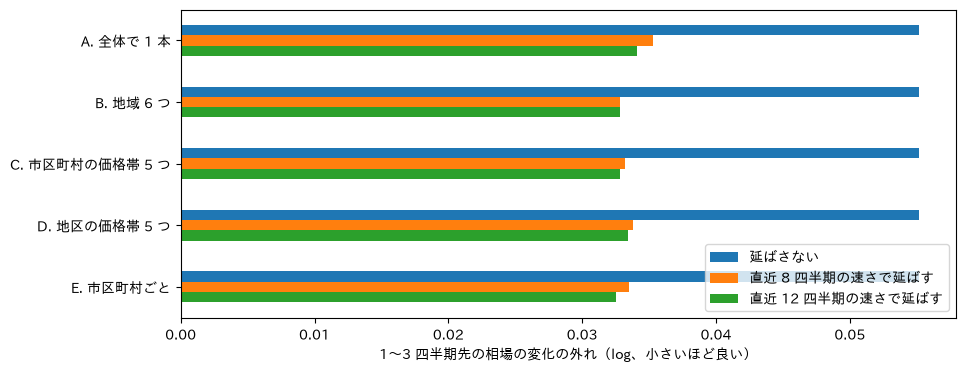

In [60]:
fig, ax = plt.subplots(figsize=(10, 4))
result[["延ばさない", "直近 8 四半期の速さで延ばす", "直近 12 四半期の速さで延ばす"]].plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_xlabel("1〜3 四半期先の相場の変化の外れ（log、小さいほど良い）")
ax.legend(loc="lower right")
plt.show()

In [61]:
slopes = []
for name in ["B. 地域 6 つ", "C. 市区町村の価格帯 5 つ", "D. 地区の価格帯 5 つ"]:
    groups = GROUPINGS[name]
    for g, idx in group_index[name].items():
        recent = idx[idx.index >= 2022]
        members = sorted(train.loc[groups == g, "市区町村名"].unique())
        slopes.append(
            {
                "候補": name,
                "グループ": g,
                "件数": (groups == g).sum(),
                "年あたりの上昇（2022〜）": np.exp(np.polyfit(recent.index, recent.values, 1)[0]) - 1,
                "含まれる市区町村（例）": "、".join(members[:6]) + ("…" if len(members) > 6 else ""),
            }
        )
pd.DataFrame(slopes).sort_values(["候補", "グループ"]).set_index(["候補", "グループ"]).style.format({"年あたりの上昇（2022〜）": "{:+.1%}"})

- **一番大きいのは「延ばすかどうか」**。延ばさないと 0.055、全体 1 本の速さで延ばすだけで 0.034 まで減る。
- **グループに分けると、さらに少しだけ減る**（0.034 → 0.033）。B（地域 6 つ）・C（市区町村の価格帯 5 つ）・E（市区町村ごと）はほぼ同じ。D（地区の価格帯）は効果が小さい。
- E（市区町村ごと）は、直近 12 四半期で速さを決めれば一番良いが、8 四半期だと B・C より悪い。グループが小さいと、速さの推定がぶれやすい。
- B と C は、ほぼ同じグループになる。C の一番高い価格帯は、都心 5 区（千代田・中央・港・新宿・渋谷）とちょうど一致した。上がる速さが一番違う（年 +11%）のがこのグループ。
- ただし C の速さは、価格帯の順にきれいには並ばない（価格帯 2 が +7.0%、価格帯 3 が +5.1%）。はっきりしているのは「一番高い価格帯（都心 5 区）が飛び抜けて速い」「一番安い価格帯（多摩の多く）が遅い」の 2 点。
- E は件数 1,500 件以上の 32 市区町村だけで速さを求めている（ほかの市区町村は比較から外れる）。

答え合わせに使った市区町村ごとの指数そのものにもぶれがあるので、候補どうしの小さな差（0.001 程度）は誤差の範囲かもしれない。

### Q11 のまとめ

- 相場の上昇を延ばすこと自体が一番効く。グループ分けは、その上に少し足すもの。
- 分けるなら、**C. 市区町村の価格帯（5 つ）がいちばん筋が通る**と考える。
  - Q10 で見た「もともと高い場所ほど速く上がる」という関係に、直接もとづいている
  - 上がる速さそのものではなく水準で分けるので、たまたまのぶれに合わせたグループになりにくい
  - 価格帯の境目は、CV の fold ごとに、その fold の学習データだけで決められる
  - 結果は B（地域 6 つ）とほぼ同じ。説明のしやすさを優先するなら B でもよい
- 市区町村ごと（E）は、件数の少ない市区町村で速さがぶれるので避ける。どうしても細かくしたいなら、市区町村の速さをグループの速さに近づけて（縮小推定）ぶれを抑える方法がある。

## Q12. 場所の列（市区町村名・地区名・最寄駅）をどう使うか

### 3 列の関係と件数

In [62]:
train["地区"] = train["市区町村名"] + "・" + train["地区名"]
test["地区"] = test["市区町村名"] + "・" + test["地区名"]

rows = []
for col in ["市区町村名", "地区名", "地区", "最寄駅：名称"]:
    counts = train[col].value_counts()
    rows.append(
        {
            "列": col,
            "種類数": len(counts),
            "100 件未満の値に入る行の割合": train[col].map(counts).lt(100).mean(),
            "test で train にない値の行": (~test[col].isin(counts.index) & test[col].notna()).sum(),
        }
    )
pd.DataFrame(rows).set_index("列").style.format({"100 件未満の値に入る行の割合": "{:.1%}"})

,種類数,100 件未満の値に入る行の割合,test で train にない値の行
列,,,
市区町村名,51,0.0%,0
地区名,1210,11.9%,4
地区,1328,13.6%,5
最寄駅：名称,630,3.1%,1


`地区` は `市区町村名` と `地区名` をつないだ列（例: 「中野区・本町」）。

In [63]:
wards_per_name = train.groupby("地区名")["市区町村名"].nunique()
shared = wards_per_name[wards_per_name > 1]
print(f"2 つ以上の市区町村にある地区名: {len(shared)} 種類（train の {train['地区名'].isin(shared.index).mean():.1%} の行）")
print(shared.sort_values(ascending=False).head(8).to_dict())

honcho = train[train["地区名"] == "本町"]
honcho.groupby("市区町村名").agg(
    **{"件数": (TARGET, "size"), "㎡単価の中央値（万円）": ("㎡単価", lambda s: s.median() / 10_000)}
).sort_values("件数", ascending=False).head(8).round(0)

2 つ以上の市区町村にある地区名: 63 種類（train の 10.0% の行）
{'本町': 12, '栄町': 10, '中町': 8, '南町': 7, '緑町': 7, '新町': 6, '東町': 5, '天神町': 4}


,件数,㎡単価の中央値（万円）
市区町村名,,
中野区,588,96.0
渋谷区,545,105.0
小金井市,386,77.0
板橋区,236,87.0
国分寺市,150,112.0
東村山市,133,30.0
府中市,96,64.0
東久留米市,74,52.0


- **`地区名` だけでは場所が決まらない**。「本町」は 12 の市区町村にあり、㎡単価の中央値は渋谷区 105 万円、東村山市 30 万円と 3 倍以上違う。同じ名前の地区名は 63 種類あり、train の 10% の行が当てはまる。今の特徴量は `地区名` をそのまま使っているので、これらの行は**別の場所がまとめて扱われている**。`市区町村名` と組み合わせた `地区` にすれば区別できる。
- **13.6% の行は、100 件未満の地区に入っている**。Q9 で見たとおり、LightGBM はデフォルトでは件数 100 件未満のカテゴリの値では分岐しないので、これらの地区の違いはモデルが使えていない可能性がある。
- test で train にない地区・駅は数件だけ。

### 場所の列で、価格の違いをどれくらい説明できるか

「説明できる割合」は、**その列の値ごとの平均で価格を言い当てたとき、全体の平均で言い当てたときと比べて、ずれがどれだけ減るか**（決定係数 R²）。

例: ㎡単価が 渋谷区 150・130 万円、足立区 70・50 万円の 4 件。

| 言い当て方 | 予測 | ずれ | ずれの二乗の平均 |
|---|---|---|---|
| 全体の平均 | 全部 100 | 50, 30, 30, 50 | 1700 |
| 市区町村ごとの平均 | 渋谷区 140、足立区 60 | 10, 10, 10, 10 | 100 |

ずれの二乗が 1700 → 100 に減ったので、説明できる割合は 1 − 100/1700 = 94%。残りの 6% は、同じ市区町村の中での違い。

- 時期・面積・築年数の効果は先に取り除く。新しい物件が多い地区は、場所と関係なく高く見えてしまうため。
- 値の種類が多い列ほど、割合は高めに出る。極端には 1 件しかない値は、その値の平均が自分の価格そのものなので、ずれが 0 になる。


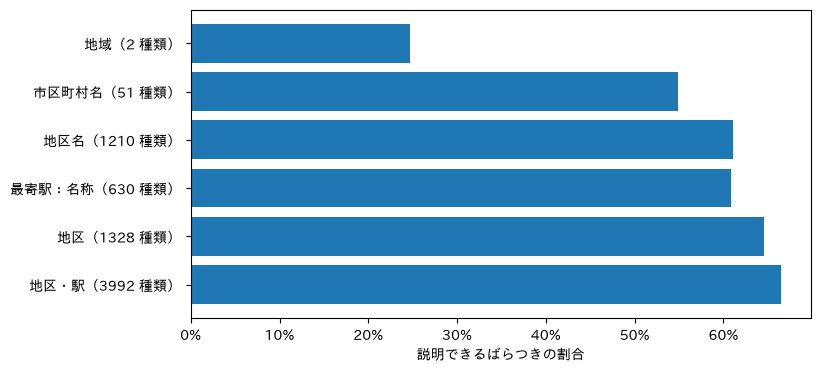

In [64]:
def remove_effects(y, keys, n_iter=10):
    effects = {k: pd.Series(0.0, index=y.index) for k in keys}
    for _ in range(n_iter):
        for k in keys:
            others = sum(v for kk, v in effects.items() if kk != k)
            effects[k] = (y - others).groupby(train[k].astype(str)).transform("mean")
    return y - sum(effects.values())


resid_loc = remove_effects(np.log(train["㎡単価"]), ["取引時期", "面積帯", "建築年帯"])
train["地区・駅"] = train["地区"] + "・" + train["最寄駅：名称"].fillna("欠損")

explained = {}
for col in ["地域", "市区町村名", "地区名", "最寄駅：名称", "地区", "地区・駅"]:
    group_mean = resid_loc.groupby(train[col]).transform("mean")
    explained[f"{col}（{train[col].nunique()} 種類）"] = 1 - ((resid_loc - group_mean) ** 2).sum() / ((resid_loc - resid_loc.mean()) ** 2).sum()
explained = pd.Series(explained)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(explained.index[::-1], explained.values[::-1])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("説明できるばらつきの割合")
plt.show()

| 列 | 説明できる割合 |
|---|---|
| 地域（23 区 / 多摩） | 25% |
| 市区町村名 | 55% |
| 最寄駅：名称 | 61% |
| 地区名 | 61% |
| 地区（市区町村名＋地区名） | 65% |
| 地区・駅 | 66% |

- 市区町村だけで半分以上、地区まで細かくすると 3 分の 2 が説明できる。**場所は価格を決めるいちばん大きな要因**。
- `地区名` を `地区` に直すだけで 61% → 65% に上がる。同じ名前の地区を分けた効果。
- 駅は地区とほぼ同じくらいの情報を持つ。地区に駅を足しても、あまり増えない（65% → 66%。種類が増えたぶん高めに出ていることも考えると、ほぼ増えない）。

### 地区を「性格」でグループに分ける

価格の水準だけでなく、どんな物件が売れている地区かで分けてみる。30 件以上ある地区について、次の 4 つの特徴で k-means（6 グループ）にかける。

| 特徴 | 意味 |
|---|---|
| 価格の水準 | 時期・面積・建築年をそろえた log(㎡単価) の平均（上の `resid_loc`） |
| ワンルーム率 | 30㎡ 以下の物件の割合 |
| 築年数の中央値 | 取引した時点の築年数 |
| 駅距離の中央値 | 最寄駅からの徒歩分（30 分以上は除く） |

In [65]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

distance_min = pd.to_numeric(train["最寄駅：距離（分）"], errors="coerce")
district = (
    pd.DataFrame(
        {
            "地区": train["地区"],
            "市区町村名": train["市区町村名"],
            "価格の水準": resid_loc,
            "ワンルーム率": (train["面積_数値"] <= 30).astype(float),
            "築年数": train["築年数"],
            "駅距離": distance_min,
        }
    )
    .groupby("地区")
    .agg(
        市区町村名=("市区町村名", "first"),
        件数=("価格の水準", "size"),
        価格の水準=("価格の水準", "mean"),
        ワンルーム率=("ワンルーム率", "mean"),
        築年数=("築年数", "median"),
        駅距離=("駅距離", "median"),
    )
)
district = district[district["件数"] >= 30].dropna()
CLUSTER_FEATURES = ["価格の水準", "ワンルーム率", "築年数", "駅距離"]
kmeans = KMeans(n_clusters=6, n_init=20, random_state=0).fit(StandardScaler().fit_transform(district[CLUSTER_FEATURES]))
district["グループ"] = kmeans.labels_

profile = district.groupby("グループ").agg(
    地区の数=("件数", "size"),
    取引件数=("件数", "sum"),
    価格の水準=("価格の水準", "mean"),
    ワンルーム率=("ワンルーム率", "mean"),
    築年数=("築年数", "median"),
    駅距離=("駅距離", "median"),
)
profile["価格の水準（倍）"] = np.exp(profile["価格の水準"])
profile["多い市区町村"] = district.groupby("グループ")["市区町村名"].agg(lambda s: "、".join(s.value_counts().index[:4]))
profile["地区の例"] = district.groupby("グループ").apply(lambda g: "、".join(g.nlargest(4, "件数").index))
profile.sort_values("価格の水準", ascending=False).round(2)

,地区の数,取引件数,価格の水準,ワンルーム率,築年数,駅距離,価格の水準（倍）,多い市区町村,地区の例
グループ,,,,,,,,,
2,186,52936,0.33,0.20,18.0,5.0,1.39,新宿区、渋谷区、世田谷区、港区,江東区・豊洲、中央区・晴海、中央区・勝どき、港区・芝浦
5,123,22728,0.19,0.34,28.0,6.0,1.20,世田谷区、大田区、目黒区、杉並区,江東区・東陽、渋谷区・代々木、新宿区・新宿、板橋区・高島平
4,271,61765,0.02,0.48,16.0,5.0,1.02,大田区、板橋区、新宿区、台東区,江東区・亀戸、品川区・西五反田、新宿区・西新宿、品川区・南大井
3,215,36825,-0.34,0.11,19.0,7.0,0.71,足立区、府中市、葛飾区、八王子市,三鷹市・下連雀、江東区・東雲、荒川区・南千住、江東区・南砂
0,138,16102,-0.44,0.06,21.0,15.0,0.65,足立区、江戸川区、世田谷区、八王子市,江東区・東砂、江東区・塩浜、八王子市・別所、葛飾区・青戸
1,67,7616,-0.86,0.10,38.0,11.0,0.42,八王子市、多摩市、日野市、青梅市,多摩市・落合、東久留米市・滝山、調布市・染地、板橋区・中台


### グループの数 k をエルボー法で決める

k を 2〜12 で変えて、各地区とグループの中心との距離の二乗の合計（inertia）を見る。k を増やすほど必ず小さくなるので、減り方が急に鈍る「肘」の k を選ぶ。目安として、シルエット係数（自分のグループに近く、隣のグループから遠いほど 1 に近い）も並べる。


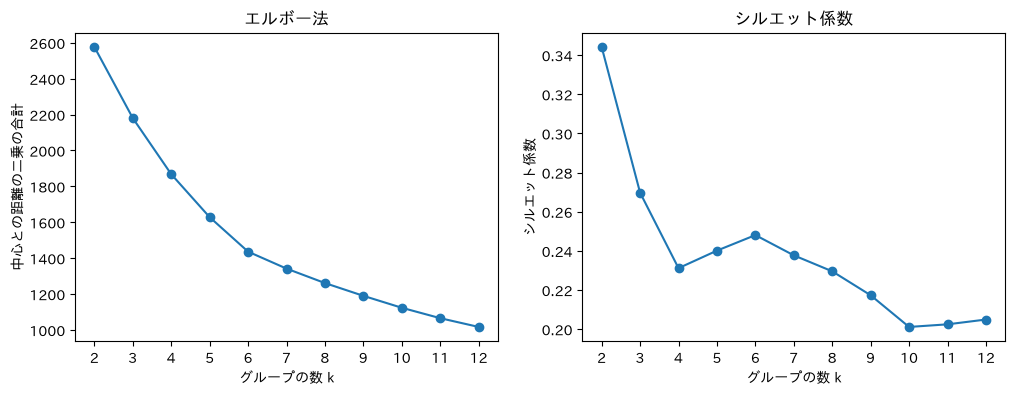

,inertia,シルエット係数,inertia の減り
k,,,
2,2576.905,0.344,NaN
3,2180.263,0.270,396.642
4,1867.824,0.231,312.439
5,1628.321,0.240,239.503
6,1436.225,0.248,192.096
7,1341.851,0.238,94.374
8,1261.281,0.230,80.570
9,1190.126,0.217,71.155
10,1123.624,0.201,66.502


In [66]:
from sklearn.metrics import silhouette_score

scaled = StandardScaler().fit_transform(district[CLUSTER_FEATURES])
ks = range(2, 13)
inertia, silhouette = [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=20, random_state=0).fit(scaled)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(scaled, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, marker="o")
axes[0].set(xlabel="グループの数 k", ylabel="中心との距離の二乗の合計", title="エルボー法")
axes[1].plot(ks, silhouette, marker="o")
axes[1].set(xlabel="グループの数 k", ylabel="シルエット係数", title="シルエット係数")
for ax in axes:
    ax.set_xticks(list(ks))
plt.show()

elbow = pd.DataFrame({"k": ks, "inertia": inertia, "シルエット係数": silhouette}).set_index("k")
elbow["inertia の減り"] = -elbow["inertia"].diff()
elbow.round(3)


- **肘は k = 6**。inertia の減りは k = 5→6 で 192 あるが、6→7 で 94 と半分になり、その先もゆるやかに減るだけ。
- シルエット係数も、k = 4 以降では k = 6 が一番高い（0.248）。k = 2 が一番高いが、2 つでは「高い地区・安い地区」程度にしか分かれず、性格の違いが見えない。
- よって k = 6 を使う。ただしシルエット係数は 0.25 くらいと低めで、地区ははっきりした塊に分かれているわけではなく、連続的に並んでいるものを区切っている。


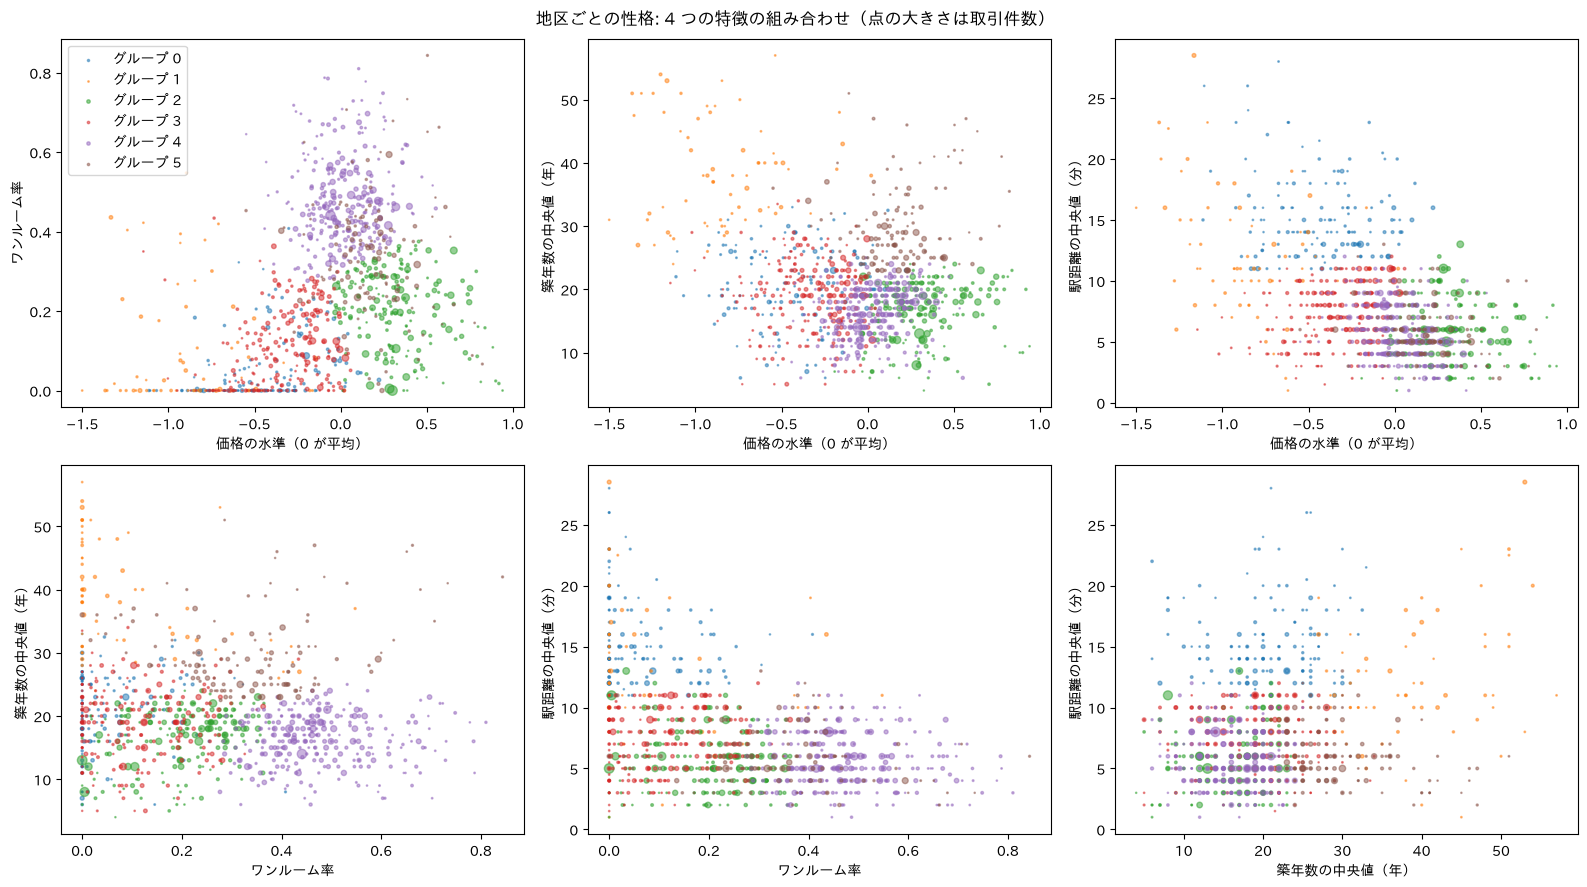

In [67]:
from itertools import combinations

AXIS_LABELS = {"価格の水準": "価格の水準（0 が平均）", "ワンルーム率": "ワンルーム率", "築年数": "築年数の中央値（年）", "駅距離": "駅距離の中央値（分）"}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (x, y) in zip(axes.flat, combinations(CLUSTER_FEATURES, 2)):
    for g, rows in district.groupby("グループ"):
        ax.scatter(rows[x], rows[y], s=rows["件数"] / 40, alpha=0.5, color=f"C{g}", label=f"グループ {g}")
    ax.set(xlabel=AXIS_LABELS[x], ylabel=AXIS_LABELS[y])
axes.flat[0].legend(markerscale=0.5)
fig.suptitle("地区ごとの性格: 4 つの特徴の組み合わせ（点の大きさは取引件数）")
fig.tight_layout()
plt.show()


6 つのグループの性格（価格の水準が高い順）:

| グループ | 価格の水準 | ワンルーム率 | 築年数 | 駅距離 | 性格 | 例 |
|---|---|---|---|---|---|---|
| 2 | 1.39 倍 | 20% | 18 年 | 5 分 | **都心・湾岸のファミリー向け** | 豊洲、晴海、勝どき、芝浦 |
| 5 | 1.20 倍 | 34% | 28 年 | 6 分 | **古めの好立地** | 東陽、代々木、新宿 |
| 4 | 1.02 倍 | 48% | 16 年 | 5 分 | **駅近のワンルーム街** | 亀戸、西五反田、西新宿、南大井 |
| 3 | 0.71 倍 | 11% | 19 年 | 7 分 | **下町・郊外のファミリー向け** | 三鷹市下連雀、東雲、南千住、南砂 |
| 0 | 0.65 倍 | 6% | 21 年 | 15 分 | **駅から遠いファミリー向け** | 東砂、塩浜、八王子市別所、青戸 |
| 1 | 0.42 倍 | 10% | 38 年 | 11 分 | **郊外の古い大規模団地** | 多摩市落合、東久留米市滝山、調布市染地 |

（価格の水準は、時期・面積・建築年をそろえた㎡単価の、全体の平均に対する倍率）

- 同じ江東区でも、豊洲（グループ 2）、亀戸（4）、東雲・南砂（3）、東砂・塩浜（0）と分かれる。**市区町村より細かい単位で、性格の違う場所が混ざっている**。
- グループ 1 の例（落合・滝山・染地）は、多摩ニュータウンなどの古い大規模団地がある地区と思われる（推測）。
- 散布図で、どの特徴でどのグループが分かれているかが見える。
  - 価格の水準 × ワンルーム率（左上）: 高い地区はファミリー向け（グループ 2）、真ん中の地区はワンルームが多い（4）、安い地区はファミリー向け（3）と、山形に並ぶ。
  - 価格の水準 × 築年数（中央上）: グループ 1 は築年数が長く（30〜50 年）、価格も低い。グループ 5 は築年数がやや長いが、価格は平均より高い。
  - 価格の水準 × 駅距離（右上）: グループ 0 は駅距離が長い（10 分以上）。価格とワンルーム率だけでは、グループ 3 と重なって見分けられない。
- どの図でも、グループの境目で点が重なっている。シルエット係数が低い（0.25）ことと同じで、地区ははっきりした塊ではなく、連続的に並んでいる。

注意: グループは価格（価格の水準）を使って作っているので、特徴量にするなら CV の fold ごとに学習データだけで作り直す必要がある。

### Q12 のまとめ

場所の列の使い方の案:

| 案 | 内容 | 期待 | 工程 |
|---|---|---|---|
| **1. `地区` の列を作る**（おすすめ・最優先） | `市区町村名`＋`地区名` をつなぐ。今は同じ名前の別の地区（train の 10% の行）がまとめて扱われている | 説明できる割合 61% → 65%。手間がとても小さい | 2. 特徴量 |
| 2. 地区の相場を数値の列にする（target encoding） | fold ごとに、学習データから地区ごとの㎡単価の平均を計算して列にする。件数の少ない地区は、市区町村の平均に近づける | 100 件未満の地区（13.6% の行）も使えるようになる | 2. 特徴量（PR #3 のとおり、fold ごとに計算する仕組みが要る） |
| 3. 地区の性格のグループ | 上の 6 グループを列にする | 件数の少ない地区を、似た地区とまとめて扱える | 2. 特徴量（fold ごとに作る） |
| 4. 価格帯ごとの相場の上昇 | Q11 のとおり | Issue #7 | 4. 目的変数 |
| 5. 外部データ | 地区や駅の緯度経度（都心までの距離・方角）、駅の路線・乗降客数など。2025 年第 2 四半期以前のデータに限る（docs/columns.md ※2） | 近くの地区どうしの関係や、地区名で表しきれない場所の違いを足せる | 2. 特徴量 |

## Q13. 外部データ: 地区の緯度経度

### 使うデータ

国土交通省「位置参照情報ダウンロードサービス」の**大字・町丁目レベル位置参照情報（東京都、2023 年版）**。町丁目ごとの代表点の緯度経度。

| 項目 | 内容 |
|---|---|
| 版 | 17.0b（2023 年版）。メタデータの作成日 2024-01-31、ファイルの更新日 2024-03-25 |
| 基準日 | 2025 年第 2 四半期より前。test 期間の状態は含まない |
| 入手先 | https://nlftp.mlit.go.jp/isj/ （利用約款: https://nlftp.mlit.go.jp/isj/agreement.html ） |

出典: 「大字・町丁目レベル位置参照情報 国土交通省」（2023 年版（17.0b）、東京都、ファイル名 `13000-17.0b.zip`）を加工して作成。丁目を外して町名ごとに緯度・経度を平均した。

外部データは基準日（いつ時点の状態か）が 2025 年第 2 四半期以前かで判断する。2025 年度版（19.0b）は 2025 年度の状態を含むので使わない。2024 年度版（18.0b）も使えるが、2023 年版でほぼ全部の行が結合できるので変えない。

データは `../external_data/` にダウンロードする（なければダウンロードする）。

In [68]:
import io
import urllib.request
import zipfile
from pathlib import Path

ISJ_URL = "https://nlftp.mlit.go.jp/isj/dls/data/17.0b/13000-17.0b.zip"
ISJ_ZIP = Path("../external_data/13000-17.0b.zip")
if not ISJ_ZIP.exists():
    ISJ_ZIP.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(ISJ_URL, ISJ_ZIP)

with zipfile.ZipFile(ISJ_ZIP) as z:
    csv_name = next(n for n in z.namelist() if n.endswith(".csv"))
    towns = pd.read_csv(io.BytesIO(z.read(csv_name)), encoding="cp932")
towns.head()

,都道府県コード,都道府県名,市区町村コード,市区町村名,大字町丁目コード,大字町丁目名,緯度,経度,原典資料コード,大字・字・丁目区分コード
0,13,東京都,13101,千代田区,131010001001,内幸町一丁目,35.670839,139.758119,0,3
1,13,東京都,13101,千代田区,131010001002,内幸町二丁目,35.670812,139.754182,0,3
2,13,東京都,13101,千代田区,131010002001,霞が関一丁目,35.673944,139.752558,0,3
3,13,東京都,13101,千代田区,131010002002,霞が関二丁目,35.675551,139.750413,0,3
4,13,東京都,13101,千代田区,131010002003,霞が関三丁目,35.671825,139.746988,0,3


### 地区名と結合できるか

位置参照情報は丁目ごと（「西五反田一丁目」など）、`地区名` は丁目のない町名（「西五反田」）。丁目を外して町名ごとに緯度経度を平均し、`市区町村名`＋`地区名` で結合する。

In [69]:
towns["町名"] = towns["大字町丁目名"].str.replace(r"[一二三四五六七八九十]+丁目$", "", regex=True)
town_points = towns.groupby(["市区町村名", "町名"], as_index=False)[["緯度", "経度"]].mean()

for df in (train, test):
    merged = df[["市区町村名", "地区名"]].merge(
        town_points, left_on=["市区町村名", "地区名"], right_on=["市区町村名", "町名"], how="left"
    )
    df["緯度"] = merged["緯度"].to_numpy()
    df["経度"] = merged["経度"].to_numpy()

print(f"緯度経度が付いた行: train {train['緯度'].notna().mean():.4%} / test {test['緯度'].notna().mean():.4%}")
print("付かなかった地区:", train.loc[train["緯度"].isna(), "地区"].value_counts().to_dict())

緯度経度が付いた行: train 99.9985% / test 99.9898%
付かなかった地区: {'昭島市・代官山': 3}


ほぼ全部の行に緯度経度が付く。付かなかったのは昭島市・代官山（train 3 件、test 3 件）だけ。

### 地図で見る

地区ごとの「価格の水準」（Q12 の、時期・面積・建築年をそろえた log(㎡単価) の平均）を地図に塗る。

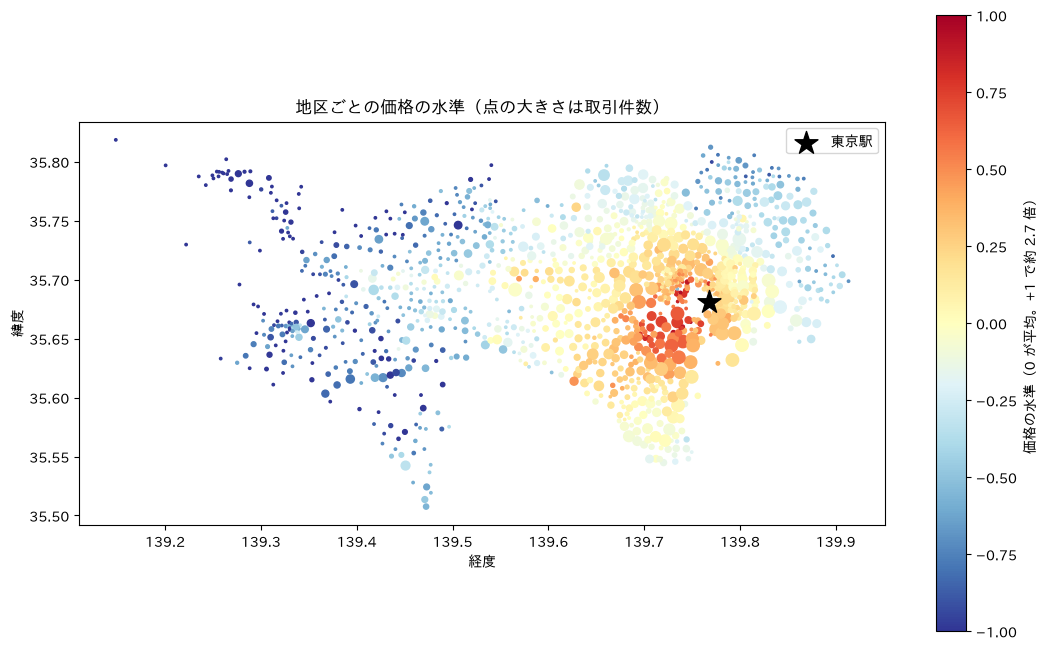

In [70]:
TOKYO_STATION = (35.681236, 139.767125)
KM_PER_DEG_LAT = 111.0
KM_PER_DEG_LON = 111.0 * np.cos(np.radians(TOKYO_STATION[0]))

for df in (train, test):
    dy = (df["緯度"] - TOKYO_STATION[0]) * KM_PER_DEG_LAT
    dx = (df["経度"] - TOKYO_STATION[1]) * KM_PER_DEG_LON
    df["東京駅からの距離_km"] = np.hypot(dx, dy)
    df["東京駅からの方角"] = np.degrees(np.arctan2(dy, dx))  # 東が 0 度、北が 90 度

district_map = (
    pd.DataFrame({"地区": train["地区"], "地域": train["地域"], "緯度": train["緯度"], "経度": train["経度"],
                  "距離": train["東京駅からの距離_km"], "価格の水準": resid_loc})
    .dropna()
    .groupby("地区")
    .agg(地域=("地域", "first"), 緯度=("緯度", "first"), 経度=("経度", "first"), 距離=("距離", "first"),
         価格の水準=("価格の水準", "mean"), 件数=("価格の水準", "size"))
)

fig, ax = plt.subplots(figsize=(13, 8))
sc = ax.scatter(district_map["経度"], district_map["緯度"], c=district_map["価格の水準"], s=np.clip(district_map["件数"] / 10, 3, 80),
                cmap="RdYlBu_r", vmin=-1, vmax=1)
ax.scatter(*TOKYO_STATION[::-1], marker="*", s=300, color="black", label="東京駅")
fig.colorbar(sc, ax=ax, label="価格の水準（0 が平均。+1 で約 2.7 倍）")
ax.set_aspect(1 / np.cos(np.radians(TOKYO_STATION[0])))
ax.set_xlabel("経度")
ax.set_ylabel("緯度")
ax.set_title("地区ごとの価格の水準（点の大きさは取引件数）")
ax.legend()
plt.show()

- 一番高い場所（赤）は、東京駅のまわりではなく、**東京駅の南西**（港区・千代田区・渋谷区あたり）に集まっている。
- 東京駅から同じくらいの距離でも、西〜南西は高く、東（江戸川区・葛飾区あたり）や北（足立区あたり）は低い。**距離だけでなく方角も効く**。
- 多摩地域は西へ行くほど低くなる。

### 東京駅からの距離と価格

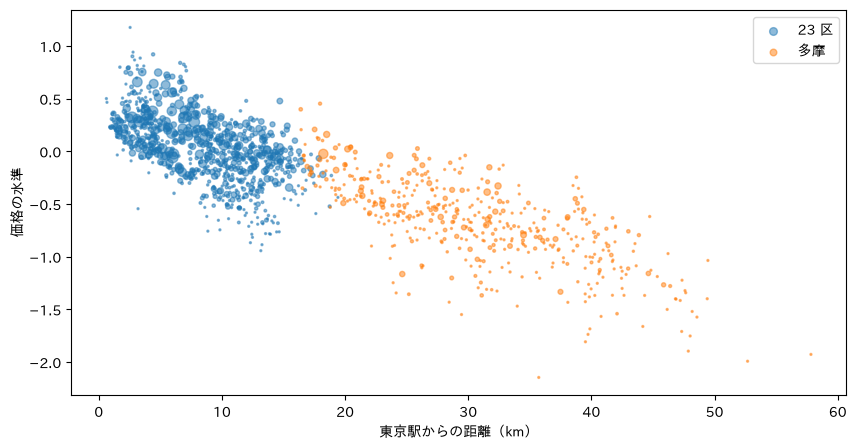

距離（log）と価格の水準の相関（30 件以上の地区）: -0.74


In [71]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, rows in district_map.groupby("地域"):
    ax.scatter(rows["距離"], rows["価格の水準"], s=np.clip(rows["件数"] / 20, 2, 60), alpha=0.5, label=name)
ax.set_xlabel("東京駅からの距離（km）")
ax.set_ylabel("価格の水準")
ax.legend()
plt.show()

big = district_map[district_map["件数"] >= 30]
print(f"距離（log）と価格の水準の相関（30 件以上の地区）: {np.corrcoef(np.log(big['距離']), big['価格の水準'])[0, 1]:.2f}")

- 東京駅から遠いほど価格の水準は下がる。相関は −0.74（距離は log）。
- 23 区の中（0〜18 km）でも、同じ距離で ±0.5 くらいばらつく。地図で見た方角の違いなどが、このばらつきに入っている。

### 近くの地区は似ているか

緯度経度が役に立つかは、「近くの地区どうしで価格の水準が似ているか」で決まる。各地区について、近い順に 5 つの地区（自分は除く）の価格の水準の平均を求め、自分の価格の水準と比べる。比べるために、同じ市区町村の平均とも比べる。

近くの 5 地区の平均: 相関 0.94 / ずれの二乗平均平方根 0.137
同じ市区町村のほかの地区の平均: 相関 0.91 / ずれの二乗平均平方根 0.168


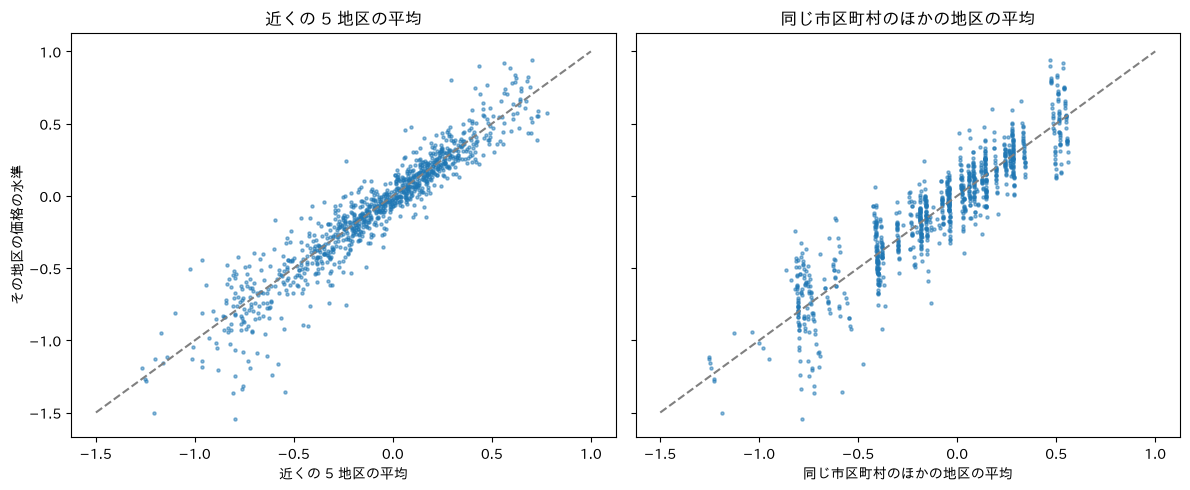

In [72]:
from sklearn.neighbors import NearestNeighbors

base = district_map[district_map["件数"] >= 30].copy()
coords = np.c_[base["緯度"] * KM_PER_DEG_LAT, base["経度"] * KM_PER_DEG_LON]
_, neighbors = NearestNeighbors(n_neighbors=6).fit(coords).kneighbors(coords)
base["近くの 5 地区の平均"] = base["価格の水準"].to_numpy()[neighbors[:, 1:]].mean(axis=1)

ward_of = train.groupby("地区")["市区町村名"].first()
base["市区町村名"] = ward_of.reindex(base.index)
ward_sum = base.groupby("市区町村名")["価格の水準"].transform("sum")
ward_n = base.groupby("市区町村名")["価格の水準"].transform("size")
base["同じ市区町村のほかの地区の平均"] = (ward_sum - base["価格の水準"]) / (ward_n - 1)

valid = base.dropna()
for col in ["近くの 5 地区の平均", "同じ市区町村のほかの地区の平均"]:
    err = valid["価格の水準"] - valid[col]
    print(f"{col}: 相関 {np.corrcoef(valid['価格の水準'], valid[col])[0, 1]:.2f} / ずれの二乗平均平方根 {np.sqrt((err**2).mean()):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, col in zip(axes, ["近くの 5 地区の平均", "同じ市区町村のほかの地区の平均"]):
    ax.scatter(valid[col], valid["価格の水準"], s=5, alpha=0.5)
    ax.plot([-1.5, 1], [-1.5, 1], color="gray", linestyle="--")
    ax.set_xlabel(col)
    ax.set_title(col)
axes[0].set_ylabel("その地区の価格の水準")
plt.tight_layout()
plt.show()

| 地区の価格の水準を、何で言い当てるか | 相関 | ずれ（二乗平均平方根） |
|---|---|---|
| **近い 5 地区の平均** | **0.94** | **0.137** |
| 同じ市区町村のほかの地区の平均 | 0.91 | 0.168 |

**近い地区の方が、同じ市区町村の地区より、その地区の価格の水準をよく言い当てる**。市区町村の境目をまたいでも、近い場所は似ている。

### Q13 のまとめ

- 位置参照情報（2023 年版）で、ほぼ全部の行（99.99%）に地区の緯度経度が付く。基準日は test 期間より前。
- 価格の水準は、東京駅からの距離で大きく変わる（相関 −0.74）。同じ距離でも方角で違い、東京駅の南西が一番高い。
- 近い地区どうしは価格の水準が似ていて、同じ市区町村の地区より似ている。

モデルでの使い方の案（工程 2. 特徴量）:

| 案 | 内容 | 期待 |
|---|---|---|
| **緯度・経度をそのまま数値の列にする** | 決定木が緯度・経度で分岐して、地図上の領域を切り分けられる | 件数の少ない地区（13.6% の行）も、近くの地区と一緒に扱える。目的変数を使わない |
| 東京駅からの距離・方角の列 | 緯度・経度を、価格と関係の深い形に直したもの | 決定木が少ない分岐で「都心からの遠さ」を表せる。ただし Q14 で、東京駅だけより主要駅（渋谷など）からの距離の方がよく合うと分かった。主要駅の選び方を決めてから試す |
| 近くの地区の相場の列 | 近い 5 地区の価格の水準の平均 | 上の比較で一番よく当たった。ただし価格を使うので、fold ごとに作る必要がある（target encoding と同じ注意） |

緯度・経度と距離・方角は価格を使わないので、fold ごとに作り直す必要がなく、すぐ試せる。

## Q14. 最寄駅をどう使うか

`最寄駅：名称`（630 種類）と `最寄駅：距離（分）` が、価格とどう関係するかを見る。駅の大きさや路線は元のデータにないので、外部データを足す。

### 使うデータ

国土交通省「国土数値情報 駅別乗降客数データ」の **2024 年度版（S12-25）**。駅ごと・路線ごとの 1 日の乗降客数と、駅の位置。

| 項目 | 内容 |
|---|---|
| 版 | S12-25。基準年度 2024 年度（2025 年 3 月まで）。ファイルには 2011〜2024 年度の乗降客数が入っていて、ここでは 2024 年度を使う |
| 基準日 | 2025 年第 2 四半期より前。test 期間の状態は含まない |
| 入手先 | https://nlftp.mlit.go.jp/ksj/gml/datalist/KsjTmplt-S12-2024.html （利用規約: https://nlftp.mlit.go.jp/ksj/other/agreement.html ） |

出典: 「国土数値情報（駅別乗降客数データ）」（国土交通省）（2024 年度版、S12-25）を加工して作成。駅ごとに、会社ごとの乗降客数を足した。

- 乗り換え駅は、路線ごとに行がある。同じ会社の複数の路線では、乗降客数は 1 つの行にだけ入っていて、ほかは 0 になっている。そこで、会社ごとに最大値を取ってから足す
- 会社によって数え方が違う（JR は乗車人員を 2 倍した値など）ので、乗降客数は駅の大きさの目安として log で使う

In [73]:
import json
import unicodedata

S12_URL = "https://nlftp.mlit.go.jp/ksj/gml/data/S12/S12-25/S12-25_GML.zip"
S12_ZIP = Path("../external_data/S12-25_GML.zip")
if not S12_ZIP.exists():
    urllib.request.urlretrieve(S12_URL, S12_ZIP)


def normalize_station(name):
    """駅名の表記ゆれ（異体字、「ケ」と「ヶ」）をそろえる。"""
    return unicodedata.normalize("NFKC", name).replace("ケ", "ヶ")


with zipfile.ZipFile(S12_ZIP) as z:
    features = json.load(z.open("S12-25_GML/UTF-8/S12-25_NumberOfPassengers.geojson"))["features"]
lines_raw = pd.DataFrame(
    [
        {
            "駅名": normalize_station(f["properties"]["S12_001"]),
            "駅コード": f["properties"]["S12_001g"],  # 乗り換え駅で同じ値になるグループコード
            "会社": f["properties"]["S12_002"],
            "路線": f["properties"]["S12_002"] + "・" + f["properties"]["S12_003"],
            "緯度": np.mean([c[1] for c in f["geometry"]["coordinates"]]),
            "経度": np.mean([c[0] for c in f["geometry"]["coordinates"]]),
            "乗降客数": f["properties"]["S12_061"] or 0,  # 2024 年度
        }
        for f in features
    ]
)
lines_raw = lines_raw[lines_raw["緯度"].between(35.3, 36.1) & lines_raw["経度"].between(138.8, 140.3)]  # 東京とその周辺

stations = lines_raw.groupby(["駅名", "駅コード"]).agg(
    緯度=("緯度", "mean"), 経度=("経度", "mean"), 路線数=("路線", "nunique"), 路線一覧=("路線", lambda s: sorted(set(s)))
)
stations["乗降客数"] = lines_raw.groupby(["駅名", "駅コード", "会社"])["乗降客数"].max().groupby(["駅名", "駅コード"]).sum()
stations = stations.reset_index()
stations.sort_values("乗降客数", ascending=False).head()

,駅名,駅コード,緯度,経度,路線数,路線一覧,乗降客数
963,渋谷,003922,35.658977,139.701647,7,"[京王電鉄・井の頭線, 東京地下鉄・11号線半蔵門線, 東京地下鉄・13号線副都心線, 東京...",2897703
651,新宿,003700,35.689796,139.699930,7,"[京王電鉄・京王線, 小田急電鉄・小田原線, 東京地下鉄・4号線丸ノ内線, 東京都・10号線...",2713386
918,池袋,003390,35.729807,139.711077,6,"[東京地下鉄・4号線丸ノ内線, 東京地下鉄・8号線有楽町線, 東日本旅客鉄道・山手線, 東日...",2364011
867,横浜,004633,35.465846,139.622079,7,"[京浜急行電鉄・本線, 東急電鉄・東横線, 東日本旅客鉄道・東海道線, 東日本旅客鉄道・根岸...",1936287
289,北千住,003260,35.749491,139.805065,5,"[東京地下鉄・2号線日比谷線, 東京地下鉄・9号線千代田線, 東日本旅客鉄道・常磐線, 東武...",1434911


### 最寄駅と結合できるか

`最寄駅：名称` は「大森(東京)」のように、同じ名前の駅を区別するかっこが付いている。かっこを外して駅名で探し、同じ名前の駅が複数あるときは、その駅を最寄駅とする取引の地区（Q13 の緯度経度）の平均に一番近い駅を選ぶ。

In [74]:
station_table = train.groupby("最寄駅：名称").agg(緯度=("緯度", "mean"), 経度=("経度", "mean"), 件数=("緯度", "size"))
station_table["駅名"] = station_table.index.str.replace(r"\(.*\)$", "", regex=True).map(normalize_station)

picked, gap_km = [], []
for name, row in station_table.iterrows():
    cand = stations[stations["駅名"] == row["駅名"]]
    dist = np.hypot((cand["緯度"] - row["緯度"]) * KM_PER_DEG_LAT, (cand["経度"] - row["経度"]) * KM_PER_DEG_LON)
    picked.append(dist.idxmin() if len(cand) else None)
    gap_km.append(dist.min() if len(cand) else np.nan)
station_table["駅の行"] = picked
station_table["地区とのずれ_km"] = gap_km
station_table = station_table.join(stations[["路線数", "路線一覧", "乗降客数"]], on="駅の行")

print(f"結合できた駅: {station_table['駅の行'].notna().sum()} / {len(station_table)}")
print(f"地区の平均とのずれの中央値: {station_table['地区とのずれ_km'].median():.2f} km")
print("乗降客数が 0 の駅（2024 年度のデータなし）:", station_table.index[station_table["乗降客数"] == 0].tolist())

for df in (train, test):
    df["乗降客数"] = df["最寄駅：名称"].map(station_table["乗降客数"]).replace(0, np.nan)
    df["路線数"] = df["最寄駅：名称"].map(station_table["路線数"])
print(f"乗降客数が付いた行: train {train['乗降客数'].notna().mean():.2%} / test {test['乗降客数'].notna().mean():.2%}")

結合できた駅: 630 / 630
地区の平均とのずれの中央値: 0.29 km
乗降客数が 0 の駅（2024 年度のデータなし）: ['とうきょうスカイツリー', '二俣尾', '古里(東京)', '宮ノ平', '小宮', '東福生', '箱根ケ崎']
乗降客数が付いた行: train 99.16% / test 99.85%


### 駅からの距離（徒歩分）と価格

駅から遠い物件ほど安いか。そのまま比べると、駅から遠い物件は郊外に多いので、場所の違いが混ざる。**同じ地区の中で**比べる（価格の水準から地区の平均を引いた値を、徒歩分ごとに平均する）。

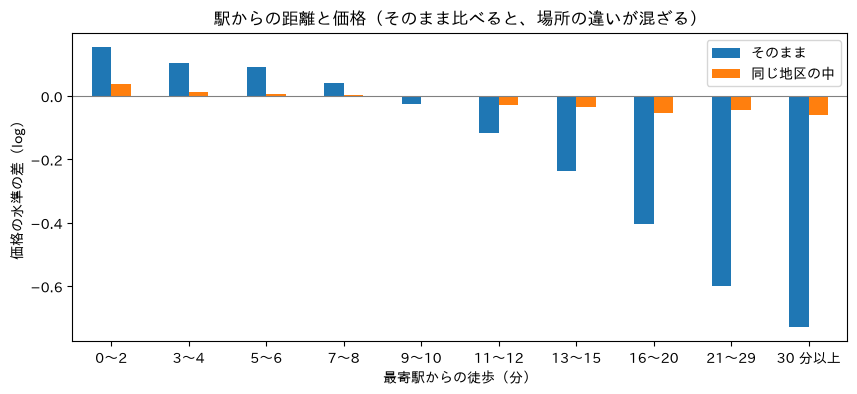

,件数,そのまま,同じ地区の中
最寄駅：距離（分）,,,
0〜2,22096,0.155,0.039
3〜4,38080,0.103,0.013
5〜6,40243,0.091,0.006
7〜8,32109,0.041,0.003
9〜10,25907,-0.026,-0.004
11〜12,15641,-0.117,-0.028
13〜15,14030,-0.236,-0.035
16〜20,7558,-0.404,-0.054
21〜29,2293,-0.599,-0.044


In [75]:
walk_min = pd.to_numeric(train["最寄駅：距離（分）"], errors="coerce")
walk_band = (
    pd.cut(walk_min, [-1, 2, 4, 6, 8, 10, 12, 15, 20, 29], labels=["0〜2", "3〜4", "5〜6", "7〜8", "9〜10", "11〜12", "13〜15", "16〜20", "21〜29"])
    .astype(object)
    .fillna("30 分以上")
)
within_district = resid_loc - resid_loc.groupby(train["地区"]).transform("mean")
walk_table = pd.DataFrame(
    {"件数": walk_band.value_counts(), "そのまま": resid_loc.groupby(walk_band).mean(), "同じ地区の中": within_district.groupby(walk_band).mean()}
).reindex(["0〜2", "3〜4", "5〜6", "7〜8", "9〜10", "11〜12", "13〜15", "16〜20", "21〜29", "30 分以上"])

fig, ax = plt.subplots(figsize=(10, 4))
walk_table[["そのまま", "同じ地区の中"]].plot.bar(ax=ax)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("最寄駅からの徒歩（分）")
ax.set_ylabel("価格の水準の差（log）")
ax.set_title("駅からの距離と価格（そのまま比べると、場所の違いが混ざる）")
plt.xticks(rotation=0)
plt.show()
walk_table.round(3)

- そのまま比べると、徒歩 0〜2 分と 21〜29 分で 0.75（約 2 倍）違う。ただしこの大部分は「駅から遠い物件は郊外に多い」という場所の違い。
- **同じ地区の中で比べると、差は 0.04（0〜2 分）〜 −0.05（16〜20 分）で、約 1 割**。駅からの距離そのものの効果は、場所の効果よりずっと小さい。
- 徒歩分は今のモデルに数値（`駅距離_分`、PR #3）で入っている。地区とあわせて決定木が分けられるので、新しく作るものはない。

### 駅の大きさ（乗降客数・路線数）と価格

駅ごとに価格の水準を平均して（30 件以上の駅）、乗降客数・路線数と比べる。ここでも、そのままと、同じ地区の中の 2 通りで見る。

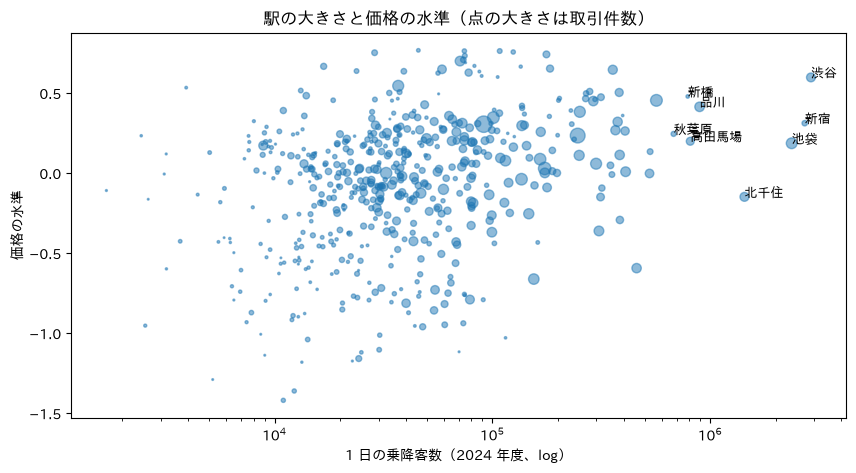

乗降客数との相関（534 駅）: そのまま 0.32 / 同じ地区の中 0.21
路線数との相関（534 駅）: そのまま 0.22 / 同じ地区の中 0.11


,駅の数,取引件数,価格の水準,同じ地区の中
乗降客数の帯,,,,
1 万未満,52,5635,-0.243,-0.013
1〜3 万,183,46679,-0.177,-0.009
3〜10 万,215,94900,-0.049,0.000
10〜30 万,57,33963,0.196,0.007
30 万以上,27,18492,0.161,0.015


In [76]:
station_level = (
    pd.DataFrame({"駅": train["最寄駅：名称"], "価格の水準": resid_loc, "同じ地区の中": within_district})
    .groupby("駅")
    .agg(件数=("価格の水準", "size"), 価格の水準=("価格の水準", "mean"), 同じ地区の中=("同じ地区の中", "mean"))
    .join(station_table[["乗降客数", "路線数"]])
)
big_stations = station_level[(station_level["件数"] >= 30) & (station_level["乗降客数"] > 0)].copy()
big_stations["乗降客数の帯"] = pd.cut(big_stations["乗降客数"], [0, 1e4, 3e4, 1e5, 3e5, 1e8], labels=["1 万未満", "1〜3 万", "3〜10 万", "10〜30 万", "30 万以上"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(big_stations["乗降客数"], big_stations["価格の水準"], s=big_stations["件数"] / 20, alpha=0.5)
for name in big_stations.nlargest(8, "乗降客数").index:
    ax.annotate(name, (big_stations.loc[name, "乗降客数"], big_stations.loc[name, "価格の水準"]), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("1 日の乗降客数（2024 年度、log）")
ax.set_ylabel("価格の水準")
ax.set_title("駅の大きさと価格の水準（点の大きさは取引件数）")
plt.show()

for col in ["乗降客数", "路線数"]:
    x = np.log10(big_stations[col]) if col == "乗降客数" else big_stations[col]
    print(f"{col}との相関（{len(big_stations)} 駅）: そのまま {np.corrcoef(x, big_stations['価格の水準'])[0, 1]:.2f} / 同じ地区の中 {np.corrcoef(x, big_stations['同じ地区の中'])[0, 1]:.2f}")
big_stations.groupby("乗降客数の帯", observed=True).agg(
    駅の数=("件数", "size"), 取引件数=("件数", "sum"), 価格の水準=("価格の水準", "mean"), 同じ地区の中=("同じ地区の中", "mean")
).round(3)

- 大きい駅ほど価格の水準は高いが、相関は 0.32 と弱い。渋谷は高く、北千住は平均くらいと、大きな駅でも周りの価格はばらばら。
- **同じ地区の中では、乗降客数の差はほとんど効かない**。駅ごとに見ると相関は 0.21 あるが、差の大きさは 1 万未満の駅 −0.01、30 万以上の駅 +0.02 で、2〜3% しかない。同じ地区の中で、大きい駅を最寄駅とする物件が特に高いわけではない。
- 大きい駅ほど高いのは、主に「大きい駅は都心にある」という場所の違い。場所は地区・緯度経度で表せるので、乗降客数を足して増える情報は少なそう。

### 東京駅以外の都心からの距離

Q13 では東京駅からの距離だけを使ったが、地図では一番高い場所は東京駅の南西だった。乗降客数の多い主要駅（東京・新宿・渋谷・池袋・品川）それぞれからの距離と、一番近い主要駅までの距離を、地区の価格の水準と比べる。

In [77]:
HUBS = ["東京", "新宿", "渋谷", "池袋", "品川"]
hub_points = stations[stations["駅名"].isin(HUBS)].sort_values("乗降客数").drop_duplicates("駅名", keep="last").set_index("駅名")

hub_base = district_map[district_map["件数"] >= 30].copy()
for hub in HUBS:
    lat, lon = hub_points.loc[hub, ["緯度", "経度"]]
    hub_base[f"{hub}駅から"] = np.hypot((hub_base["緯度"] - lat) * KM_PER_DEG_LAT, (hub_base["経度"] - lon) * KM_PER_DEG_LON)
hub_base["一番近い主要駅から"] = hub_base[[f"{h}駅から" for h in HUBS]].min(axis=1)

hub_corr = pd.DataFrame(
    {
        "全体": {c: np.corrcoef(np.log(hub_base[c] + 0.5), hub_base["価格の水準"])[0, 1] for c in [f"{h}駅から" for h in HUBS] + ["一番近い主要駅から"]},
        "23 区だけ": {
            c: np.corrcoef(np.log(rows[c] + 0.5), rows["価格の水準"])[0, 1]
            for rows in [hub_base[hub_base["地域"] == "23 区"]]
            for c in [f"{h}駅から" for h in HUBS] + ["一番近い主要駅から"]
        },
    }
)
hub_corr.round(2).rename_axis("距離（log）と価格の水準の相関")

,全体,23 区だけ
距離（log）と価格の水準の相関,,
東京駅から,-0.75,-0.54
新宿駅から,-0.82,-0.68
渋谷駅から,-0.86,-0.82
池袋駅から,-0.60,-0.20
品川駅から,-0.83,-0.73
一番近い主要駅から,-0.83,-0.72


（距離は 0 km の地区で log が発散しないように 0.5 km を足してから log を取った）

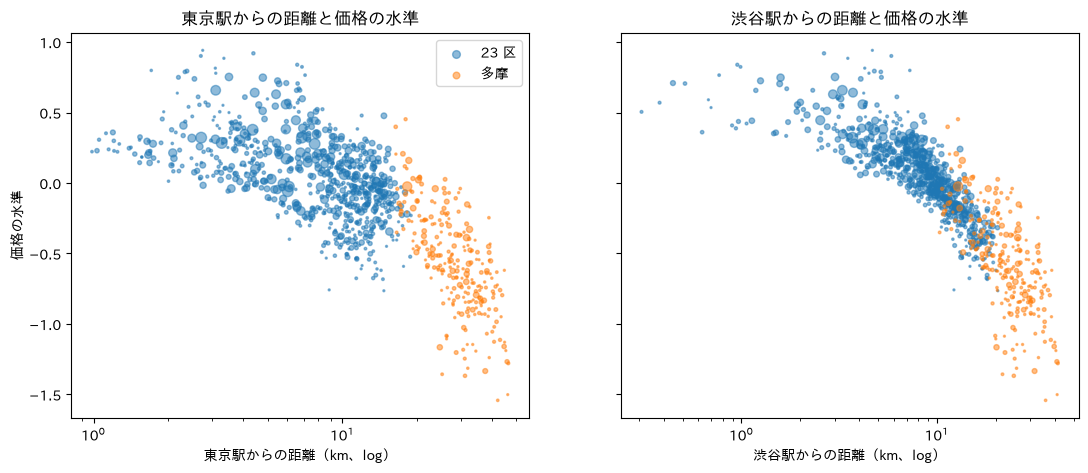

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, col in zip(axes, ["東京駅から", "渋谷駅から"]):
    for name, rows in hub_base.groupby("地域"):
        ax.scatter(rows[col], rows["価格の水準"], s=np.clip(rows["件数"] / 20, 2, 60), alpha=0.5, label=name)
    ax.set_xscale("log")
    ax.set_xlabel(f"{col}の距離（km、log）")
    ax.set_title(f"{col}の距離と価格の水準")
axes[0].set_ylabel("価格の水準")
axes[0].legend()
plt.show()

- **東京駅からの距離より、渋谷駅からの距離の方が価格の水準とよく合う**（相関 −0.75 → −0.86）。一番近い主要駅からの距離も −0.83。23 区だけで見ると差はもっと大きく、東京駅 −0.54 に対して渋谷駅 −0.82、一番近い主要駅 −0.72。散布図でも、渋谷駅からの距離の方が点が 1 本の線に近く並ぶ。
- Q13 の地図で「一番高いのは東京駅の南西」だったのと合う。東京駅だけを都心とみなすのは、あまりよくない。
- #9 で東京駅からの距離・方角を試す前に、主要駅からの距離に変えるか、複数の主要駅からの距離をそれぞれ列にする方がよさそう。

### 路線で分ける

駅をグループに分ける自然な方法は、路線。駅を通る路線ごとに、その駅を最寄駅とする取引の価格の水準を平均する（乗り換え駅の取引は、通る路線すべてに数える。取引が 1,500 件以上の路線）。

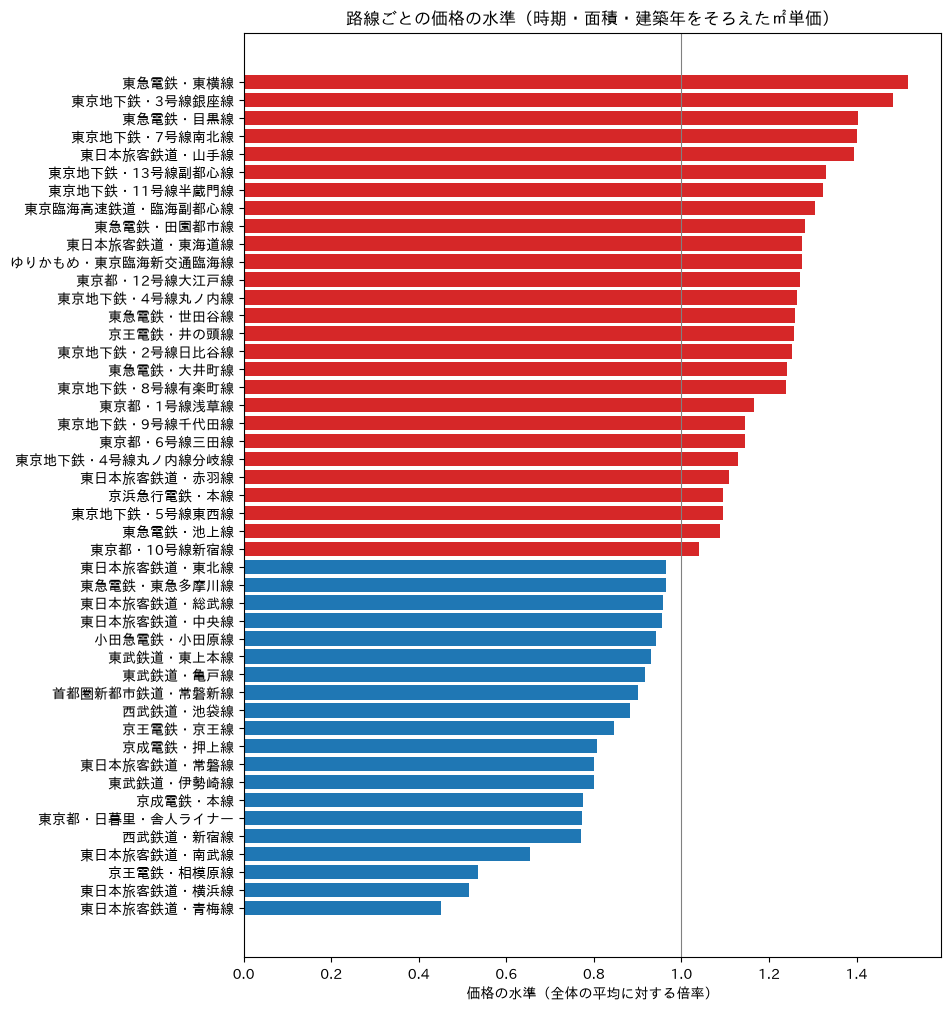

In [79]:
by_line = (
    pd.DataFrame({"路線": train["最寄駅：名称"].map(station_table["路線一覧"]), "価格の水準": resid_loc})
    .explode("路線")
    .dropna()
    .groupby("路線")
    .agg(件数=("価格の水準", "size"), 価格の水準=("価格の水準", "mean"))
)
by_line = by_line[by_line["件数"] >= 1500].sort_values("価格の水準")

fig, ax = plt.subplots(figsize=(9, 12))
ax.barh(by_line.index, np.exp(by_line["価格の水準"]), color=np.where(by_line["価格の水準"] > 0, "C3", "C0"))
ax.axvline(1, color="gray", linewidth=0.8)
ax.set_xlabel("価格の水準（全体の平均に対する倍率）")
ax.set_title("路線ごとの価格の水準（時期・面積・建築年をそろえた㎡単価）")
plt.show()

- 一番高いのは **東急東横線（1.52 倍）・銀座線（1.48 倍）・東急目黒線・南北線・山手線**、一番低いのは **青梅線（0.45 倍）・横浜線・京王相模原線・南武線**。高い路線は都心から南西へ延びる路線、低い路線は多摩・郊外を走る路線が多い。
- 同じ京王電鉄でも、井の頭線 1.26 倍・京王線 0.84 倍・相模原線 0.53 倍と分かれる。会社より路線で見た方がよい。
- ただし、路線の価格の水準は、その路線が通る場所の平均でしかない。路線は駅のまとめ方の 1 つで、駅・地区より粗い。

### Q14 のまとめ

| 見たこと | 結果 | 特徴量にするか |
|---|---|---|
| 駅からの徒歩分 | 同じ地区の中で約 1 割の差 | すでに数値で入っている（`駅距離_分`）。新しく作るものはない |
| 駅の乗降客数・路線数 | 大きい駅ほど高いが、同じ地区の中ではほとんど差がない | 優先度は低い。場所の情報は地区・緯度経度で入る |
| 主要駅からの距離 | 東京駅だけより、渋谷駅・一番近い主要駅の方がよく合う（−0.75 → −0.83〜−0.86。23 区だけでは −0.54 → −0.72〜−0.82） | **#9 の「東京駅からの距離・方角」を、主要駅からの距離に置き換える** |
| 路線 | 東横線 1.52 倍〜青梅線 0.45 倍 | 駅より粗いまとめ方。件数の少ない駅を補えるかもしれないが、地区・緯度経度と重なる |

主要駅の位置は、上の駅別乗降客数データ（国土数値情報）から取った。主要駅 5 つの緯度経度だけを使うなら、コードに数字を書くだけで済む。